# IndiaDrive: Camera-Only Self-Driving for Indian Traffic, Trained and Tested Entirely in CARLA

**Capstone Group 47 · Chaos-Curriculum Distillation · CARLA 0.9.16 · Google Colab Pro**

This notebook builds, trains and evaluates a camera-only driving policy for dense, lane-free Indian traffic. All data, training and testing come from the CARLA simulator.

The notebook is split into independent steps. Each step header states the Colab runtime it needs, saves everything it produces to Google Drive, and can be re-run safely because finished work is detected and skipped. You can therefore pick the cheapest runtime for every step and spend GPU compute units only where a GPU is actually required.

### The pipeline
| # | Step | What it produces |
|---|---|---|
| 1 | Install the code package | The `indiadrive` Python package on Drive |
| 2 | Cache CARLA (optional) | The CARLA 0.9.16 archive on Drive, so later GPU sessions skip the download |
| 3 | Simulator gates | Proof that rendering works, the controller tracks a path, and the expert drives well |
| 4 | Expert data collection | Episodes recorded at every chaos level k from 0 to 1 |
| 5 | Dataset index | Train/val split, speed bins, style audit, statistics |
| 6 | Student training | Two-stage training with a chaos curriculum and mirror (left-hand-traffic) augmentation |
| 7 | Guard calibration | Conformal depth and lateral safety margins for each class of road user |
| 8 | Closed-loop evaluation | IndiaBench: chaos sweep, blind test, scenario suite, guard ablations |
| 9 | Failure-targeted DAgger | On-policy data where the student fails but the expert succeeds, then fine-tuning |
| 10 | Report | Tables, LaTeX and black-and-white paper figures |
| 11 | Visualisations | Dataset gallery and clips, driving videos, before vs after training comparison |

### How to run it
1. Open **Runtime → Change runtime type** and select the runtime shown in the step header. Turn on **High-RAM** where the header says so.
2. Run **Section 0** at the start of every new runtime. It mounts Drive, loads the code and shows which steps are already done.
3. Run the step with **Run cells in section** from the section header menu.
4. When the step prints `STEP … SAVED TO DRIVE`, switch the runtime for the next step.

Start with `PROFILE = "smoke"` and run steps 1 to 10 end to end (about 3 units) to prove the plumbing. Then switch to `PROFILE = "colab"`.

### Runtime and compute plan for the `colab` profile
| Step | Runtime | Time | Compute units |
|---|---|---|---|
| 0 Start session | any | 1 min | – |
| 1 Code package | CPU | 3 min | 0.01 |
| 2 Cache CARLA (optional) | CPU | 25 min | 0.04 |
| 3 Simulator gates | T4 GPU + High-RAM | 30–40 min | 0.7 |
| 4 Expert data (60 episodes) | T4 GPU + High-RAM | 3–4 h | 4–5 |
| 5 Dataset index | CPU | 5 min | 0.01 |
| 6 Training | L4 GPU | 2–3 h | 4–5 |
| 7 Guard calibration | CPU | 15 min | 0.03 |
| 8 Evaluation (student, expert, blind, scenarios) | T4 GPU + High-RAM | 7–9 h | 8–11 |
| 9 DAgger round (collect, index, fine-tune, evaluate) | T4 / CPU / L4 / T4 | 5–7 h | 7–10 |
| 10 Report | CPU | 5 min | 0.01 |
| 11 Visualisations (gallery and driving videos) | CPU, then T4 GPU + High-RAM | 1 h | ≈1 |

The main pipeline costs about **25–33 units**. Each training ablation in the appendix adds about 6 units, so the full study fits within 120 units. The real cost of every session is logged to `MyDrive/IndiaDrive/sessions.csv`.

### Requirements
- Colab Pro, with access to T4 or L4 GPUs and High-RAM.
- Free Google Drive space: about 10 GB for the `colab` profile, plus about 20 GB more if you cache CARLA in Step 2.
- Keep the tab open during long steps. If Colab disconnects, run Section 0 and the same step again; it resumes where it stopped.

### Drive layout
```
MyDrive/IndiaDrive/
  code/indiadrive/            Python package written by Step 1
  cache/                      CARLA archive and ImageNet weights
  data/<profile>/expert/      shards/*.tar (one per episode) and meta/ (labels only)
  data/<profile>/dagger_rN/   DAgger round N
  index/<profile>/            dataset index, speed bins, statistics
  runs/<profile>/<run>/       checkpoints and training log
  calib/<profile>/            conformal guard calibration
  eval/<profile>/<tag>/       one JSON file per evaluated route (resumable)
  reports/<profile>/          tables, LaTeX, figures, dataset gallery
  reports/<profile>/videos/   driving videos, dataset clips, comparison videos
  status_<profile>.json       which steps are done
  sessions.csv                runtime and compute units per session
```

## 0 · Start every session here
**Runtime: any · 1 min**

Set `PROFILE` to `smoke` first, then `colab`, and `full` only if you have spare units. Leave `RUN` as `main`, or set it to an ablation name from Appendix A.

The first time, Colab asks for permission to mount Google Drive. This cell also tells you whether you are on the right runtime for the step you are about to run.

In [ ]:
PROFILE = "smoke"
RUN = "main"

import os
import sys
import shutil
from google.colab import drive

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/IndiaDrive"
os.makedirs(f"{ROOT}/code/indiadrive", exist_ok=True)


def load_package(profile=None, run=None):
    global S, cfg
    shutil.rmtree("/content/code", ignore_errors=True)
    shutil.copytree(f"{ROOT}/code", "/content/code")
    if "/content/code" not in sys.path:
        sys.path.insert(0, "/content/code")
    for name in [m for m in sys.modules if m == "indiadrive" or m.startswith("indiadrive.")]:
        del sys.modules[name]
    from indiadrive.colab import Session
    S = Session(profile or PROFILE, run or RUN)
    cfg = S.cfg
    return S


if os.path.isfile(f"{ROOT}/code/indiadrive/colab.py"):
    load_package()
    S.status()
else:
    print("First run: execute Step 1 on a CPU runtime to install the code package on Drive.")

Mounted at /content/drive
profile=smoke run=main | runtime L4 NVIDIA L4, 23034 MiB | RAM 55.5 GB | 12 CPUs | disk free 207.6 GB | Python 3.13.15
0_project              -
1_code                 done 2026-10-16 21:05 on CPU
2_carla_cache          done 2026-10-16 21:08 on CPU
3_gates                -
4_collect              -
5_index                -
6_train                -
7_calibrate            -
8_eval                 -
9_dagger               -
10_report              -

compute units used so far (smoke): 0.0


## Step 1 · Install the code package on Drive
**Runtime: CPU · 3 min · ≈0.01 units · once, and again after any code change**

Every cell in this section writes one module of the `indiadrive` package to `MyDrive/IndiaDrive/code`. Later steps copy the package from Drive, so it only has to be written once. Use **Run cells in section**, then run the self-test at the end.

| Module | Role |
|---|---|
| `__init__.py` | Package marker |
| `config.py` | Every setting, profiles, ablations, Drive paths |
| `geometry.py` | Coordinate frames, path resampling, lateral offsets |
| `sim.py` | CARLA server lifecycle, stereo camera rig, sensors |
| `traffic.py` | India traffic layer: chaos dial, weaving two-wheelers, scripted events, scenario suite |
| `control.py` | Pure pursuit and PID (never learned) |
| `expert.py` | Privileged expert v2: lane-free nudging, creeping, braking only for visible hazards |
| `collect.py` | Expert data collection and packing to Drive |
| `data.py` | Dataset index, loader, mirror augmentation, VRU occupancy labels |
| `model.py` | RegNetY + depth, then a 256-query scene bus with memory, then heads including VRU future occupancy |
| `losses.py` | Perception, motion and VRU losses |
| `train.py` | Two-stage training, chaos curriculum, resumable checkpoints |
| `guard.py` | Stereo safety guard and conformal calibration |
| `agent.py` | Runtime agent from cameras to controls (L0 to L6) |
| `evaluate.py` | Closed-loop IndiaBench metrics |
| `dagger.py` | Failure-targeted DAgger |
| `runner.py` | Command-line entry point inside the simulator environment |
| `colab.py` | Runtime checks, simulator setup, data staging, compute-unit log |
| `report.py` | Tables, LaTeX, figures |
| `viz.py` | Dataset gallery, driving videos with chase camera, before/after comparison, trajectory figures |
| `selftest.py` | Quick CPU check of the package |

In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/__init__.py
__version__ = "1.0.0"

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/__init__.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/config.py
import json
import os
from dataclasses import dataclass, asdict, fields

ROOT = "/content/drive/MyDrive/IndiaDrive"
WORK = "/content/work"


@dataclass
class Config:
    profile: str = "colab"
    run: str = "main"
    root: str = ROOT
    work: str = WORK
    carla_root: str = "/content/carla"
    carla_url: str = "https://downloads.carlasim.com/Linux/CARLA_0.9.16.tar.gz"
    carla_version: str = "0.9.16"

    host: str = "127.0.0.1"
    port: int = 2000
    tm_port: int = 8000
    fixed_delta: float = 0.05
    record_every: int = 2
    quality: str = "Low"
    towns_train: tuple = ("Town01", "Town03", "Town04", "Town10HD")
    towns_eval: tuple = ("Town02", "Town05")
    lht_twin: bool = False
    ego_blueprint: str = "vehicle.lincoln.mkz_2020"

    img_w: int = 704
    img_h: int = 256
    fov: float = 100.0
    cam_x: float = 1.3
    cam_z: float = 1.45
    cam_pitch: float = 0.0
    stereo_baseline: float = 0.40
    jpeg_quality: int = 85
    rig_jitter_every: int = 40
    rig_jitter_y: float = 0.8
    rig_jitter_yaw: float = 8.0
    rig_jitter_prob: float = 0.5

    chaos_train: tuple = (0.0, 0.25, 0.5, 0.75, 1.0)
    chaos_eval: tuple = (0.0, 0.25, 0.5, 0.75, 1.0)
    n_vehicles: tuple = (30, 70)
    n_walkers: tuple = (20, 80)
    share_two_wheeler: tuple = (0.15, 0.55)
    share_heavy: tuple = (0.10, 0.18)
    share_auto: tuple = (0.0, 0.12)
    gap_min: tuple = (2.5, 0.5)
    gap_max: tuple = (4.0, 1.5)
    speed_diff_min: tuple = (-5.0, -30.0)
    speed_diff_max: tuple = (10.0, 20.0)
    ignore_lights: tuple = (0.0, 6.0)
    lane_change: tuple = (2.0, 20.0)
    weave_offset: tuple = (0.2, 1.4)
    weave_every_s: float = 3.0
    cross_factor: tuple = (0.02, 0.5)
    rate_auto_stop: tuple = (0.0, 1.0)
    rate_bus_stop: tuple = (0.0, 0.4)
    rate_wrong_way: tuple = (0.0, 0.5)
    rate_jaywalk: tuple = (0.0, 1.2)
    rate_debris: tuple = (0.0, 1.5)
    rate_parked: tuple = (0.2, 1.5)

    expert_max_speed: float = 11.0
    expert_lat_acc: float = 2.0
    expert_decel: float = 3.0
    expert_visible_px: int = 30
    expert_near_field: float = 6.0
    expert_memory_s: float = 2.0
    expert_max_nudge: float = 1.2
    expert_nudge_margin: float = 0.5
    expert_creep_margin: float = 0.25
    expert_creep_speed: float = 1.5
    noise_prob: float = 0.15
    noise_steer: float = 0.25
    noise_duration: tuple = (0.5, 1.2)

    episodes_per_level: int = 3
    episode_max_ticks: int = 1500
    route_len: tuple = (300.0, 900.0)
    filter_keep_rest: float = 0.14
    filter_dv: float = 0.1
    filter_dang_deg: float = 0.5

    d_model: int = 256
    n_queries: int = 256
    bus_blocks: int = 4
    n_heads: int = 8
    depth_bins: int = 48
    depth_min: float = 1.0
    depth_max: float = 60.0
    seg_classes: int = 8
    obj_classes: int = 3
    mem_topk: int = 64
    mem_ticks: int = 4
    mem_stride: int = 2
    n_path: int = 10
    path_spacing: float = 1.0
    path_start: float = 2.5
    n_speed_bins: int = 8
    speed_bins: tuple = (0.0, 2.0, 4.0, 5.5, 7.0, 8.5, 10.0, 11.0)
    n_commands: int = 6
    use_target_point: bool = True
    ego_dropout: float = 0.25
    pretrained_backbone: bool = True
    use_right_in_bus: bool = False
    vru_head: bool = True
    bev_x: tuple = (0.0, 40.0)
    bev_y: tuple = (-12.5, 12.5)
    bev_res: float = 1.25
    bev_horizons: tuple = (0, 10, 20)

    train_history: int = 3
    batch_size: int = 8
    num_workers: int = 0
    lr: float = 3e-4
    lr_backbone: float = 1e-4
    weight_decay: float = 0.01
    epochs_stage1: int = 3
    epochs_stage2: int = 12
    dagger_epochs: int = 4
    curriculum: bool = True
    curriculum_frac: float = 0.6
    curriculum_hard_weight: float = 0.15
    mirror_prob: float = 0.3
    grad_clip: float = 1.0
    w_path: float = 1.0
    w_speed: float = 1.0
    w_depth: float = 0.5
    w_seg: float = 0.5
    w_obj: float = 1.0
    w_vru: float = 0.5
    seed: int = 0

    guard_mode: str = "conformal"
    guard_source: str = "sgbm"
    guard_alpha: float = 0.05
    guard_grid_res: float = 0.25
    guard_x_max: float = 40.0
    guard_y_max: float = 10.0
    guard_min_pts: int = 6
    guard_margin: float = 0.35
    guard_buffer: float = 2.5
    guard_decel: float = 4.0
    guard_ttc: float = 1.2
    guard_reaction_s: float = 1.0
    ego_half_width: float = 1.0
    ego_half_length: float = 2.4
    pp_a: float = 0.098
    pp_b: float = 0.192
    pp_min_lookahead: float = 2.5
    pid_kp: float = 0.6
    pid_ki: float = 0.05
    pid_kd: float = 0.05
    max_throttle: float = 0.75
    brake_ratio: float = 1.1

    eval_routes_per_town: int = 4
    eval_seeds: tuple = (0, 1, 2)
    blocked_timeout_s: float = 90.0
    near_miss_m: float = 0.5
    expert_gate_ds: float = 80.0

    dagger_probes_per_town: int = 6
    dagger_fail_weight: float = 3.0
    dagger_fail_window_s: float = 10.0

    def update(self, **kw):
        names = {f.name for f in fields(self)}
        for k, v in kw.items():
            if k not in names:
                raise KeyError(f"unknown config field: {k}")
            setattr(self, k, tuple(v) if isinstance(v, list) else v)
        return self

    def to_json(self, path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "w") as f:
            json.dump(asdict(self), f, indent=1)

    @property
    def p(self):
        return Paths(self)


class Paths:
    def __init__(self, cfg):
        r, w, pr = cfg.root, cfg.work, cfg.profile
        self.code = f"{r}/code"
        self.cache = f"{r}/cache"
        self.carla_tar = f"{r}/cache/CARLA_{cfg.carla_version}.tar.gz"
        self.torch_home = f"{r}/cache/torch"
        self.data = f"{r}/data/{pr}"
        self.index = f"{r}/index/{pr}"
        self.runs = f"{r}/runs/{pr}"
        self.run = f"{r}/runs/{pr}/{cfg.run}"
        self.calib = f"{r}/calib/{pr}/guard.json"
        self.eval = f"{r}/eval/{pr}"
        self.gates = f"{r}/gates/{pr}"
        self.reports = f"{r}/reports/{pr}"
        self.sessions = f"{r}/sessions.csv"
        self.local_data = f"{w}/data"
        self.local_tmp = f"{w}/tmp"

    def dataset(self, name):
        return f"{self.data}/{name}"


PROFILES = {
    "smoke": dict(towns_train=("Town01",), towns_eval=("Town02",), chaos_train=(0.0, 1.0), chaos_eval=(0.0, 1.0),
                  episodes_per_level=2, episode_max_ticks=500, epochs_stage1=1, epochs_stage2=2, dagger_epochs=1,
                  eval_routes_per_town=2, eval_seeds=(0,), n_vehicles=(20, 35), n_walkers=(15, 30),
                  dagger_probes_per_town=2),
    "colab": dict(),
    "full": dict(episodes_per_level=6, epochs_stage2=20, dagger_epochs=6, dagger_probes_per_town=12),
}

ABLATIONS = {
    "main": dict(),
    "no_vru_head": dict(vru_head=False),
    "no_curriculum": dict(curriculum=False),
    "no_mirror": dict(mirror_prob=0.0),
    "no_memory": dict(mem_ticks=0),
    "no_ego_dropout": dict(ego_dropout=0.0),
    "queries_128": dict(n_queries=128),
    "chaos0_only": dict(chaos_train=(0.0,)),
}

EVAL_ONLY = {"guard_corridor": dict(guard_mode="corridor"), "guard_off": dict(guard_mode="off"),
             "guard_carla_depth": dict(guard_source="carla_depth")}


def load_cfg(profile="colab", run="main", root=ROOT, **extra):
    cfg = Config(profile=profile, run=run, root=root)
    cfg.update(**PROFILES[profile])
    base = run.split("+")[0]
    if base in ABLATIONS:
        cfg.update(**ABLATIONS[base])
    bins = f"{cfg.p.index}/speed_bins.json"
    if os.path.isfile(bins):
        with open(bins) as f:
            b = json.load(f)
        if len(b) == cfg.n_speed_bins:
            cfg.update(speed_bins=tuple(b))
    if extra:
        cfg.update(**extra)
    return cfg


def lerp(pair, k):
    return float(pair[0] + (pair[1] - pair[0]) * k)

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/config.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/geometry.py
import math
import numpy as np


def carla_xy_to_rh(x, y):
    return x, -y


def carla_yaw_to_rh(yaw_deg):
    return -math.radians(yaw_deg)


def carla_transform_to_pose(tf):
    x, y = carla_xy_to_rh(tf.location.x, tf.location.y)
    return np.array([x, y, carla_yaw_to_rh(tf.rotation.yaw)], dtype=np.float64)


def rot2(a):
    c, s = math.cos(a), math.sin(a)
    return np.array([[c, -s], [s, c]])


def world_to_ego(pts, pose):
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 2)
    return (pts - pose[:2]) @ rot2(pose[2])


def ego_to_world(pts, pose):
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 2)
    return pts @ rot2(pose[2]).T + pose[:2]


def wrap(a):
    return (a + math.pi) % (2 * math.pi) - math.pi


def compose(pose, offset):
    xy = ego_to_world(offset[:2], pose)[0]
    return np.array([xy[0], xy[1], wrap(pose[2] + offset[2])])


def relative_pose(pose_from, pose_to):
    xy = world_to_ego(pose_to[:2], pose_from)[0]
    return np.array([xy[0], xy[1], wrap(pose_to[2] - pose_from[2])])


def intrinsics(w, h, fov_deg):
    f = w / (2.0 * math.tan(math.radians(fov_deg) / 2.0))
    return np.array([[f, 0, w / 2.0], [0, f, h / 2.0], [0, 0, 1.0]])


def T_ego_cam(x, y, z, yaw_rad=0.0, pitch_rad=0.0):
    m0 = np.array([[0, 0, 1], [-1, 0, 0], [0, -1, 0]], dtype=np.float64)
    a = -pitch_rad
    ry = np.array([[math.cos(a), 0, math.sin(a)], [0, 1, 0], [-math.sin(a), 0, math.cos(a)]])
    rz = np.array([[math.cos(yaw_rad), -math.sin(yaw_rad), 0], [math.sin(yaw_rad), math.cos(yaw_rad), 0], [0, 0, 1]])
    T = np.eye(4)
    T[:3, :3] = rz @ ry @ m0
    T[:3, 3] = [x, y, z]
    return T


def nominal_rig(cfg):
    b = cfg.stereo_baseline / 2.0
    p = math.radians(cfg.cam_pitch)
    return (T_ego_cam(cfg.cam_x, +b, cfg.cam_z, 0.0, p),
            T_ego_cam(cfg.cam_x, -b, cfg.cam_z, 0.0, p))


def project_ego_points(pts_ego, T_ec, K, w, h):
    T_ce = np.linalg.inv(T_ec)
    p = np.c_[pts_ego, np.ones(len(pts_ego))] @ T_ce.T
    z = p[:, 2]
    uv = p[:, :3] @ K.T
    uv = uv[:, :2] / np.maximum(uv[:, 2:3], 1e-6)
    ok = (z > 0.1) & (uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)
    return uv, z, ok


def resample_arclength(poly, n, spacing, start):
    poly = np.asarray(poly, dtype=np.float64).reshape(-1, 2)
    if len(poly) == 0:
        poly = np.array([[1.0, 0.0]])
    ahead = np.where(poly[:, 0] > -0.5)[0]
    poly = poly[ahead[0]:] if len(ahead) else poly[-1:]
    if len(poly) == 1:
        poly = np.vstack([poly, poly[0] + np.array([1.0, 0.0])])
    seg = np.diff(poly, axis=0)
    seglen = np.linalg.norm(seg, axis=1)
    keep = seglen > 1e-4
    poly = np.vstack([poly[:1], poly[1:][keep]])
    if len(poly) < 2:
        poly = np.vstack([poly, poly[0] + np.array([1.0, 0.0])])
    seg = np.diff(poly, axis=0)
    seglen = np.linalg.norm(seg, axis=1)
    cum = np.r_[0.0, np.cumsum(seglen)]
    s0 = max(0.0, -poly[0, 0])
    targets = s0 + start + spacing * np.arange(n)
    j = np.clip(np.searchsorted(cum, targets, side="right") - 1, 0, len(seg) - 1)
    t = (targets - cum[j]) / np.maximum(seglen[j], 1e-6)
    out = poly[j] + t[:, None] * seg[j]
    beyond = targets > cum[-1]
    if beyond.any():
        d = seg[-1] / max(seglen[-1], 1e-6)
        out[beyond] = poly[-1] + (targets[beyond] - cum[-1])[:, None] * d
    return out


def offset_polyline(poly, o_start, o_end, ramp=6.0, step=0.5):
    poly = np.asarray(poly, dtype=np.float64).reshape(-1, 2)
    if len(poly) < 2:
        return poly.copy()
    seg = np.diff(poly, axis=0)
    seglen = np.linalg.norm(seg, axis=1)
    keep = np.r_[True, seglen > 1e-4]
    poly = poly[keep]
    if len(poly) < 2:
        return poly.copy()
    seg = np.diff(poly, axis=0)
    seglen = np.linalg.norm(seg, axis=1)
    cum = np.r_[0.0, np.cumsum(seglen)]
    s = np.arange(0.0, cum[-1] + 1e-6, step)
    j = np.clip(np.searchsorted(cum, s, side="right") - 1, 0, len(seg) - 1)
    t = (s - cum[j]) / np.maximum(seglen[j], 1e-6)
    pts = poly[j] + t[:, None] * seg[j]
    tan = seg[j] / np.maximum(seglen[j], 1e-6)[:, None]
    nrm = np.stack([-tan[:, 1], tan[:, 0]], 1)
    o = o_start + (o_end - o_start) * np.clip(s / max(ramp, 1e-3), 0.0, 1.0)
    return pts + nrm * o[:, None]


def point_polyline_distance(points, poly):
    points = np.asarray(points, dtype=np.float64).reshape(-1, 2)
    poly = np.asarray(poly, dtype=np.float64).reshape(-1, 2)
    if len(poly) == 1:
        return np.linalg.norm(points - poly[0], axis=1)
    a, b = poly[:-1], poly[1:]
    ab = b - a
    ap = points[:, None, :] - a[None]
    t = np.clip((ap * ab[None]).sum(-1) / np.maximum((ab * ab).sum(-1), 1e-9)[None], 0.0, 1.0)
    proj = a[None] + t[..., None] * ab[None]
    return np.linalg.norm(points[:, None, :] - proj, axis=-1).min(1)


def signed_lateral(point, poly):
    poly = np.asarray(poly, dtype=np.float64).reshape(-1, 2)
    if len(poly) < 2:
        return 0.0
    a, b = poly[:-1], poly[1:]
    ab = b - a
    ap = point[None] - a
    t = np.clip((ap * ab).sum(-1) / np.maximum((ab * ab).sum(-1), 1e-9), 0.0, 1.0)
    proj = a + t[:, None] * ab
    d = np.linalg.norm(point[None] - proj, axis=1)
    i = int(np.argmin(d))
    cross = ab[i, 0] * (point[1] - a[i, 1]) - ab[i, 1] * (point[0] - a[i, 0])
    return float(np.sign(cross) * d[i])


def box_points(x, y, yaw, l, w):
    c, s = math.cos(yaw), math.sin(yaw)
    hl, hw = l / 2.0, w / 2.0
    loc = np.array([[hl, hw], [hl, -hw], [-hl, hw], [-hl, -hw], [hl, 0], [-hl, 0], [0, hw], [0, -hw], [0, 0]])
    R = np.array([[c, -s], [s, c]])
    return loc @ R.T + np.array([x, y])


def two_hot(v, bins):
    bins = np.asarray(bins, dtype=np.float64)
    out = np.zeros(len(bins), dtype=np.float32)
    if v <= bins[0]:
        out[0] = 1.0
    elif v >= bins[-1]:
        out[-1] = 1.0
    else:
        j = np.searchsorted(bins, v) - 1
        t = (v - bins[j]) / (bins[j + 1] - bins[j])
        out[j], out[j + 1] = 1.0 - t, t
    return out


def derive_speed_bins(target_speeds, n=8):
    v = np.asarray(target_speeds, dtype=np.float64)
    pos = v[v > 0.3]
    if len(pos) < 50:
        return None
    qs = np.round(np.quantile(pos, np.linspace(0.04, 0.99, n - 1)), 2)
    bins = [0.0]
    for q in qs:
        if q - bins[-1] >= 0.5:
            bins.append(float(q))
    while len(bins) < n:
        gaps = np.diff(bins)
        j = int(np.argmax(gaps))
        bins.insert(j + 1, round((bins[j] + bins[j + 1]) / 2, 2))
    return tuple(bins[:n])


def lid_depth_centres(dmin, dmax, k):
    i = np.arange(k + 1)
    edges = dmin + (dmax - dmin) * i * (i + 1) / (k * (k + 1))
    return (edges[:-1] + edges[1:]) / 2.0, edges


def depth_to_bin(depth, edges):
    b = np.searchsorted(edges, depth, side="right") - 1
    return np.clip(b, 0, len(edges) - 2)

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/geometry.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/sim.py
import json
import math
import os
import queue
import re
import socket
import subprocess
import sys
import time
import numpy as np

import carla

SEG_LUT = np.zeros(256, dtype=np.uint8)
for _tag, _c in {1: 1, 24: 2, 2: 3, 14: 4, 15: 4, 16: 4, 17: 4, 13: 5, 18: 5, 19: 5, 12: 6, 7: 7, 8: 7}.items():
    SEG_LUT[_tag] = _c

DYNAMIC_TAGS = (12, 13, 14, 15, 16, 17, 18, 19, 20, 21)

WEATHERS = ("ClearNoon", "CloudyNoon", "WetNoon", "ClearSunset", "CloudySunset", "WetCloudyNoon",
            "SoftRainNoon", "ClearNight", "WetSunset", "MidRainyNoon")

SERVER_LOG = "/home/carla/carla_server.log"
MAPS_FILE = "/tmp/indiadrive_maps.json"
_KEEP = []


def add_agents_to_path(carla_root):
    p = os.path.join(carla_root, "PythonAPI", "carla")
    if p not in sys.path:
        sys.path.append(p)


def port_open(host, port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.settimeout(1.0)
        return s.connect_ex((host, port)) == 0


def norm_town(name):
    if not name:
        return None
    return name.split("/")[-1].replace("_Opt", "")


def server_log_tail(n=25):
    try:
        with open(SERVER_LOG, errors="replace") as f:
            return "".join(f.readlines()[-n:])
    except OSError:
        return "(no server log)"


def _subprocess_probe(code, args, timeout):
    try:
        r = subprocess.run([sys.executable, "-c", code, *map(str, args)], capture_output=True, text=True,
                           timeout=timeout)
        return r.stdout
    except subprocess.TimeoutExpired:
        return ""


MAPS_CODE = (
    "import carla, os, sys\n"
    "c = carla.Client(sys.argv[1], int(sys.argv[2])); c.set_timeout(60.0)\n"
    "try:\n    print('MAPS=' + ','.join(c.get_available_maps()), flush=True)\n"
    "except Exception as e:\n    print('ERR=' + str(e), flush=True)\n"
    "os._exit(0)\n")

TOWN_CODE = (
    "import carla, os, sys\n"
    "c = carla.Client(sys.argv[1], int(sys.argv[2])); c.set_timeout(float(sys.argv[3]))\n"
    "try:\n    print('MAP=' + c.get_world().get_map().name, flush=True)\n"
    "except Exception as e:\n    print('ERR=' + str(e), flush=True)\n"
    "os._exit(0)\n")

SWITCH_CODE = (
    "import carla, os, sys\n"
    "host, port, want, timeout = sys.argv[1], int(sys.argv[2]), sys.argv[3], float(sys.argv[4])\n"
    "norm = lambda n: n.split('/')[-1].replace('_Opt', '')\n"
    "try:\n"
    "    c = carla.Client(host, port); c.set_timeout(60.0)\n"
    "    w = c.get_world(); st = w.get_settings()\n"
    "    if st.synchronous_mode:\n"
    "        st.synchronous_mode = False; st.fixed_delta_seconds = None; w.apply_settings(st)\n"
    "    cands = sorted([m for m in c.get_available_maps() if norm(m) == want], key=lambda m: ('_Opt' in m, len(m)))\n"
    "    if not cands:\n        print('ERR=no map ' + want, flush=True); os._exit(0)\n"
    "    c.set_timeout(timeout); w = c.load_world(cands[0]); print('MAP=' + w.get_map().name, flush=True)\n"
    "except Exception as e:\n    print('ERR=' + str(e), flush=True)\n"
    "os._exit(0)\n")


def available_maps(cfg):
    if os.path.isfile(MAPS_FILE):
        with open(MAPS_FILE) as f:
            return json.load(f)
    if not port_open(cfg.host, cfg.port):
        return []
    for line in _subprocess_probe(MAPS_CODE, (cfg.host, cfg.port), 120).splitlines():
        if line.startswith("MAPS="):
            maps = [m for m in line[5:].split(",") if m]
            with open(MAPS_FILE, "w") as f:
                json.dump(maps, f)
            return maps
    return []


def map_path(cfg, town):
    want = norm_town(town)
    cands = sorted([m for m in available_maps(cfg) if norm_town(m) == want], key=lambda m: ("_Opt" in m, len(m)))
    return cands[0] if cands else None


def probe_town(cfg, timeout=20.0):
    for line in _subprocess_probe(TOWN_CODE, (cfg.host, cfg.port, timeout), timeout + 30).splitlines():
        if line.startswith("MAP="):
            return norm_town(line[4:])
    return None


def launch_server(cfg, wait=300, town=None):
    if port_open(cfg.host, cfg.port):
        return
    mp = ""
    if town:
        path = map_path(cfg, town)
        mp = (path + " ") if path else f"/Game/Carla/Maps/{town}_Opt "
    cmd = (f"cd {cfg.carla_root} && ./CarlaUE4.sh {mp}-RenderOffScreen -nosound -quality-level={cfg.quality} "
           f"-carla-rpc-port={cfg.port} > {SERVER_LOG} 2>&1")
    print(f"starting CARLA {mp.strip()}", flush=True)
    subprocess.Popen(["su", "carla", "-c", cmd], stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL,
                     stderr=subprocess.DEVNULL, start_new_session=True)
    t0 = time.time()
    while time.time() - t0 < wait:
        if port_open(cfg.host, cfg.port) and probe_town(cfg):
            print(f"CARLA up after {time.time() - t0:.0f}s", flush=True)
            return
        time.sleep(3)
    raise RuntimeError(f"CARLA did not start within {wait}s\n{server_log_tail()}")


def kill_server(cfg=None):
    subprocess.run("pkill -9 -f CarlaUE4 ; pkill -9 -f CarlaUE4-Linux", shell=True)
    host, port = (cfg.host, cfg.port) if cfg is not None else ("127.0.0.1", 2000)
    for _ in range(30):
        if not port_open(host, port):
            break
        time.sleep(1)
    time.sleep(3)


def ensure_server(cfg, town):
    want = norm_town(town)
    if port_open(cfg.host, cfg.port):
        available_maps(cfg)
        if probe_town(cfg, 60.0) == want:
            print(f"CARLA already on {want}", flush=True)
            return
        kill_server(cfg)
    for attempt in range(3):
        launch_server(cfg, town=town)
        available_maps(cfg)
        cur = probe_town(cfg, 60.0)
        if cur == want:
            print(f"CARLA ready on {want}", flush=True)
            return
        if map_path(cfg, town) is None and os.path.isfile(MAPS_FILE):
            raise RuntimeError(f"{town} is not in this CARLA package")
        print(f"booted on {cur}; loading {want} on the fresh server ({attempt + 1}/3)", flush=True)
        out = _subprocess_probe(SWITCH_CODE, (cfg.host, cfg.port, want, 600.0), 700)
        if "MAP=" in out and probe_town(cfg, 120.0) == want:
            print(f"CARLA ready on {want}", flush=True)
            return
        print(server_log_tail(12), flush=True)
        kill_server(cfg)
    raise RuntimeError(f"could not start CARLA on {town}")


def release_sync(client, cfg):
    try:
        world = client.get_world()
        s = world.get_settings()
        if s.synchronous_mode:
            s.synchronous_mode = False
            s.fixed_delta_seconds = None
            world.apply_settings(s)
        try:
            client.get_trafficmanager(cfg.tm_port).set_synchronous_mode(False)
        except Exception:
            pass
    except Exception as e:
        print("release_sync:", repr(e))


def connect(cfg, timeout=120.0, retries=2):
    for attempt in range(retries + 1):
        c = carla.Client(cfg.host, cfg.port)
        c.set_timeout(60.0)
        _KEEP.append(c)
        try:
            c.get_world()
            release_sync(c, cfg)
            c.set_timeout(timeout)
            return c
        except RuntimeError as e:
            print(f"CARLA not answering ({e}) {attempt + 1}/{retries + 1}\n{server_log_tail()}")
            time.sleep(10)
    raise RuntimeError("CARLA server is not responding")


def set_sync(world, cfg, sync=True):
    s = world.get_settings()
    s.synchronous_mode = sync
    s.fixed_delta_seconds = cfg.fixed_delta if sync else None
    s.no_rendering_mode = False
    s.substepping = True
    s.max_substep_delta_time = 0.01
    s.max_substeps = 10
    world.apply_settings(s)


def inject_lht(xodr):
    def fix(m):
        tag = m.group(0)
        if "rule=" in tag:
            return re.sub(r'rule="[A-Za-z]+"', 'rule="LHT"', tag)
        return tag[:-2] + ' rule="LHT"/>' if tag.endswith("/>") else tag[:-1] + ' rule="LHT">'
    return re.sub(r"<road\b[^>]*>", fix, xodr)


def load_town(client, cfg, town, seed=0):
    cur = norm_town(client.get_world().get_map().name)
    if cur != norm_town(town):
        raise RuntimeError(f"CARLA is on {cur} but {town} is needed; call ensure_server first")
    world = client.get_world()
    if cfg.lht_twin:
        xodr = inject_lht(world.get_map().to_opendrive())
        params = carla.OpendriveGenerationParameters(vertex_distance=2.0, max_road_length=50.0, wall_height=0.0,
                                                     additional_width=0.6, smooth_junctions=True,
                                                     enable_mesh_visibility=True)
        client.set_timeout(600.0)
        world = client.generate_opendrive_world(xodr, params)
        client.set_timeout(120.0)
    _KEEP.append(world)
    set_sync(world, cfg, True)
    world.set_pedestrians_seed(seed)
    world.tick()
    return client, world


def set_weather(world, name):
    world.set_weather(getattr(carla.WeatherParameters, name))


def decode_bgra(img):
    return np.frombuffer(img.raw_data, dtype=np.uint8).reshape(img.height, img.width, 4)


def decode_rgb(img):
    return decode_bgra(img)[:, :, 2::-1].copy()


def decode_depth(img):
    a = decode_bgra(img).astype(np.float32)
    return 1000.0 * (a[..., 2] + a[..., 1] * 256.0 + a[..., 0] * 65536.0) / (256 ** 3 - 1)


def decode_semantic(img):
    return decode_bgra(img)[..., 2].copy()


def decode_instance(img):
    a = decode_bgra(img)
    return a[..., 2].copy(), a[..., 1].astype(np.int32) + (a[..., 0].astype(np.int32) << 8)


class Rig:
    KINDS = (("rgb_l", "sensor.camera.rgb", "L"), ("rgb_r", "sensor.camera.rgb", "R"),
             ("depth", "sensor.camera.depth", "L"), ("sem", "sensor.camera.semantic_segmentation", "L"),
             ("inst", "sensor.camera.instance_segmentation", "L"))

    def __init__(self, world, vehicle, cfg, labels=True):
        self.world, self.vehicle, self.cfg, self.labels = world, vehicle, cfg, labels
        self.sensors, self.queues = {}, {}
        self.offset = np.zeros(3)
        self.build(np.zeros(3))

    def _tf(self, side, offset):
        cfg = self.cfg
        b = cfg.stereo_baseline / 2.0
        y_rh = b if side == "L" else -b
        c, s = math.cos(offset[2]), math.sin(offset[2])
        x = cfg.cam_x * c - y_rh * s + offset[0]
        y = cfg.cam_x * s + y_rh * c + offset[1]
        return carla.Transform(carla.Location(x=x, y=-y, z=cfg.cam_z),
                               carla.Rotation(pitch=cfg.cam_pitch, yaw=-math.degrees(offset[2])))

    def build(self, offset):
        self.destroy()
        self.offset = np.array(offset, dtype=np.float64)
        lib = self.world.get_blueprint_library()
        for name, bpname, side in self.KINDS:
            if not self.labels and name in ("depth", "sem", "inst"):
                continue
            bp = lib.find(bpname)
            bp.set_attribute("image_size_x", str(self.cfg.img_w))
            bp.set_attribute("image_size_y", str(self.cfg.img_h))
            bp.set_attribute("fov", str(self.cfg.fov))
            if bp.has_attribute("motion_blur_intensity"):
                bp.set_attribute("motion_blur_intensity", "0.0")
            s = self.world.spawn_actor(bp, self._tf(side, self.offset), attach_to=self.vehicle)
            q = queue.Queue()
            s.listen(q.put)
            self.sensors[name], self.queues[name] = s, q

    def get(self, frame, timeout=10.0):
        out = {}
        for name, q in self.queues.items():
            while True:
                d = q.get(timeout=timeout)
                if d.frame >= frame:
                    break
            out[name] = d
        return out

    def destroy(self):
        for s in self.sensors.values():
            try:
                s.stop()
                s.destroy()
            except Exception:
                pass
        self.sensors, self.queues = {}, {}


class ChaseCam:
    def __init__(self, world, vehicle, w=640, h=360):
        bp = world.get_blueprint_library().find("sensor.camera.rgb")
        bp.set_attribute("image_size_x", str(w))
        bp.set_attribute("image_size_y", str(h))
        bp.set_attribute("fov", "90")
        self.q = queue.Queue()
        self.s = world.spawn_actor(bp, carla.Transform(carla.Location(x=-6.5, z=3.2), carla.Rotation(pitch=-14.0)),
                                   attach_to=vehicle)
        self.s.listen(self.q.put)

    def get(self, frame, timeout=10.0):
        while True:
            d = self.q.get(timeout=timeout)
            if d.frame >= frame:
                return decode_bgra(d)[:, :, :3].copy()

    def destroy(self):
        try:
            self.s.stop()
            self.s.destroy()
        except Exception:
            pass


class EventSensors:
    def __init__(self, world, vehicle):
        lib = world.get_blueprint_library()
        self.collisions, self.invasions = [], []
        self.col = world.spawn_actor(lib.find("sensor.other.collision"), carla.Transform(), attach_to=vehicle)
        self.lane = world.spawn_actor(lib.find("sensor.other.lane_invasion"), carla.Transform(), attach_to=vehicle)
        self.col.listen(lambda e: self.collisions.append(dict(
            frame=e.frame, other=e.other_actor.type_id if e.other_actor else "static",
            other_id=e.other_actor.id if e.other_actor else -1,
            impulse=math.hypot(e.normal_impulse.x, e.normal_impulse.y))))
        self.lane.listen(lambda e: self.invasions.append(dict(
            frame=e.frame, types=[str(m.type) for m in e.crossed_lane_markings])))

    def destroy(self):
        for s in (self.col, self.lane):
            try:
                s.stop()
                s.destroy()
            except Exception:
                pass


def spawn_ego(world, cfg, transform):
    bp = world.get_blueprint_library().find(cfg.ego_blueprint)
    bp.set_attribute("role_name", "hero")
    return world.try_spawn_actor(bp, carla.Transform(transform.location + carla.Location(z=0.5), transform.rotation))


def vehicle_geometry(vehicle):
    try:
        w = vehicle.get_physics_control().wheels
        P = np.array([[x.position.x, x.position.y] for x in w]) / 100.0
        front, rear = P[:2].mean(0), P[2:4].mean(0)
        wb = float(np.linalg.norm(front - rear))
        max_steer = float(w[0].max_steer_angle)
        tf = vehicle.get_transform()
        fwd = tf.get_forward_vector()
        rear_x = float((rear[0] - tf.location.x) * fwd.x + (rear[1] - tf.location.y) * fwd.y)
    except Exception:
        wb, max_steer, rear_x = 2.9, 70.0, -1.4
    return (wb if 1.5 < wb < 5.0 else 2.9, max_steer if 10 < max_steer < 90 else 70.0,
            rear_x if -4 < rear_x < 0 else -1.4)


def speed_of(actor):
    v = actor.get_velocity()
    return math.hypot(v.x, v.y)


def base_type(bp):
    if bp.has_attribute("base_type"):
        bt = bp.get_attribute("base_type").as_str().lower()
        if bt:
            return bt
    if bp.has_attribute("number_of_wheels") and bp.get_attribute("number_of_wheels").as_int() == 2:
        return "motorcycle"
    return "car"


def actor_class(actor):
    t = actor.type_id
    if t.startswith("walker."):
        return "pedestrian"
    if t.startswith("vehicle."):
        bt = actor.attributes.get("base_type", "").lower()
        if bt in ("motorcycle", "bicycle") or actor.attributes.get("number_of_wheels", "4") == "2":
            return "two_wheeler"
        return "vehicle"
    if t.startswith("static.prop"):
        return "obstacle"
    return None


def sanity_check(cfg, town, n_ticks=60, preview_path="/content/work/rig_preview.jpg"):
    import cv2
    client = connect(cfg)
    print("client", client.get_client_version(), "| server", client.get_server_version())
    client, world = load_town(client, cfg, town)
    ego = spawn_ego(world, cfg, world.get_map().get_spawn_points()[0])
    world.tick()
    rig = Rig(world, ego, cfg, labels=True)
    t0 = time.time()
    d = None
    for _ in range(n_ticks):
        d = rig.get(world.tick())
    fps = n_ticks / (time.time() - t0)
    rgb, rr = decode_rgb(d["rgb_l"]), decode_rgb(d["rgb_r"])
    dep, sem = decode_depth(d["depth"]), decode_semantic(d["sem"])
    vis = np.vstack([np.hstack([rgb, rr]),
                     np.hstack([np.repeat((255 * np.clip(dep / 60, 0, 1)).astype(np.uint8)[..., None], 3, -1),
                                np.repeat((SEG_LUT[sem] * 32).astype(np.uint8)[..., None], 3, -1)])])
    os.makedirs(os.path.dirname(preview_path), exist_ok=True)
    cv2.imwrite(preview_path, vis[:, :, ::-1])
    rig.destroy()
    ego.destroy()
    world.tick()
    res = dict(fps=round(fps, 2), rgb_std=round(float(rgb.std()), 2), depth_min=round(float(dep.min()), 2),
               depth_max=round(float(dep.max()), 2), passed=bool(rgb.std() > 5),
               server=client.get_server_version(), client=client.get_client_version())
    print(f"sim fps {fps:.1f} | rgb std {rgb.std():.1f} | SANITY {'PASSED' if res['passed'] else 'FAILED'}")
    return res, preview_path

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/sim.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/traffic.py
import itertools
import random
import numpy as np

import carla

from .config import lerp
from .geometry import carla_xy_to_rh
from .sim import base_type

AUTO_BPS = ("vehicle.micro.microlino",)
HEAVY_TYPES = ("truck", "bus", "van")
SKIP_BPS = ("vehicle.dodge.charger_police", "vehicle.dodge.charger_police_2020", "vehicle.ford.ambulance",
            "vehicle.carlamotors.firetruck", "vehicle.mitsubishi.fusorosa")
PROP_BPS = ("static.prop.barrel", "static.prop.constructioncone", "static.prop.trafficcone01",
            "static.prop.streetbarrier", "static.prop.warningconstruction")


def vehicle_pools(world):
    pools = dict(two=[], bike=[], heavy=[], auto=[], car=[])
    for bp in world.get_blueprint_library().filter("vehicle.*"):
        if bp.id in SKIP_BPS:
            continue
        if bp.id in AUTO_BPS:
            pools["auto"].append(bp)
            continue
        bt = base_type(bp)
        if bt == "motorcycle":
            pools["two"].append(bp)
        elif bt == "bicycle":
            pools["bike"].append(bp)
        elif bt in HEAVY_TYPES:
            pools["heavy"].append(bp)
        else:
            pools["car"].append(bp)
    if not pools["two"]:
        pools["two"] = pools["bike"]
    if not pools["auto"]:
        pools["auto"] = pools["car"]
    return pools


class Background:
    def __init__(self, client, world, cfg, chaos, seed, exclude_locations=(), n_vehicles=None, n_walkers=None):
        self.client, self.world, self.cfg, self.k = client, world, cfg, float(chaos)
        self.rng = random.Random(seed)
        self.tm = client.get_trafficmanager(cfg.tm_port)
        self.tm.set_synchronous_mode(True)
        self.tm.set_random_device_seed(seed)
        self.tm.set_hybrid_physics_mode(True)
        self.tm.set_hybrid_physics_radius(70.0)
        self.tm.set_respawn_dormant_vehicles(False)
        self.vehicles, self.walkers, self.controllers, self.weavers = [], [], [], []
        self.next_weave = 0.0
        nv = int(round(lerp(cfg.n_vehicles, self.k))) if n_vehicles is None else n_vehicles
        nw = int(round(lerp(cfg.n_walkers, self.k))) if n_walkers is None else n_walkers
        self._spawn_vehicles(nv, exclude_locations)
        self._spawn_walkers(nw)

    def _pick(self, pools):
        k, r = self.k, self.rng.random()
        s2, sh, sa = lerp(self.cfg.share_two_wheeler, k), lerp(self.cfg.share_heavy, k), lerp(self.cfg.share_auto, k)
        if r < s2 and pools["two"]:
            return "two", self.rng.choice(pools["bike"] if pools["bike"] and self.rng.random() < 0.2 else pools["two"])
        if r < s2 + sh and pools["heavy"]:
            return "heavy", self.rng.choice(pools["heavy"])
        if r < s2 + sh + sa and pools["auto"]:
            return "auto", self.rng.choice(pools["auto"])
        return "car", self.rng.choice(pools["car"])

    def _spawn_vehicles(self, n, exclude):
        cfg, k, rng = self.cfg, self.k, self.rng
        pools = vehicle_pools(self.world)
        spawns = list(self.world.get_map().get_spawn_points())
        rng.shuffle(spawns)
        spawns = [s for s in spawns if all(s.location.distance(l) > 15.0 for l in exclude)]
        batch, kinds = [], []
        for sp in spawns[:n]:
            kind, bp = self._pick(pools)
            if bp.has_attribute("color"):
                bp.set_attribute("color", rng.choice(bp.get_attribute("color").recommended_values))
            bp.set_attribute("role_name", "autopilot")
            batch.append(carla.command.SpawnActor(bp, sp).then(
                carla.command.SetAutopilot(carla.command.FutureActor, True, cfg.tm_port)))
            kinds.append(kind)
        kind_of = {}
        for res, kind in zip(self.client.apply_batch_sync(batch, True), kinds):
            if not res.error:
                kind_of[res.actor_id] = kind
        self.vehicles = list(kind_of)
        tm = self.tm
        for v in self.world.get_actors(self.vehicles):
            kind = kind_of.get(v.id, "car")
            gap = rng.uniform(lerp(cfg.gap_min, k), lerp(cfg.gap_max, k))
            sd = rng.uniform(lerp(cfg.speed_diff_min, k), lerp(cfg.speed_diff_max, k))
            if kind == "auto":
                sd = rng.uniform(20.0, 45.0)
            elif kind == "heavy":
                sd = max(sd, rng.uniform(0.0, 25.0))
            tm.distance_to_leading_vehicle(v, gap)
            tm.vehicle_percentage_speed_difference(v, sd)
            tm.ignore_lights_percentage(v, lerp(cfg.ignore_lights, k))
            tm.random_left_lanechange_percentage(v, lerp(cfg.lane_change, k))
            tm.random_right_lanechange_percentage(v, lerp(cfg.lane_change, k))
            tm.auto_lane_change(v, True)
            if kind == "two":
                tm.vehicle_lane_offset(v, rng.uniform(-1, 1) * lerp(cfg.weave_offset, k))
                self.weavers.append(v)

    def _spawn_walkers(self, n):
        rng, world = self.rng, self.world
        wbps = world.get_blueprint_library().filter("walker.pedestrian.*")
        world.set_pedestrians_cross_factor(lerp(self.cfg.cross_factor, self.k))
        batch, speeds = [], []
        for _ in range(n):
            loc = world.get_random_location_from_navigation()
            if loc is None:
                continue
            bp = rng.choice(wbps)
            if bp.has_attribute("is_invincible"):
                bp.set_attribute("is_invincible", "false")
            sp = 1.4
            if bp.has_attribute("speed"):
                vals = bp.get_attribute("speed").recommended_values
                sp = float(vals[1]) if len(vals) > 1 and rng.random() < 0.9 else float(vals[-1])
            speeds.append(sp)
            batch.append(carla.command.SpawnActor(bp, carla.Transform(loc)))
        wids, wsp = [], []
        for res, sp in zip(self.client.apply_batch_sync(batch, True), speeds):
            if not res.error:
                wids.append(res.actor_id)
                wsp.append(sp)
        cbp = world.get_blueprint_library().find("controller.ai.walker")
        res = self.client.apply_batch_sync([carla.command.SpawnActor(cbp, carla.Transform(), w) for w in wids], True)
        self.walkers = wids
        self.controllers = [r.actor_id for r in res if not r.error]
        world.tick()
        for c, sp in zip(world.get_actors(self.controllers), wsp):
            c.start()
            c.go_to_location(world.get_random_location_from_navigation())
            c.set_max_speed(sp)

    def tick(self, t):
        if t < self.next_weave or not self.weavers:
            return
        self.next_weave = t + self.cfg.weave_every_s
        amp = lerp(self.cfg.weave_offset, self.k)
        for v in self.weavers:
            if self.rng.random() < 0.5:
                try:
                    o = self.rng.choice([-1.0, 1.0]) * amp if self.rng.random() < self.k else self.rng.uniform(-amp, amp)
                    self.tm.vehicle_lane_offset(v, o)
                except RuntimeError:
                    pass

    def destroy(self):
        for c in self.world.get_actors(self.controllers):
            try:
                c.stop()
            except Exception:
                pass
        ids = self.controllers + self.walkers + self.vehicles
        self.client.apply_batch_sync([carla.command.DestroyActor(i) for i in ids], True)


def route_transform(route, s, lateral=0.0, reverse=False, z=0.3):
    i = int(np.clip(np.searchsorted(route.cum, s), 0, len(route.wps) - 1))
    wp = route.wps[i]
    tf = wp.transform
    r = tf.get_right_vector()
    loc = carla.Location(tf.location.x + r.x * lateral, tf.location.y + r.y * lateral, tf.location.z + z)
    return carla.Transform(loc, carla.Rotation(yaw=tf.rotation.yaw + (180.0 if reverse else 0.0))), wp


def straight_slots(route, s_min, s_max, clear=20.0):
    out = []
    for i, s in enumerate(route.cum):
        if s < s_min or s > s_max:
            continue
        lo = np.searchsorted(route.cum, s - clear)
        hi = min(np.searchsorted(route.cum, s + clear), len(route.wps) - 1)
        if not any(w.is_junction for w in route.wps[lo:hi + 1]):
            out.append(float(s))
    return out


class Event:
    kind = "event"
    spawn_gap = 65.0

    def __init__(self, s, params, rng):
        self.s, self.p, self.rng = s, params, rng
        self.actors, self.state, self.t0 = [], "pending", None
        self.overrides = {}

    def attach(self, world, route, side, tm_port):
        self.world, self.route, self.side, self.tm_port = world, route, side, tm_port
        i = int(np.clip(np.searchsorted(route.cum, self.s), 0, len(route.wps) - 1))
        self.lane_w = route.wps[i].lane_width

    def gap(self):
        return self.s - self.route.cum[self.route.idx]

    def lib(self, pattern):
        return list(self.world.get_blueprint_library().filter(pattern))

    def spawn_vehicle(self, bps, s, lateral, reverse=False, physics=True):
        bp = self.rng.choice(bps)
        if bp.has_attribute("role_name"):
            bp.set_attribute("role_name", "scenario")
        for extra in (0.0, -0.25, 0.25, -0.5):
            tf, _ = route_transform(self.route, s, self.side * (lateral + extra), reverse=reverse, z=0.4)
            a = self.world.try_spawn_actor(bp, tf)
            if a is not None:
                if not physics:
                    a.set_simulate_physics(False)
                else:
                    a.apply_control(carla.VehicleControl(hand_brake=True, brake=1.0))
                self.actors.append(a)
                return a
        return None

    def spawn_walker(self, s, lateral, child=False):
        wl = self.lib("walker.pedestrian.*")
        pool = [b for b in wl if b.has_attribute("age") and (b.get_attribute("age").as_str() == "child") == child]
        bp = self.rng.choice(pool or wl)
        if bp.has_attribute("is_invincible"):
            bp.set_attribute("is_invincible", "false")
        for extra in (0.0, 0.4, -0.3, 0.8):
            tf, _ = route_transform(self.route, s, self.side * (lateral + extra), z=1.0)
            a = self.world.try_spawn_actor(bp, tf)
            if a is not None:
                self.actors.append(a)
                return a
        return None

    def setup(self):
        return True

    def spawn(self):
        return True

    def act(self, t, ego):
        pass

    def tick(self, t, ego):
        if self.state == "pending" and self.gap() < self.spawn_gap:
            self.state = "active" if self.spawn() else "failed"
            self.t0 = t
        if self.state == "active":
            self.act(t, ego)
            if self.gap() < -40.0:
                self.state = "done"

    def cleanup(self):
        for a in self.actors:
            try:
                a.destroy()
            except Exception:
                pass
        self.actors = []


class Debris(Event):
    kind = "debris"

    def setup(self):
        n = self.rng.randint(1, 3)
        for j in range(n):
            bp = self.lib(self.rng.choice(PROP_BPS))
            if not bp:
                continue
            lat = self.lane_w / 2 - self.rng.uniform(0.2, 0.9)
            tf, _ = route_transform(self.route, self.s + 1.5 * j, self.side * lat, z=0.05)
            a = self.world.try_spawn_actor(bp[0], tf)
            if a is not None:
                self.actors.append(a)
        self.state = "active"
        return True


class Parked(Event):
    kind = "parked"

    def setup(self):
        heavy = self.rng.random() < 0.25
        pool = [b for b in self.lib("vehicle.*") if (base_type(b) in HEAVY_TYPES) == heavy
                and base_type(b) not in ("motorcycle", "bicycle") and b.id not in SKIP_BPS]
        self.spawn_vehicle(pool, self.s, self.lane_w / 2 + self.rng.uniform(-0.3, 0.4))
        self.state = "active"
        return True


class StopAnywhere(Event):
    @property
    def kind(self):
        return "bus_stop" if self.p.get("heavy") else "auto_stop"

    def spawn(self):
        if self.p.get("heavy"):
            pool = [b for b in self.lib("vehicle.*") if base_type(b) in HEAVY_TYPES and b.id not in SKIP_BPS]
            lat = self.lane_w / 2 - self.rng.uniform(1.4, 1.9)
        else:
            pool = [b for b in self.lib("vehicle.*") if b.id in AUTO_BPS] or [
                b for b in self.lib("vehicle.*") if base_type(b) == "car" and b.id not in SKIP_BPS]
            lat = self.lane_w / 2 - self.rng.uniform(0.6, 1.1)
        self.v = self.spawn_vehicle(pool, self.s, lat)
        self.released = False
        self.t_close = None
        return self.v is not None

    def act(self, t, ego):
        if self.released:
            return
        if self.t_close is None and self.gap() < 20.0:
            self.t_close = t
        if self.t_close is not None and t - self.t_close > self.p.get("duration", 6.0):
            try:
                self.v.apply_control(carla.VehicleControl(hand_brake=False, brake=0.0))
                self.v.set_autopilot(True, self.tm_port)
            except RuntimeError:
                pass
            self.released = True


class WrongWay(Event):
    kind = "wrong_way"
    spawn_gap = 90.0

    def spawn(self):
        pool = [b for b in self.lib("vehicle.*") if base_type(b) == "motorcycle"] or \
               [b for b in self.lib("vehicle.*") if base_type(b) == "bicycle"]
        self.lat = self.lane_w / 2 - self.p.get("edge", 0.6)
        self.s_bike = self.s + 30.0
        self.v = self.spawn_vehicle(pool, self.s_bike, self.lat, reverse=True, physics=False)
        return self.v is not None

    def act(self, t, ego):
        if self.route.cum[self.route.idx] - self.s_bike > 25.0:
            self.overrides = {}
            return
        dt = t - self.t0
        s = self.s + 30.0 - self.p.get("speed", 4.0) * dt
        self.s_bike = s
        tf, _ = route_transform(self.route, s, self.side * self.lat, reverse=True, z=0.0)
        try:
            self.v.set_transform(tf)
        except RuntimeError:
            return
        f = tf.get_forward_vector()
        vx, vy = carla_xy_to_rh(f.x * self.p.get("speed", 4.0), f.y * self.p.get("speed", 4.0))
        self.overrides = {self.v.id: (vx, vy)}


class CutIn(Event):
    kind = "cut_in"
    spawn_gap = 45.0

    def spawn(self):
        pool = [b for b in self.lib("vehicle.*") if base_type(b) == "motorcycle"] or \
               [b for b in self.lib("vehicle.*") if base_type(b) == "bicycle"]
        self.lat0 = self.lane_w / 2 + 0.6
        self.v = self.spawn_vehicle(pool, self.s, self.lat0, physics=False)
        self.t_go = None
        return self.v is not None

    def act(self, t, ego):
        if self.t_go is None:
            if self.gap() < self.p.get("trigger", 12.0):
                self.t_go = t
            return
        dt = t - self.t_go
        vb = self.p.get("speed", 5.0)
        s = self.s + vb * dt
        lat = self.lat0 * max(0.0, 1.0 - dt / self.p.get("merge", 1.5))
        tf, _ = route_transform(self.route, s, self.side * lat, z=0.0)
        try:
            self.v.set_transform(tf)
        except RuntimeError:
            return
        f = tf.get_forward_vector()
        vx, vy = carla_xy_to_rh(f.x * vb, f.y * vb)
        self.overrides = {self.v.id: (vx, vy)}


class Jaywalk(Event):
    kind = "jaywalk"
    spawn_gap = 60.0

    def spawn(self):
        lw = self.lane_w
        self.start_lat = lw / 2 + 1.6
        n = int(self.p.get("group", 1))
        if self.p.get("occluder") == "parked":
            cars = [b for b in self.lib("vehicle.*") if base_type(b) == "car" and b.id not in SKIP_BPS]
            self.spawn_vehicle(cars, self.s - 4.0, lw / 2 + 1.1)
            self.spawn_vehicle(cars, self.s + 4.0, lw / 2 + 1.1)
        elif self.p.get("occluder") == "van":
            vans = [b for b in self.lib("vehicle.*") if base_type(b) in HEAVY_TYPES and b.id not in SKIP_BPS]
            self.spawn_vehicle(vans or self.lib("vehicle.*"), self.s - 3.0, lw / 2 + 1.2)
        self.walkers = [w for w in (self.spawn_walker(self.s + 0.9 * j, self.start_lat + 0.3 * j,
                                                      child=bool(self.p.get("child")) and j == 0)
                                    for j in range(n)) if w is not None]
        self.t_go = None
        return bool(self.walkers)

    def act(self, t, ego):
        if self.t_go is None:
            if self.gap() < self.p.get("trigger", 18.0):
                self.t_go = t
            return
        crossed = self.p.get("speed", 1.4) * (t - self.t_go)
        tf, _ = route_transform(self.route, self.s, 0.0)
        r = tf.get_right_vector()
        go = crossed < self.start_lat + self.lane_w * 2.0
        d = carla.Vector3D(-r.x * self.side, -r.y * self.side, 0.0)
        for w in self.walkers:
            try:
                w.apply_control(carla.WalkerControl(direction=d, speed=self.p.get("speed", 1.4) if go else 0.0))
            except RuntimeError:
                pass


EVENT_TYPES = dict(debris=Debris, parked=Parked, auto_stop=StopAnywhere, bus_stop=StopAnywhere,
                   wrong_way=WrongWay, jaywalk=Jaywalk, cut_in=CutIn)


def sample_events(cfg, chaos, route, rng):
    rates = dict(debris=cfg.rate_debris, parked=cfg.rate_parked, auto_stop=cfg.rate_auto_stop,
                 bus_stop=cfg.rate_bus_stop, wrong_way=cfg.rate_wrong_way, jaywalk=cfg.rate_jaywalk)
    slots = straight_slots(route, 50.0, route.length - 40.0)
    if not slots:
        return []
    usable = max(route.length - 90.0, 0.0) / 100.0
    nprng = np.random.default_rng(rng.randrange(1 << 30))
    wanted = []
    for kind, pair in rates.items():
        n = int(nprng.poisson(lerp(pair, chaos) * usable))
        wanted += [kind] * n
    rng.shuffle(wanted)
    taken, events = [], []
    for kind in wanted:
        free = [s for s in slots if all(abs(s - t) > 25.0 for t in taken)]
        if not free:
            break
        s = rng.choice(free)
        taken.append(s)
        if kind == "auto_stop":
            p = dict(duration=rng.uniform(4.0, 10.0))
        elif kind == "bus_stop":
            p = dict(heavy=True, duration=rng.uniform(5.0, 12.0))
        elif kind == "wrong_way":
            p = dict(speed=rng.uniform(3.0, 6.0), edge=rng.uniform(0.4, 0.9))
        elif kind == "jaywalk":
            p = dict(group=1 + int(rng.random() < chaos) + int(rng.random() < chaos * 0.5),
                     speed=rng.uniform(1.0, 1.8), trigger=rng.uniform(14.0, 28.0))
        else:
            p = {}
        events.append(EVENT_TYPES[kind](s, p, random.Random(rng.randrange(1 << 30))))
    return events


SCENARIOS = {
    "child_dart": ("jaywalk", dict(trigger=[12.0, 18.0, 25.0], speed=[1.5, 2.5, 3.5]), dict(child=True, occluder="parked")),
    "occluded_ped": ("jaywalk", dict(trigger=[15.0, 22.0], speed=[1.0, 1.6]), dict(occluder="van")),
    "group_jaywalk": ("jaywalk", dict(trigger=[15.0, 25.0], group=[2, 3]), dict(speed=1.3)),
    "two_wheeler_cutin": ("cut_in", dict(trigger=[8.0, 15.0], speed=[4.0, 7.0], merge=[1.0, 2.0]), {}),
    "wrong_way_rider": ("wrong_way", dict(edge=[0.45, 0.8], speed=[3.0, 6.0]), {}),
    "auto_stop": ("auto_stop", dict(duration=[4.0, 10.0]), {}),
    "bus_block": ("bus_stop", dict(duration=[6.0, 12.0]), dict(heavy=True)),
}


def scenario_grid(family):
    kind, grid, fixed = SCENARIOS[family]
    keys = list(grid)
    for vals in itertools.product(*[grid[k] for k in keys]):
        yield dict(zip(keys, vals))


def scenario_events(family, params, route, rng):
    kind, _, fixed = SCENARIOS[family]
    slots = straight_slots(route, 60.0, min(250.0, route.length - 45.0))
    if not slots:
        return None
    p = dict(fixed)
    p.update(params)
    return [EVENT_TYPES[kind](slots[0], p, rng)]


class Director:
    def __init__(self, world, cfg, route, events, lht=False):
        self.world, self.cfg, self.route = world, cfg, route
        self.events = events
        side = -1.0 if lht else 1.0
        for e in self.events:
            e.attach(world, route, side, cfg.tm_port)
            e.setup()
        self.min_dist = float("inf")

    def tick(self, t, ego):
        el = ego.get_location()
        for e in self.events:
            e.tick(t, ego)
            for a in e.actors:
                try:
                    self.min_dist = min(self.min_dist, a.get_location().distance(el))
                except RuntimeError:
                    pass

    def overrides(self):
        out = {}
        for e in self.events:
            out.update(e.overrides)
        return out

    def actor_ids(self):
        return {a.id for e in self.events for a in e.actors}

    def placed(self):
        return all(e.state != "failed" for e in self.events) and bool(self.events)

    def counts(self):
        out = {}
        for e in self.events:
            out[e.kind] = out.get(e.kind, 0) + 1
        return out

    def cleanup(self):
        for e in self.events:
            e.cleanup()

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/traffic.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/control.py
import math
from collections import deque
import numpy as np


class PID:
    def __init__(self, kp, ki, kd, n=20):
        self.kp, self.ki, self.kd = kp, ki, kd
        self.win = deque([0.0] * n, maxlen=n)

    def step(self, err):
        self.win.append(err)
        return self.kp * err + self.ki * float(np.mean(self.win)) + self.kd * (self.win[-1] - self.win[-2])


class PurePursuitPID:
    def __init__(self, cfg, wheelbase=2.9, max_steer_deg=70.0, rear_axle_offset=None):
        self.cfg = cfg
        self.L = wheelbase
        self.max_steer = math.radians(max_steer_deg)
        self.rear = rear_axle_offset if rear_axle_offset is not None else -wheelbase / 2.0
        self.pid = PID(cfg.pid_kp, cfg.pid_ki, cfg.pid_kd)

    def lookahead(self, v):
        return max(self.cfg.pp_min_lookahead, self.cfg.pp_a * v * 3.6 + self.cfg.pp_b)

    def pick_point(self, path, v):
        s = np.cumsum(np.linalg.norm(np.diff(np.vstack([[0, 0], path]), axis=0), axis=1))
        idx = np.where(s <= self.lookahead(v))[0]
        return path[idx[-1]] if len(idx) else path[0]

    def steer(self, path, v):
        tgt = self.pick_point(np.asarray(path), v)
        x, y = tgt[0] - self.rear, tgt[1]
        delta = math.atan2(2.0 * self.L * math.sin(math.atan2(y, x)), max(math.hypot(x, y), 1e-3))
        return float(np.clip(-delta / self.max_steer, -1.0, 1.0))

    def longitudinal(self, v_target, v, emergency=False):
        if emergency:
            return 0.0, 1.0
        brake = v_target < 0.05 or (v_target > 0 and v / v_target > self.cfg.brake_ratio and v - v_target > 0.5)
        if brake:
            self.pid.step(0.0)
            return 0.0, float(np.clip((v - v_target) * 0.5, 0.3, 1.0)) if v > 0.1 else 1.0
        return float(np.clip(self.pid.step(v_target - v), 0.0, self.cfg.max_throttle)), 0.0

    def __call__(self, path, v_target, v, emergency=False):
        throttle, brake = self.longitudinal(v_target, v, emergency)
        return self.steer(path, v), throttle, brake

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/control.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/expert.py
import math
import random
import numpy as np

import carla

from .control import PurePursuitPID
from .geometry import (carla_xy_to_rh, world_to_ego, ego_to_world, resample_arclength, project_ego_points,
                       intrinsics, T_ego_cam, wrap, offset_polyline, point_polyline_distance, signed_lateral,
                       box_points)
from .sim import actor_class, add_agents_to_path, DYNAMIC_TAGS

CMD_NAMES = ("LEFT", "RIGHT", "STRAIGHT", "LANEFOLLOW", "CHANGELANELEFT", "CHANGELANERIGHT")


def road_option_to_cmd(opt):
    v = int(opt.value) if hasattr(opt, "value") else int(opt)
    return 3 if v < 1 or v > 6 else v - 1


class Route:
    def __init__(self, world, grp, start_loc, end_loc):
        trace = grp.trace_route(start_loc, end_loc)
        self.wps = [w for w, _ in trace]
        self.cmds = [road_option_to_cmd(o) for _, o in trace]
        self.xy = np.array([carla_xy_to_rh(w.transform.location.x, w.transform.location.y) for w in self.wps])
        seg = np.linalg.norm(np.diff(self.xy, axis=0), axis=1)
        self.cum = np.r_[0.0, np.cumsum(seg)]
        self.length = float(self.cum[-1])
        self.idx = 0
        self._map_lights(world)

    def _map_lights(self, world):
        first = {}
        for tl in world.get_actors().filter("traffic.traffic_light"):
            for sw in tl.get_stop_waypoints():
                sl = sw.transform.location
                d = np.linalg.norm(self.xy - np.array(carla_xy_to_rh(sl.x, sl.y)), axis=1)
                for i in np.where(d < 2.0)[0]:
                    w = self.wps[i]
                    if w.road_id == sw.road_id and w.lane_id == sw.lane_id:
                        if tl.id not in first or i < first[tl.id][0]:
                            first[tl.id] = (int(i), tl)
                        break
        self.light_at = {i: tl for i, tl in first.values()}

    def update(self, pose, window=60):
        lo, hi = self.idx, min(len(self.xy), self.idx + window)
        d = np.linalg.norm(self.xy[lo:hi] - pose[:2], axis=1)
        self.idx = max(self.idx, lo + int(np.argmin(d)))
        return float(d.min())

    def cross_track(self, pose):
        lo, hi = max(0, self.idx - 3), min(len(self.xy) - 1, self.idx + 5)
        return float(point_polyline_distance(pose[None, :2], self.xy[lo:hi + 1])[0])

    def ahead(self, metres=40.0, back=2.0):
        s0 = self.cum[self.idx]
        lo = int(np.searchsorted(self.cum, s0 - back))
        hi = int(np.searchsorted(self.cum, s0 + metres)) + 1
        return self.xy[lo:hi]

    def command(self, lookahead=20.0):
        s0 = self.cum[self.idx]
        hi = int(np.searchsorted(self.cum, s0 + lookahead))
        for i in range(self.idx, min(hi + 1, len(self.cmds))):
            if self.cmds[i] != 3:
                return self.cmds[i]
        return 3

    def target_point(self, dist=25.0):
        i = min(int(np.searchsorted(self.cum, self.cum[self.idx] + dist)), len(self.xy) - 1)
        return self.xy[i]

    def progress(self):
        return float(self.cum[self.idx] / max(self.length, 1e-6))

    def done(self):
        return self.cum[self.idx] > self.length - 3.0


def make_grp(world, carla_root):
    add_agents_to_path(carla_root)
    from agents.navigation.global_route_planner import GlobalRoutePlanner
    return GlobalRoutePlanner(world.get_map(), 1.0)


def sample_route(world, grp, rng, length_range, tries=40):
    spawns = world.get_map().get_spawn_points()
    best = None
    for _ in range(tries):
        a, b = rng.sample(spawns, 2)
        r = Route(world, grp, a.location, b.location)
        if length_range[0] <= r.length <= length_range[1]:
            return a, b, r
        if best is None or abs(r.length - np.mean(length_range)) < abs(best[2].length - np.mean(length_range)):
            best = (a, b, r)
    return best


class Visibility:
    def __init__(self, cfg):
        self.cfg = cfg
        self.K = intrinsics(cfg.img_w, cfg.img_h, cfg.fov)
        self.inst_hits, self.inst_checks = 0, 0
        self.last_seen = {}

    def inst_mode(self):
        return self.inst_checks < 30 or self.inst_hits / max(self.inst_checks, 1) > 0.2

    def __call__(self, actors, inst_ids, inst_tags, depth, ego_pose, ego_z, rig_offset, t):
        cfg = self.cfg
        dyn = np.isin(inst_tags, DYNAMIC_TAGS)
        counts = {}
        if dyn.any():
            ids, n = np.unique(inst_ids[dyn], return_counts=True)
            counts = dict(zip(ids.tolist(), n.tolist()))
        c, s = math.cos(rig_offset[2]), math.sin(rig_offset[2])
        b = cfg.stereo_baseline / 2
        cx = cfg.cam_x * c - b * s + rig_offset[0]
        cy = cfg.cam_x * s + b * c + rig_offset[1]
        T = T_ego_cam(cx, cy, cfg.cam_z, rig_offset[2], math.radians(cfg.cam_pitch))
        inst = self.inst_mode()
        for a in actors:
            px = counts.get(a["id"] & 0xFFFF, 0)
            p = world_to_ego(np.array([[a["x"], a["y"]]]), ego_pose)[0]
            pts = [[p[0] + dx * a["l"] * 0.5, p[1], a["z"] - ego_z + dz * a["h"]]
                   for dx in (-0.5, 0.0, 0.5) for dz in (0.25, 0.5, 0.75)]
            uv, z, ok = project_ego_points(np.array(pts), T, self.K, cfg.img_w, cfg.img_h)
            vis_proj = 0
            for (u, v), zz, o in zip(uv, z, ok):
                if o and depth[int(v), int(u)] > zz - max(a["l"], a["w"]) - 0.5:
                    vis_proj += 1
            if vis_proj >= 2 and a["cls"] != "obstacle":
                self.inst_checks += 1
                self.inst_hits += int(px > 0)
            if a["cls"] == "obstacle":
                vis = px >= cfg.expert_visible_px or vis_proj >= 3
            else:
                vis = px >= cfg.expert_visible_px if inst else vis_proj >= 3
            a["visible"] = bool(vis)
            a["px"] = int(px)
            if vis:
                self.last_seen[a["id"]] = t
            a["recent"] = bool(t - self.last_seen.get(a["id"], -1e9) <= cfg.expert_memory_s)
        return actors


def gather_actors(world, ego, radius=50.0, overrides=None):
    ego_loc = ego.get_location()
    overrides = overrides or {}
    out = []
    for a in world.get_actors():
        if a.id == ego.id:
            continue
        cls = actor_class(a)
        if cls is None:
            continue
        tf = a.get_transform()
        if tf.location.distance(ego_loc) > radius:
            continue
        bb = a.bounding_box
        x, y = carla_xy_to_rh(tf.location.x, tf.location.y)
        if a.id in overrides:
            vx, vy = overrides[a.id]
        else:
            v = a.get_velocity()
            vx, vy = carla_xy_to_rh(v.x, v.y)
        out.append(dict(id=a.id, cls=cls, x=x, y=y, z=tf.location.z + bb.location.z - bb.extent.z,
                        yaw=-math.radians(tf.rotation.yaw), w=max(2 * bb.extent.y, 0.3), l=max(2 * bb.extent.x, 0.3),
                        h=max(2 * bb.extent.z, 0.3), vx=vx, vy=vy))
    return out


class Expert:
    NUDGES = (0.0, 0.3, -0.3, 0.6, -0.6, 0.9, -0.9, 1.2, -1.2, 1.5, -1.5)

    def __init__(self, cfg, vehicle, route, geometry, seed=0):
        self.cfg, self.vehicle, self.route = cfg, vehicle, route
        wb, max_steer, rear = geometry
        self.ctl = PurePursuitPID(cfg, wb, max_steer, rear)
        self.rng = random.Random(seed)
        self.noise_left, self.noise_val = 0.0, 0.0
        self.o_target = 0.0

    def _curve_speed(self, path_ego):
        cfg = self.cfg
        if len(path_ego) < 6:
            return cfg.expert_max_speed
        d = np.diff(path_ego, axis=0)
        h = np.unwrap(np.arctan2(d[:, 1], d[:, 0]))
        s = np.r_[0.0, np.cumsum(np.linalg.norm(d, axis=1))][:-1]
        n = len(h) - 5
        if n <= 0:
            return cfg.expert_max_speed
        k = np.abs(h[5:5 + n] - h[:n]) / np.maximum(s[5:5 + n] - s[:n], 1e-3)
        vc = np.sqrt(cfg.expert_lat_acc / np.maximum(k, 1e-4))
        v = np.sqrt(vc ** 2 + 2 * cfg.expert_decel * np.maximum(s[:n], 0.0))
        return float(min(cfg.expert_max_speed, v.min()))

    def _light_speed(self, v_now):
        cfg, r = self.cfg, self.route
        s0 = r.cum[r.idx]
        for i, tl in r.light_at.items():
            s = r.cum[i] - s0
            if s < -1.0 or s > 40.0:
                continue
            st = tl.get_state()
            if st in (carla.TrafficLightState.Red, carla.TrafficLightState.Yellow):
                stop = s - cfg.ego_half_length - 0.5
                if st == carla.TrafficLightState.Yellow and stop < v_now ** 2 / (2 * 5.0):
                    continue
                if stop < -0.5:
                    continue
                return math.sqrt(2 * cfg.expert_decel * max(stop, 0.0)), tl.id
        return None, None

    def _nudge_obstacles(self, actors, pose, centre):
        out = []
        for a in actors:
            if not (a["visible"] or a["recent"]) and math.hypot(a["x"] - pose[0], a["y"] - pose[1]) > self.cfg.expert_near_field:
                continue
            speed = math.hypot(a["vx"], a["vy"])
            rel = abs(wrap(a["yaw"] - pose[2]))
            c = world_to_ego(np.array([[a["x"], a["y"]]]), pose)[0]
            if c[0] < -3.0 or c[0] > 38.0:
                continue
            lat = abs(signed_lateral(c, centre))
            static = a["cls"] == "obstacle" or (a["cls"] in ("vehicle", "two_wheeler") and speed < 0.5 and lat > 0.6)
            oncoming = a["cls"] == "two_wheeler" and speed >= 0.5 and rel > math.radians(135) and lat < 2.3
            if not (static or oncoming):
                continue
            pts = []
            for t in ((0.0,) if static else (0.0, 0.5, 1.0, 1.5, 2.0)):
                pw = box_points(a["x"] + a["vx"] * t, a["y"] + a["vy"] * t, a["yaw"], a["l"], a["w"])
                pts.append(world_to_ego(pw, pose))
            out.append((a["id"], np.vstack(pts)))
        return out

    @staticmethod
    def _clearance(points, path):
        seg = path[(path[:, 0] > -1.0) & (path[:, 0] < 40.0)]
        if len(seg) < 2:
            return float("inf")
        return float(point_polyline_distance(points, seg).min())

    def _choose_offset(self, centre, o_now, obstacles):
        cfg = self.cfg
        if not obstacles:
            return 0.0, "free"
        allp = np.vstack([p for _, p in obstacles])
        for margin, mode in ((cfg.expert_nudge_margin, "nudge"), (cfg.expert_creep_margin, "creep")):
            for o in self.NUDGES:
                if abs(o) > cfg.expert_max_nudge + 1e-6:
                    continue
                if self._clearance(allp, offset_polyline(centre, o_now, o)) >= cfg.ego_half_width + margin:
                    return o, ("free" if o == 0.0 and mode == "nudge" else mode)
        return 0.0, "blocked"

    def _hazard_speed(self, actors, pose, path_ego, ignore):
        cfg = self.cfg
        best, hid, why = cfg.expert_max_speed, -1, ""
        if len(path_ego) < 2:
            return best, hid, why
        dense = resample_arclength(path_ego, 80, 0.5, 0.0)
        s_dense = np.arange(80) * 0.5
        for a in actors:
            if a["id"] in ignore:
                continue
            near = math.hypot(a["x"] - pose[0], a["y"] - pose[1]) < cfg.expert_near_field
            if not (a["visible"] or a["recent"] or near):
                continue
            half = 0.5 * max(a["w"], 0.5)
            margin = 0.6 if a["cls"] in ("pedestrian", "two_wheeler") else 0.35
            lat_thr = cfg.ego_half_width + half + margin
            rel_heading = wrap(a["yaw"] - pose[2])
            for t in (0.0, 0.5, 1.0, 1.5, 2.0):
                pe = world_to_ego(np.array([[a["x"] + a["vx"] * t, a["y"] + a["vy"] * t]]), pose)[0]
                if pe[0] < 0:
                    continue
                dd = np.linalg.norm(dense - pe, axis=1)
                j = int(np.argmin(dd))
                if dd[j] > lat_thr or (j == len(dense) - 1 and dd[j] > 1.0):
                    continue
                s = s_dense[j] - cfg.ego_half_length - 0.5 * a["l"]
                same_dir = abs(rel_heading) < math.radians(35) and a["cls"] not in ("pedestrian", "obstacle")
                if same_dir and t == 0.0:
                    v_lead = max(0.0, a["vx"] * math.cos(pose[2]) + a["vy"] * math.sin(pose[2]))
                    v = math.sqrt(v_lead ** 2 + 2 * cfg.expert_decel * max(0.0, s - 3.0))
                    v = min(v, v_lead + max(0.0, s - 3.0) / 1.5)
                else:
                    s0 = 3.0 if a["cls"] == "vehicle" else 4.0
                    v = math.sqrt(2 * cfg.expert_decel * max(0.0, s - s0))
                if v < best:
                    best, hid = v, a["id"]
                    why = f"{a['cls']}:{a['id']}" + ("" if a["visible"] else ("(recent)" if a["recent"] else "(near)"))
                break
        return best, hid, why

    def labels(self, pose, v_now, actors):
        cfg, r = self.cfg, self.route
        r.update(pose)
        centre_w = r.ahead(42.0)
        centre = world_to_ego(centre_w, pose)
        o_now = float(np.clip(signed_lateral(np.zeros(2), centre), -2.0, 2.0))
        front = centre[centre[:, 0] > -1.0]
        if len(front) < 2:
            front = centre[-2:] if len(centre) >= 2 else np.array([[0.0, 0.0], [1.0, 0.0]])
        obstacles = self._nudge_obstacles(actors, pose, front)
        o_sel, mode = self._choose_offset(front, o_now, obstacles)
        self.o_target = float(np.clip(o_sel, self.o_target - 0.4, self.o_target + 0.4))
        path_ego = offset_polyline(front, o_now, self.o_target)
        thr = cfg.ego_half_width + cfg.expert_creep_margin
        cleared = {i for i, p in obstacles if self._clearance(p, path_ego) >= thr}
        limit = self.vehicle.get_speed_limit() / 3.6
        if limit < 1.0:
            limit = 30.0 / 3.6
        cands = [(min(limit, cfg.expert_max_speed), -1, "limit"), (self._curve_speed(path_ego), -1, "curve")]
        vl, lid = self._light_speed(v_now)
        if vl is not None:
            cands.append((vl, -1, f"light:{lid}"))
        vh, hid, why = self._hazard_speed(actors, pose, path_ego, cleared)
        cands.append((vh, hid, why or "free"))
        if mode == "creep":
            cands.append((cfg.expert_creep_speed, -1, "creep"))
        target, hazard, reason = min(cands, key=lambda c: c[0])
        target = 0.0 if target < 0.3 else target
        plan_w = ego_to_world(path_ego[::2], pose)
        return dict(target_speed=float(target), hazard_id=int(hazard), brake_reason=reason,
                    route=centre_w.tolist(), plan=plan_w.tolist(), nudge=round(self.o_target, 2), mode=mode,
                    command=int(r.command()), target_point=r.target_point().tolist(), path_ego=path_ego)

    def control(self, lab, v_now, dt, allow_noise=True):
        cfg = self.cfg
        path = resample_arclength(lab["path_ego"], 10, 1.0, 2.5)
        steer, thr, brk = self.ctl(path, lab["target_speed"], v_now)
        noisy = False
        if allow_noise:
            if self.noise_left <= 0 and self.rng.random() < cfg.noise_prob * dt and v_now > 2.0:
                self.noise_left = self.rng.uniform(*cfg.noise_duration)
                self.noise_val = self.rng.choice([-1, 1]) * self.rng.uniform(0.5, 1.0) * cfg.noise_steer
            if self.noise_left > 0:
                self.noise_left -= dt
                steer = float(np.clip(steer + self.noise_val, -1, 1))
                noisy = True
        return carla.VehicleControl(throttle=thr, steer=steer, brake=brk), noisy

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/expert.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/collect.py
import json
import math
import os
import random
import shutil
import subprocess
import time
import zlib
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import cv2

import carla

from .expert import Expert, Visibility, gather_actors, make_grp, sample_route
from .geometry import carla_transform_to_pose, world_to_ego, resample_arclength, intrinsics
from .sim import (connect, load_town, set_weather, Rig, EventSensors, spawn_ego, vehicle_geometry, speed_of,
                  decode_rgb, decode_depth, decode_instance, decode_semantic, SEG_LUT, WEATHERS)
from .traffic import Background, Director, sample_events


def stable_seed(*parts):
    return zlib.crc32("|".join(map(str, parts)).encode()) % 1000003


class Writer:
    def __init__(self, d, cfg):
        self.d, self.cfg = d, cfg
        for s in ("rgb_l", "rgb_r", "depth", "seg"):
            os.makedirs(os.path.join(d, s), exist_ok=True)
        self.pool = ThreadPoolExecutor(6)
        self.meta = open(os.path.join(d, "meta.jsonl"), "w")
        self.q = [int(cv2.IMWRITE_JPEG_QUALITY), int(cfg.jpeg_quality)]

    def _jpg(self, path, rgb):
        cv2.imwrite(path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), self.q)

    def write(self, i, rgb_l, rgb_r, depth, seg, meta, keep):
        self.pool.submit(self._jpg, os.path.join(self.d, "rgb_l", f"{i:05d}.jpg"), rgb_l)
        if keep:
            h4, w4 = self.cfg.img_h // 4, self.cfg.img_w // 4
            self.pool.submit(self._jpg, os.path.join(self.d, "rgb_r", f"{i:05d}.jpg"), rgb_r)
            dep = cv2.resize(np.clip(depth * 100.0, 0, 65535).astype(np.uint16), (w4, h4), interpolation=cv2.INTER_NEAREST)
            self.pool.submit(cv2.imwrite, os.path.join(self.d, "depth", f"{i:05d}.png"), dep)
            sg = cv2.resize(SEG_LUT[seg], (w4, h4), interpolation=cv2.INTER_NEAREST)
            self.pool.submit(cv2.imwrite, os.path.join(self.d, "seg", f"{i:05d}.png"), sg)
        self.meta.write(json.dumps(meta, separators=(",", ":")) + "\n")

    def close(self):
        self.pool.shutdown(wait=True)
        self.meta.close()


def frame_filter(prev, cur, cfg, rng):
    if prev is None:
        return True
    if abs(cur["target_speed"] - prev["target_speed"]) > cfg.filter_dv:
        return True
    a0 = np.degrees(np.arctan2(prev["path"][:, 1], prev["path"][:, 0]))
    a1 = np.degrees(np.arctan2(cur["path"][:, 1], cur["path"][:, 0]))
    if np.max(np.abs(a1 - a0)) > cfg.filter_dang_deg:
        return True
    return rng.random() < cfg.filter_keep_rest


def _r(x, n=3):
    return round(float(x), n)


def run_episode(client, world, grp, cfg, out_dir, seed, weather, chaos, driver="expert", student=None, beta=0.0,
                route=None, record=True, verbose=True, noise=True):
    rng = random.Random(seed)
    nrng = np.random.default_rng(seed)
    if route is None:
        start, _, route = sample_route(world, grp, rng, cfg.route_len)
    else:
        start, route = route
    ego = spawn_ego(world, cfg, start)
    if ego is None:
        print("ego spawn failed", flush=True)
        return None
    world.tick()
    bg = Background(client, world, cfg, chaos, seed, exclude_locations=[start.location])
    director = Director(world, cfg, route, sample_events(cfg, chaos, route, random.Random(seed + 1)), cfg.lht_twin)
    set_weather(world, weather)
    rig = Rig(world, ego, cfg, labels=True)
    ev = EventSensors(world, ego)
    for _ in range(10):
        ego.apply_control(carla.VehicleControl(brake=1.0))
        world.tick()
    geo = vehicle_geometry(ego)
    expert = Expert(cfg, ego, route, geo, seed)
    vis = Visibility(cfg)
    w = Writer(out_dir, cfg) if record else None
    dt = cfg.fixed_delta * cfg.record_every
    prev, control, i, t = None, carla.VehicleControl(), 0, 0.0
    stuck_t, outcome, seg_driver = 0.0, "max_ticks", driver
    rig_offset = np.zeros(3)
    fail_t = None
    if student is not None:
        student.reset(ego, geo)
    t0 = time.time()
    try:
        for tick in range(cfg.episode_max_ticks * cfg.record_every):
            frame = world.tick()
            director.tick(tick * cfg.fixed_delta, ego)
            if tick % cfg.record_every:
                ego.apply_control(control)
                continue
            bg.tick(t)
            data = rig.get(frame)
            rgb_l, rgb_r = decode_rgb(data["rgb_l"]), decode_rgb(data["rgb_r"])
            depth = decode_depth(data["depth"])
            sem = decode_semantic(data["sem"])
            itags, iids = decode_instance(data["inst"])
            pose = carla_transform_to_pose(ego.get_transform())
            v = speed_of(ego)
            actors = gather_actors(world, ego, overrides=director.overrides())
            vis(actors, iids, itags, depth, pose, ego.get_location().z, rig_offset, t)
            lab = expert.labels(pose, v, actors)
            ectl, noisy = expert.control(lab, v, dt, allow_noise=(driver == "expert" and noise))
            if driver == "mixed" and i % 20 == 0:
                seg_driver = "expert" if rng.random() < beta else "student"
            if driver in ("student", "mixed") and seg_driver == "student":
                tp_ego = world_to_ego(np.array(lab["target_point"]), pose)[0]
                control, _ = student.step(rgb_l, rgb_r, depth, pose, v, lab["command"], tp_ego, t)
                who = "student"
            else:
                control, who = ectl, "expert"
            ego.apply_control(control)
            path = resample_arclength(lab["path_ego"], cfg.n_path, cfg.path_spacing, cfg.path_start)
            cur = dict(target_speed=lab["target_speed"], path=path)
            keep = frame_filter(prev, cur, cfg, nrng)
            prev = cur
            if w is not None:
                meta = dict(i=i, keep=bool(keep), t=_r(t, 2), pose=[_r(x, 4) for x in pose], speed=_r(v),
                            command=lab["command"], target_point=[_r(x) for x in lab["target_point"]],
                            route=[[_r(a, 2), _r(b, 2)] for a, b in lab["route"]],
                            plan=[[_r(a, 2), _r(b, 2)] for a, b in lab["plan"]],
                            target_speed=_r(lab["target_speed"]), brake_reason=lab["brake_reason"],
                            hazard_id=lab["hazard_id"], nudge=lab["nudge"], mode=lab["mode"],
                            rig_offset=[_r(x, 4) for x in rig_offset], noise=bool(noisy and who == "expert"),
                            driver=who, chaos=float(chaos), w=1.0,
                            objects=[dict(id=a["id"], cls=a["cls"], x=_r(a["x"]), y=_r(a["y"]), z=_r(a["z"]),
                                          yaw=_r(a["yaw"]), w=_r(a["w"]), l=_r(a["l"]), h=_r(a["h"]),
                                          vx=_r(a["vx"]), vy=_r(a["vy"]), visible=a["visible"],
                                          recent=a["recent"]) for a in actors])
                w.write(i, rgb_l, rgb_r, depth, sem, meta, keep)
            i += 1
            t += dt
            if i % cfg.rig_jitter_every == 0 and record:
                if rng.random() < cfg.rig_jitter_prob:
                    rig_offset = np.array([0.0, rng.uniform(-cfg.rig_jitter_y, cfg.rig_jitter_y),
                                           math.radians(rng.uniform(-cfg.rig_jitter_yaw, cfg.rig_jitter_yaw))])
                else:
                    rig_offset = np.zeros(3)
                rig.build(rig_offset)
            if route.done():
                outcome = "route_completed"
                break
            if ev.collisions:
                outcome = "collision:" + ev.collisions[-1]["other"]
                fail_t = t
                break
            stuck_t = stuck_t + dt if (v < 0.1 and not lab["brake_reason"].startswith("light")) else 0.0
            if stuck_t > 60.0:
                outcome, fail_t = "blocked", t
                break
            if route.update(pose) > 15.0:
                outcome, fail_t = "route_deviation", t
                break
    finally:
        if w is not None:
            w.close()
        info = dict(town=world.get_map().name.split("/")[-1].replace("_Opt", ""), seed=seed, weather=weather,
                    chaos=float(chaos), driver=driver, beta=beta, frames=i, kept=None, outcome=outcome,
                    fail_t=fail_t, route_length=route.length, progress=route.progress(),
                    collisions=ev.collisions[:20], wall_s=time.time() - t0, inst_mode=vis.inst_mode(),
                    events=director.counts(), K=intrinsics(cfg.img_w, cfg.img_h, cfg.fov).tolist(),
                    lht=cfg.lht_twin)
        if w is not None:
            with open(os.path.join(out_dir, "meta.jsonl")) as f:
                info["kept"] = sum(1 for l in f if '"keep":true' in l)
            with open(os.path.join(out_dir, "episode.json"), "w") as f:
                json.dump(info, f, indent=1)
        for fn in (rig.destroy, ev.destroy, director.cleanup, bg.destroy, ego.destroy):
            try:
                fn()
            except Exception as ex:
                print("cleanup:", repr(ex))
        world.tick()
    if verbose:
        print(f"  {os.path.basename(out_dir)} k={chaos:.2f}: {i} frames ({info['kept']} kept) {outcome} "
              f"progress {info['progress']:.0%} {info['wall_s'] / 60:.1f} min ({i / max(info['wall_s'], 1):.1f} fps) "
              f"events {info['events']}", flush=True)
    return info


def pack_episode(local_dir, drive_dataset):
    name = os.path.basename(local_dir.rstrip("/"))
    shards = os.path.join(drive_dataset, "shards")
    meta = os.path.join(drive_dataset, "meta", name)
    os.makedirs(shards, exist_ok=True)
    os.makedirs(meta, exist_ok=True)
    tmp = local_dir.rstrip("/") + ".tar"
    subprocess.run(["tar", "-cf", tmp, "-C", os.path.dirname(local_dir.rstrip("/")), name], check=True)
    shutil.copyfile(tmp, os.path.join(shards, name + ".tar.part"))
    os.replace(os.path.join(shards, name + ".tar.part"), os.path.join(shards, name + ".tar"))
    shutil.copyfile(os.path.join(local_dir, "meta.jsonl"), os.path.join(meta, "meta.jsonl"))
    shutil.copyfile(os.path.join(local_dir, "episode.json"), os.path.join(meta, "episode.json"))
    os.remove(tmp)
    shutil.rmtree(local_dir, ignore_errors=True)


def episode_done(drive_dataset, name):
    return (os.path.isfile(os.path.join(drive_dataset, "meta", name, "episode.json"))
            and os.path.isfile(os.path.join(drive_dataset, "shards", name + ".tar")))


def collect_town(cfg, town, dataset="expert", seed0=1000):
    client = connect(cfg)
    client, world = load_town(client, cfg, town, seed=stable_seed(town, seed0))
    grp = make_grp(world, cfg.carla_root)
    drive_ds = cfg.p.dataset(dataset)
    local = os.path.join(cfg.p.local_data, dataset)
    os.makedirs(local, exist_ok=True)
    stats = []
    for k in cfg.chaos_train:
        for e in range(cfg.episodes_per_level):
            name = f"{town}_k{int(round(k * 100)):03d}_e{e:02d}"
            if episode_done(drive_ds, name):
                continue
            seed = stable_seed(seed0, town, k, e)
            weather = WEATHERS[seed % len(WEATHERS)]
            d = os.path.join(local, name)
            shutil.rmtree(d, ignore_errors=True)
            try:
                info = run_episode(client, world, grp, cfg, d, seed, weather, k)
                if info is not None and info["frames"] >= 20:
                    pack_episode(d, drive_ds)
                    stats.append(info)
                else:
                    shutil.rmtree(d, ignore_errors=True)
            except Exception as ex:
                print("episode failed:", repr(ex), flush=True)
                shutil.rmtree(d, ignore_errors=True)
                client = connect(cfg)
                client, world = load_town(client, cfg, town, seed=seed)
                grp = make_grp(world, cfg.carla_root)
    return stats

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/collect.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/data.py
import glob
import json
import os
import zlib
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset

from .geometry import (world_to_ego, compose, relative_pose, resample_arclength, two_hot, lid_depth_centres,
                       depth_to_bin, nominal_rig, intrinsics, wrap, derive_speed_bins)

CLS = {"vehicle": 0, "two_wheeler": 1, "pedestrian": 2, "obstacle": 3}
MIRROR_CMD = np.array([1, 0, 2, 3, 5, 4])


def list_datasets(cfg):
    if not os.path.isdir(cfg.p.data):
        return []
    return sorted(d for d in os.listdir(cfg.p.data) if os.path.isdir(os.path.join(cfg.p.data, d, "meta")))


def read_jsonl(path):
    with open(path) as f:
        return [json.loads(l) for l in f if l.strip()]


def build_index(cfg, val_frac=0.1):
    eps, speeds, outcomes = [], [], {}
    audit = dict(n=0, visible=0, recent=0, near=0, light=0)
    per_level = {}
    for ds in list_datasets(cfg):
        for md in sorted(glob.glob(os.path.join(cfg.p.dataset(ds), "meta", "*"))):
            ep_json, meta_jsonl = os.path.join(md, "episode.json"), os.path.join(md, "meta.jsonl")
            name = os.path.basename(md)
            if not (os.path.isfile(ep_json) and os.path.isfile(meta_jsonl)
                    and os.path.isfile(os.path.join(cfg.p.dataset(ds), "shards", name + ".tar"))):
                continue
            with open(ep_json) as f:
                info = json.load(f)
            meta = read_jsonl(meta_jsonl)
            if len(meta) < 20:
                continue
            kept = sum(1 for m in meta if m.get("keep"))
            if ds == "expert":
                speeds += [m["target_speed"] for m in meta]
                for m in meta:
                    r = m["brake_reason"]
                    if m["target_speed"] >= 0.5 * m["speed"] or m["speed"] < 1.0:
                        continue
                    if r.startswith("light"):
                        audit["light"] += 1
                        continue
                    if r in ("limit", "curve", "free", "creep"):
                        continue
                    audit["n"] += 1
                    audit["recent" if "(recent)" in r else "near" if "(near)" in r else "visible"] += 1
            outcomes[info["outcome"].split(":")[0]] = outcomes.get(info["outcome"].split(":")[0], 0) + 1
            h = zlib.crc32(name.encode()) / 2 ** 32
            split = "val" if (ds == "expert" and h < val_frac) else "train"
            key = f"{info['chaos']:.2f}"
            per_level[key] = per_level.get(key, 0) + kept
            eps.append(dict(dataset=ds, name=name, town=info["town"], chaos=info["chaos"], frames=len(meta),
                            kept=kept, split=split, outcome=info["outcome"], driver=info.get("driver", "expert")))
    if eps and not any(e["split"] == "val" for e in eps):
        cand = [e for e in eps if e["dataset"] == "expert"] or eps
        cand[len(cand) // 2]["split"] = "val"
    bins = derive_speed_bins(speeds, cfg.n_speed_bins) or cfg.speed_bins
    tot = max(audit["n"], 1)
    stats = dict(episodes=len(eps), frames=sum(e["frames"] for e in eps), kept=sum(e["kept"] for e in eps),
                 train_kept=sum(e["kept"] for e in eps if e["split"] == "train"),
                 val_kept=sum(e["kept"] for e in eps if e["split"] == "val"), outcomes=outcomes,
                 kept_per_chaos=per_level, style_audit=dict(hazard_brakes=audit["n"], visible=audit["visible"] / tot,
                                                            recent=audit["recent"] / tot, near=audit["near"] / tot,
                                                            light_brakes=audit["light"]),
                 speed_bins=list(bins))
    os.makedirs(cfg.p.index, exist_ok=True)
    with open(os.path.join(cfg.p.index, "index.json"), "w") as f:
        json.dump(dict(episodes=eps, stats=stats), f, indent=1)
    with open(os.path.join(cfg.p.index, "speed_bins.json"), "w") as f:
        json.dump(list(bins), f)
    np.save(os.path.join(cfg.p.index, "target_speeds.npy"), np.asarray(speeds, dtype=np.float32))
    return eps, stats


def load_index(cfg):
    with open(os.path.join(cfg.p.index, "index.json")) as f:
        return json.load(f)


def compact_episode(d):
    meta = read_jsonl(os.path.join(d, "meta.jsonl"))
    frames = []
    for m in meta:
        objs = np.array([[o["id"], CLS[o["cls"]], o["x"], o["y"], o["yaw"], o["w"], o["l"], o["vx"], o["vy"],
                          float(o["visible"] or o["recent"])] for o in m["objects"] if o["cls"] in CLS],
                        dtype=np.float32).reshape(-1, 10)
        frames.append(dict(keep=bool(m.get("keep", True)), pose=np.array(m["pose"]),
                           rig=np.array(m.get("rig_offset", [0.0, 0.0, 0.0])), speed=np.float32(m["speed"]),
                           command=int(m["command"]), tp=np.array(m["target_point"]),
                           path=np.array(m.get("plan") or m["route"], dtype=np.float32).reshape(-1, 2),
                           target_speed=np.float32(m["target_speed"]), hazard=int(m.get("hazard_id", -1)),
                           chaos=float(m.get("chaos", 0.0)), w=float(m.get("w", 1.0)), objects=objs))
    return frames


def photometric(imgs, rng):
    a, b, s, g = rng.uniform(0.7, 1.3), rng.uniform(-25, 25), rng.uniform(0.7, 1.3), rng.uniform(0.8, 1.25)
    blur = rng.random() < 0.2
    lut = np.clip(255.0 * (np.clip((np.arange(256) - 128) * a + 128 + b, 0, 255) / 255.0) ** g, 0, 255).astype(np.uint8)
    out = []
    for im in imgs:
        x = im.astype(np.float32)
        grey = x.mean(-1, keepdims=True)
        x = np.clip(grey + (x - grey) * s, 0, 255).astype(np.uint8)
        x = cv2.LUT(x, lut)
        if blur:
            x = cv2.GaussianBlur(x, (3, 3), 0)
        out.append(x)
    return out


class Episodes(Dataset):
    def __init__(self, cfg, dirs, train=True):
        self.cfg, self.train = cfg, train
        self.eps = [compact_episode(d) for d in dirs]
        self.dirs = list(dirs)
        self.hist = 0 if cfg.mem_ticks == 0 else cfg.train_history
        self.stride = cfg.mem_stride
        self.samples, self.chaos, self.weight = [], [], []
        for ei, frames in enumerate(self.eps):
            for fi, m in enumerate(frames):
                if m["keep"] and fi >= 2:
                    self.samples.append((ei, fi))
                    self.chaos.append(m["chaos"])
                    self.weight.append(m["w"])
        self.chaos = np.array(self.chaos, dtype=np.float32)
        self.weight = np.array(self.weight, dtype=np.float32)
        self.K = intrinsics(cfg.img_w, cfg.img_h, cfg.fov).astype(np.float32)
        Tl, Tr = nominal_rig(cfg)
        self.Tl, self.Tr = Tl.astype(np.float32), Tr.astype(np.float32)
        _, self.depth_edges = lid_depth_centres(cfg.depth_min, cfg.depth_max, cfg.depth_bins)
        self.bins = np.array(cfg.speed_bins)
        self.nx = int(round((cfg.bev_x[1] - cfg.bev_x[0]) / cfg.bev_res))
        self.ny = int(round((cfg.bev_y[1] - cfg.bev_y[0]) / cfg.bev_res))
        self.cx = cfg.bev_x[0] + (np.arange(self.nx) + 0.5) * cfg.bev_res
        self.cy = cfg.bev_y[0] + (np.arange(self.ny) + 0.5) * cfg.bev_res

    def __len__(self):
        return len(self.samples)

    def _img(self, d, sub, i):
        im = cv2.imread(os.path.join(d, sub, f"{i:05d}.jpg"), cv2.IMREAD_COLOR)
        if im is None:
            raise FileNotFoundError(os.path.join(d, sub, f"{i:05d}.jpg"))
        return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

    def _depth_bins(self, d, i):
        dep = cv2.imread(os.path.join(d, "depth", f"{i:05d}.png"), cv2.IMREAD_UNCHANGED).astype(np.float32) / 100.0
        h, w = self.cfg.img_h // 16, self.cfg.img_w // 16
        H, W = dep.shape
        fy, fx = H // h, W // w
        blk = dep[:h * fy, :w * fx].reshape(h, fy, w, fx).transpose(0, 2, 1, 3).reshape(h, w, -1)
        med = np.median(blk, -1)
        bins = depth_to_bin(med, self.depth_edges).astype(np.int64)
        bins[med > self.cfg.depth_max * 1.5] = -1
        return bins

    def _seg(self, d, i):
        return cv2.imread(os.path.join(d, "seg", f"{i:05d}.png"), cv2.IMREAD_UNCHANGED).astype(np.int64)

    def _vpose(self, m):
        return compose(m["pose"], m["rig"])

    def _objects(self, m, V):
        o = m["objects"]
        o = o[(o[:, 9] > 0.5) & (o[:, 1] < 3)]
        if len(o) == 0:
            return np.zeros(0, np.int64), np.zeros((0, 6), np.float32), np.zeros(0, np.float32)
        p = world_to_ego(o[:, 2:4], V)
        ok = (p[:, 0] > -10.0) & (p[:, 0] < 50.0) & (np.abs(p[:, 1]) < 25.0)
        o, p = o[ok], p[ok]
        yaw = np.array([wrap(y - V[2]) for y in o[:, 4]])
        box = np.c_[p, np.log(np.maximum(o[:, 5], 0.2)), np.log(np.maximum(o[:, 6], 0.2)), np.sin(yaw), np.cos(yaw)]
        imp = (o[:, 0].astype(np.int64) == m["hazard"]).astype(np.float32)
        return o[:, 1].astype(np.int64), box.astype(np.float32), imp

    def _vru_grid(self, frames, fi, V):
        cfg = self.cfg
        grid = np.zeros((len(cfg.bev_horizons), self.nx, self.ny), dtype=np.float32)
        o = frames[fi]["objects"]
        o = o[(o[:, 9] > 0.5) & ((o[:, 1] == 1) | (o[:, 1] == 2))]
        if len(o) == 0:
            return grid
        dt = cfg.fixed_delta * cfg.record_every
        for hi, h in enumerate(cfg.bev_horizons):
            fut = {}
            if h > 0 and fi + h < len(frames):
                f = frames[fi + h]["objects"]
                fut = {int(r[0]): r for r in f}
            for r in o:
                rr = fut.get(int(r[0]))
                xy = rr[2:4] if rr is not None else r[2:4] + r[7:9] * h * dt
                p = world_to_ego(xy[None], V)[0]
                rad = max(r[5], r[6]) / 2.0 + 0.25
                mx = np.abs(self.cx - p[0]) <= rad + self.cfg.bev_res / 2
                my = np.abs(self.cy - p[1]) <= rad + self.cfg.bev_res / 2
                if mx.any() and my.any():
                    grid[hi][np.ix_(mx, my)] = 1.0
        return grid

    def __getitem__(self, idx):
        cfg = self.cfg
        ei, fi = self.samples[idx]
        frames, d = self.eps[ei], self.dirs[ei]
        rng = np.random.default_rng() if self.train else np.random.default_rng(idx)
        idxs = [fi - k * self.stride for k in range(self.hist, -1, -1)]
        valid = [f >= 0 for f in idxs]
        idxs = [max(f, 0) for f in idxs]
        imgs = [self._img(d, "rgb_l", f) for f in idxs]
        img_r = self._img(d, "rgb_r", fi) if cfg.use_right_in_bus else None
        if self.train:
            aug = photometric(imgs + ([img_r] if img_r is not None else []), rng)
            imgs, img_r = (aug[:-1], aug[-1]) if img_r is not None else (aug, None)
        m = frames[fi]
        V = self._vpose(m)
        poses = [self._vpose(frames[f]) for f in idxs]
        motion = np.stack([np.zeros(3)] + [relative_pose(poses[k - 1], poses[k]) for k in range(1, len(poses))])
        path = resample_arclength(world_to_ego(m["path"], V) if len(m["path"]) else np.array([[5.0, 0.0]]),
                                  cfg.n_path, cfg.path_spacing, cfg.path_start).astype(np.float32)
        tp = world_to_ego(m["tp"], V)[0].astype(np.float32)
        hist_tp = np.stack([world_to_ego(frames[f]["tp"], poses[k])[0] for k, f in enumerate(idxs)]).astype(np.float32)
        cls, box, imp = self._objects(m, V)
        vru = self._vru_grid(frames, fi, V) if cfg.vru_head else np.zeros((len(cfg.bev_horizons), self.nx, self.ny), np.float32)
        depth_bins, seg = self._depth_bins(d, fi), self._seg(d, fi)
        cmd = m["command"]
        hist_cmd = np.array([frames[f]["command"] for f in idxs])
        T_l = self.Tl
        mirror = self.train and rng.random() < cfg.mirror_prob
        if mirror:
            imgs = [np.ascontiguousarray(im[:, ::-1]) for im in imgs]
            if img_r is not None:
                img_r = np.ascontiguousarray(img_r[:, ::-1])
            depth_bins, seg = np.ascontiguousarray(depth_bins[:, ::-1]), np.ascontiguousarray(seg[:, ::-1])
            path[:, 1] *= -1
            tp[1] *= -1
            hist_tp[:, 1] *= -1
            motion[:, 1:] *= -1
            box[:, 1] *= -1
            box[:, 4] *= -1
            vru = np.ascontiguousarray(vru[:, :, ::-1])
            cmd = int(MIRROR_CMD[cmd])
            hist_cmd = MIRROR_CMD[hist_cmd]
            T_l = self.Tr
        return dict(
            imgs=torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).contiguous(),
            img_r=torch.from_numpy(img_r).permute(2, 0, 1).contiguous() if img_r is not None else torch.zeros(1, dtype=torch.uint8),
            hist_valid=torch.tensor(valid), motion=torch.tensor(motion, dtype=torch.float32),
            K=torch.from_numpy(self.K), T_l=torch.from_numpy(np.ascontiguousarray(T_l)), T_r=torch.from_numpy(self.Tr),
            depth_bins=torch.from_numpy(depth_bins), seg=torch.from_numpy(seg),
            path=torch.from_numpy(path), target_point=torch.from_numpy(tp),
            speed=torch.tensor(float(m["speed"])), command=torch.tensor(cmd, dtype=torch.long),
            target_speed=torch.tensor(float(m["target_speed"])),
            speed_two_hot=torch.from_numpy(two_hot(m["target_speed"], self.bins)),
            hist_speed=torch.tensor([frames[f]["speed"] for f in idxs], dtype=torch.float32),
            hist_cmd=torch.as_tensor(hist_cmd, dtype=torch.long), hist_tp=torch.from_numpy(hist_tp),
            vru=torch.from_numpy(vru), weight=torch.tensor(m["w"], dtype=torch.float32),
            chaos=torch.tensor(m["chaos"], dtype=torch.float32),
            objects=dict(cls=cls, box=box, imp=imp))


def collate(batch):
    out = {}
    for k in batch[0]:
        out[k] = [b[k] for b in batch] if k == "objects" else torch.stack([b[k] for b in batch])
    return out

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/data.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/model.py
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from .geometry import lid_depth_centres


def mlp(i, h, o, n=2):
    layers = [nn.Linear(i, h), nn.GELU()]
    for _ in range(n - 2):
        layers += [nn.Linear(h, h), nn.GELU()]
    return nn.Sequential(*layers, nn.Linear(h, o))


def conv_gn(i, o, k=3):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.GroupNorm(16, o), nn.GELU())


class Encoder(nn.Module):
    def __init__(self, d, pretrained=True):
        super().__init__()
        weights = torchvision.models.RegNet_Y_3_2GF_Weights.IMAGENET1K_V2 if pretrained else None
        net = torchvision.models.regnet_y_3_2gf(weights=weights)
        self.stem = net.stem
        t = net.trunk_output
        self.b1, self.b2, self.b3, self.b4 = t.block1, t.block2, t.block3, t.block4
        with torch.no_grad():
            x = self.stem(torch.zeros(1, 3, 64, 64))
            c2 = self.b2(self.b1(x))
            c3 = self.b3(c2)
            c4 = self.b4(c3)
        self.lat2, self.lat3, self.lat4 = nn.Conv2d(c2.shape[1], d, 1), nn.Conv2d(c3.shape[1], d, 1), nn.Conv2d(c4.shape[1], d, 1)
        self.fuse16, self.fuse8 = conv_gn(d, d), conv_gn(d, d)

    def forward(self, x):
        c2 = self.b2(self.b1(self.stem(x)))
        c3 = self.b3(c2)
        c4 = self.b4(c3)
        f16 = self.fuse16(self.lat3(c3) + F.interpolate(self.lat4(c4), size=c3.shape[-2:], mode="bilinear", align_corners=False))
        f8 = self.fuse8(self.lat2(c2) + F.interpolate(f16, size=c2.shape[-2:], mode="bilinear", align_corners=False))
        return f8, f16


class DepthHead(nn.Module):
    def __init__(self, d, k, dmin, dmax):
        super().__init__()
        self.net = nn.Sequential(conv_gn(d, d), nn.Conv2d(d, k, 1))
        centres, _ = lid_depth_centres(dmin, dmax, k)
        self.register_buffer("centres", torch.tensor(centres, dtype=torch.float32), persistent=False)

    def forward(self, f16):
        logits = self.net(f16)
        prob = logits.softmax(1)
        return logits, prob, (prob * self.centres.view(1, -1, 1, 1)).sum(1)


class GeometryTokens(nn.Module):
    FIXED_DEPTHS = (2.0, 4.0, 8.0, 16.0, 32.0, 50.0)

    def __init__(self, d, k):
        super().__init__()
        self.pe = mlp(3 * (len(self.FIXED_DEPTHS) + 1) + 3, d, d)
        self.depth_proj = nn.Conv2d(k, d, 1)
        self.register_buffer("fixed", torch.tensor(self.FIXED_DEPTHS), persistent=False)
        self.register_buffer("scale", torch.tensor([50.0, 25.0, 4.0]), persistent=False)

    def forward(self, f16, depth_prob, exp_depth, K, T_ec, stride=16):
        B, D, h, w = f16.shape
        dev = f16.device
        v, u = torch.meshgrid(torch.arange(h, device=dev), torch.arange(w, device=dev), indexing="ij")
        u = (u.float() + 0.5) * stride
        v = (v.float() + 0.5) * stride
        pix = torch.stack([u, v, torch.ones_like(u)], -1).view(1, h * w, 3)
        rays = pix @ torch.linalg.inv(K.float()).transpose(1, 2)
        R, t = T_ec[:, :3, :3].float(), T_ec[:, :3, 3].float()
        depths = torch.cat([self.fixed.view(1, 1, -1).expand(B, h * w, -1), exp_depth.float().view(B, h * w, 1).detach()], -1)
        pts = (rays.unsqueeze(2) * depths.unsqueeze(-1)) @ R.transpose(1, 2).unsqueeze(1) + t.view(B, 1, 1, 3)
        pts = (pts / self.scale).flatten(2)
        dirs = F.normalize(rays @ R.transpose(1, 2), dim=-1)
        pos = self.pe(torch.cat([pts, dirs], -1))
        feat = (f16 + self.depth_proj(depth_prob)).flatten(2).transpose(1, 2)
        return feat, pos.to(feat.dtype)


class BusBlock(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.n1, self.n2, self.n3, self.nk, self.nm = (nn.LayerNorm(d) for _ in range(5))
        self.cross = nn.MultiheadAttention(d, heads, batch_first=True)
        self.self_attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ffn = mlp(d, 4 * d, d)

    def forward(self, q, qpos, k, kpos, kmask, mem=None, mempos=None, memmask=None, self_attend=True):
        kk = self.nk(k)
        q = q + self.cross(self.n1(q) + qpos, kk + kpos, kk, key_padding_mask=kmask, need_weights=False)[0]
        if self_attend:
            x = self.n2(q)
            if mem is not None:
                m = self.nm(mem)
                kv, kvpos = torch.cat([x, m], 1), torch.cat([qpos, mempos], 1)
                pad = torch.cat([torch.zeros_like(q[..., 0], dtype=torch.bool), memmask], 1)
            else:
                kv, kvpos, pad = x, qpos, None
            q = q + self.self_attn(x + qpos, kv + kvpos, kv, key_padding_mask=pad, need_weights=False)[0]
        return q + self.ffn(self.n3(q))


class StreamingMemory:
    def __init__(self, feat, xy, valid):
        self.feat, self.xy, self.valid = feat, xy, valid

    @staticmethod
    def empty(B, ticks, k, d, device):
        return StreamingMemory(torch.zeros(B, ticks, k, d, device=device), torch.zeros(B, ticks, k, 2, device=device),
                               torch.zeros(B, ticks, dtype=torch.bool, device=device))

    def reproject(self, motion):
        dx, dy, dyaw = motion[:, 0].view(-1, 1, 1), motion[:, 1].view(-1, 1, 1), motion[:, 2].view(-1, 1, 1)
        c, s = torch.cos(dyaw), torch.sin(dyaw)
        x, y = self.xy[..., 0] - dx, self.xy[..., 1] - dy
        return StreamingMemory(self.feat, torch.stack([c * x + s * y, -s * x + c * y], -1), self.valid)

    def push(self, feat, xy, valid_now=None):
        f = torch.cat([feat.detach().unsqueeze(1).to(self.feat.dtype), self.feat[:, :-1]], 1)
        p = torch.cat([xy.detach().unsqueeze(1).to(self.xy.dtype), self.xy[:, :-1]], 1)
        vn = torch.ones_like(self.valid[:, :1]) if valid_now is None else valid_now.view(-1, 1)
        return StreamingMemory(f, p, torch.cat([vn, self.valid[:, :-1]], 1))

    def tokens(self):
        B, T, K, D = self.feat.shape
        age = torch.arange(T, device=self.feat.device).view(1, T, 1).expand(B, T, K)
        mask = (~self.valid).unsqueeze(-1).expand(B, T, K)
        return self.feat.reshape(B, T * K, D), self.xy.reshape(B, T * K, 2), age.reshape(B, T * K), mask.reshape(B, T * K)


class AdaLNLayer(nn.Module):
    def __init__(self, d, heads, cdim):
        super().__init__()
        self.n1, self.n2, self.n3 = (nn.LayerNorm(d, elementwise_affine=False) for _ in range(3))
        self.cross = nn.MultiheadAttention(d, heads, batch_first=True)
        self.self_attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ffn = mlp(d, 4 * d, d)
        self.mod = nn.Linear(cdim, 9 * d)
        nn.init.zeros_(self.mod.weight)
        nn.init.zeros_(self.mod.bias)

    def forward(self, x, kv, kvpos, c, kvmask=None):
        s1, b1, g1, s2, b2, g2, s3, b3, g3 = self.mod(c).unsqueeze(1).chunk(9, -1)
        h = self.n1(x) * (1 + s1) + b1
        x = x + (1 + g1) * self.cross(h, kv + kvpos, kv, key_padding_mask=kvmask, need_weights=False)[0]
        h = self.n2(x) * (1 + s2) + b2
        x = x + (1 + g2) * self.self_attn(h, h, h, need_weights=False)[0]
        h = self.n3(x) * (1 + s3) + b3
        return x + (1 + g3) * self.ffn(h)


class DrivingStack(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d, Q = cfg.d_model, cfg.n_queries
        self.cfg = cfg
        self.encoder = Encoder(d, cfg.pretrained_backbone)
        self.depth = DepthHead(d, cfg.depth_bins, cfg.depth_min, cfg.depth_max)
        self.seg = nn.Sequential(conv_gn(d, d), nn.Conv2d(d, cfg.seg_classes, 1))
        self.geo = GeometryTokens(d, cfg.depth_bins)
        self.cam_emb = nn.Parameter(torch.zeros(2, d))
        self.null_key = nn.Parameter(torch.zeros(1, 1, d))
        self.queries = nn.Parameter(torch.randn(Q, d) * 0.02)
        g = int(math.ceil(math.sqrt(Q)))
        ref = torch.stack(torch.meshgrid(torch.linspace(1.0, 48.0, g), torch.linspace(-20.0, 20.0, g), indexing="ij"), -1).view(-1, 2)[:Q]
        self.ref = nn.Parameter(ref.clone())
        self.register_buffer("xy_scale", torch.tensor([50.0, 25.0]), persistent=False)
        self.xy_pe = mlp(2, d, d)
        self.age_emb = nn.Embedding(max(cfg.mem_ticks, 1), d)
        self.blocks = nn.ModuleList(BusBlock(d, cfg.n_heads) for _ in range(cfg.bus_blocks))
        self.bus_norm = nn.LayerNorm(d)
        self.obj_cls = mlp(d, d, cfg.obj_classes + 1)
        self.obj_box = mlp(d, d, 6)
        self.obj_imp = mlp(d, d, 1)
        if cfg.vru_head:
            nx = int(round((cfg.bev_x[1] - cfg.bev_x[0]) / cfg.bev_res))
            ny = int(round((cfg.bev_y[1] - cfg.bev_y[0]) / cfg.bev_res))
            cx = cfg.bev_x[0] + (torch.arange(nx) + 0.5) * cfg.bev_res
            cy = cfg.bev_y[0] + (torch.arange(ny) + 0.5) * cfg.bev_res
            self.register_buffer("bev_xy", torch.stack(torch.meshgrid(cx, cy, indexing="ij"), -1).view(-1, 2), persistent=False)
            self.bev_shape = (nx, ny)
            self.bev_q = nn.Parameter(torch.zeros(1, nx * ny, d))
            self.bev_block = BusBlock(d, cfg.n_heads)
            self.bev_out = nn.Linear(d, len(cfg.bev_horizons))
            self.bev_pool = nn.AdaptiveAvgPool2d((max(nx // 4, 1), max(ny // 4, 1)))
        self.cmd_emb = nn.Embedding(cfg.n_commands, d)
        self.tp_emb = mlp(2, d, d)
        self.speed_emb = mlp(1, d, d)
        self.speed_null = nn.Parameter(torch.zeros(d))
        self.cond = mlp(d, d, d)
        self.plan_q = nn.Parameter(torch.randn(2, d) * 0.02)
        self.plan = nn.ModuleList(AdaLNLayer(d, cfg.n_heads, d) for _ in range(3))
        self.gru = nn.GRUCell(2, d)
        self.path_out = nn.Linear(d, 2)
        nn.init.zeros_(self.path_out.weight)
        with torch.no_grad():
            self.path_out.bias.copy_(torch.tensor([cfg.path_spacing, 0.0]))
        self.speed_head = mlp(d, d, cfg.n_speed_bins)
        self.register_buffer("speed_bins", torch.tensor(cfg.speed_bins, dtype=torch.float32))
        self.register_buffer("first_step", torch.tensor([cfg.path_start - cfg.path_spacing, 0.0]), persistent=False)
        self.register_buffer("img_mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("img_std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1), persistent=False)

    def normalize(self, img_uint8):
        return ((img_uint8.float() / 255.0 - self.img_mean) / self.img_std).contiguous(memory_format=torch.channels_last)

    def _camera(self, img, K, T, cam_idx):
        f8, f16 = self.encoder(img)
        dlog, dprob, dexp = self.depth(f16)
        feat, pos = self.geo(f16, dprob, dexp, K, T)
        return f8, dlog, dexp, feat + self.cam_emb[cam_idx], pos

    def forward(self, img_l, K, T_l, speed, command, target_point, memory=None, img_r=None, T_r=None, keep_speed=None):
        cfg = self.cfg
        B = img_l.shape[0]
        f8, dlog, dexp, feat, pos = self._camera(self.normalize(img_l), K, T_l, 0)
        seg = self.seg(f8)
        keys, kpos = [feat], [pos]
        if cfg.use_right_in_bus and img_r is not None and img_r.dim() == 4:
            _, _, _, fr, pr = self._camera(self.normalize(img_r), K, T_r, 1)
            keys.append(fr)
            kpos.append(pr)
        k = torch.cat(keys + [self.null_key.expand(B, -1, -1).to(feat.dtype)], 1)
        kp = torch.cat(kpos + [torch.zeros_like(self.null_key).expand(B, -1, -1).to(feat.dtype)], 1)
        q = self.queries.unsqueeze(0).expand(B, -1, -1)
        qpos = self.xy_pe(self.ref / self.xy_scale).unsqueeze(0).expand(B, -1, -1)
        mem = mempos = memmask = None
        if memory is not None and cfg.mem_ticks > 0:
            mem, mxy, mage, memmask = memory.tokens()
            mempos = self.xy_pe(mxy / self.xy_scale) + self.age_emb(mage)
        for blk in self.blocks:
            q = blk(q, qpos, k, kp, None, mem, mempos, memmask)
        bus = self.bus_norm(q)
        cls = self.obj_cls(bus)
        box = self.obj_box(bus)
        box = torch.cat([self.ref.unsqueeze(0) + box[..., :2], box[..., 2:]], -1)
        imp = self.obj_imp(bus).squeeze(-1)
        score = 1.0 - cls.float().softmax(-1)[..., -1]
        kv, kvpos, kvmask = [bus], [qpos], [torch.zeros(B, bus.shape[1], dtype=torch.bool, device=bus.device)]
        vru = None
        if cfg.vru_head:
            bpos = self.xy_pe(self.bev_xy / self.xy_scale).unsqueeze(0).expand(B, -1, -1)
            bkv, bkvpos = bus, qpos
            bmask = None
            if mem is not None:
                bkv, bkvpos = torch.cat([bus, mem.to(bus.dtype)], 1), torch.cat([qpos, mempos], 1)
                bmask = torch.cat([kvmask[0], memmask], 1)
            bq = self.bev_block(self.bev_q.expand(B, -1, -1), bpos, bkv, bkvpos, bmask, self_attend=False)
            nx, ny = self.bev_shape
            vru = self.bev_out(bq).transpose(1, 2).reshape(B, -1, nx, ny)
            grid = bq.transpose(1, 2).reshape(B, -1, nx, ny)
            pooled = self.bev_pool(grid).flatten(2).transpose(1, 2)
            ppos = self.bev_pool(bpos.transpose(1, 2).reshape(B, -1, nx, ny)).flatten(2).transpose(1, 2)
            kv.append(pooled)
            kvpos.append(ppos)
            kvmask.append(torch.zeros(B, pooled.shape[1], dtype=torch.bool, device=bus.device))
        if mem is not None:
            kv.append(mem.to(bus.dtype))
            kvpos.append(mempos)
            kvmask.append(memmask)
        kv, kvpos, kvmask = torch.cat(kv, 1), torch.cat(kvpos, 1), torch.cat(kvmask, 1)
        c = self.cmd_emb(command.long().clamp(0, cfg.n_commands - 1))
        if cfg.use_target_point:
            c = c + self.tp_emb(target_point / 50.0)
        se = self.speed_emb(speed.view(-1, 1) / 10.0)
        if keep_speed is None:
            keep_speed = torch.ones(B, dtype=torch.bool, device=se.device)
        c = self.cond(c + torch.where(keep_speed.view(-1, 1), se, self.speed_null.view(1, -1).expand(B, -1)))
        p = self.plan_q.unsqueeze(0).expand(B, -1, -1)
        for layer in self.plan:
            p = layer(p, kv, kvpos, c, kvmask)
        h = p[:, 0].float()
        pt = torch.zeros(B, 2, device=h.device)
        pts = []
        for i in range(cfg.n_path):
            h = self.gru(pt / 10.0, h)
            step = self.path_out(h).float()
            if i == 0:
                step = step + self.first_step
            pt = pt + step
            pts.append(pt)
        return dict(depth_logits=dlog, depth=dexp, seg=seg, obj_cls=cls, obj_box=box, obj_imp=imp, score=score,
                    bus=bus, path=torch.stack(pts, 1), speed_logits=self.speed_head(p[:, 1]), vru=vru)

    def update_memory(self, memory, out, valid_now=None):
        idx = out["score"].topk(self.cfg.mem_topk, dim=1).indices
        feat = torch.gather(out["bus"], 1, idx.unsqueeze(-1).expand(-1, -1, out["bus"].shape[-1]))
        xy = torch.gather(out["obj_box"][..., :2], 1, idx.unsqueeze(-1).expand(-1, -1, 2))
        return memory.push(feat, xy, valid_now)

    def new_memory(self, B, device):
        return StreamingMemory.empty(B, self.cfg.mem_ticks, self.cfg.mem_topk, self.cfg.d_model, device)


def combine_plan(path, speed_logits, speed_bins):
    p = speed_logits.float().softmax(-1)
    v = (p * speed_bins.view(1, -1)).sum(-1)
    ent = -(p * p.clamp_min(1e-9).log()).sum(-1) / math.log(p.shape[-1])
    return path, v, 1.0 - ent, p[:, 0]

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/model.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/losses.py
import numpy as np
import torch
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment


def weighted_mean(x, w):
    return (x * w).sum() / w.sum().clamp_min(1e-6)


def path_loss(pred, target, w):
    return weighted_mean(F.smooth_l1_loss(pred, target, reduction="none").sum(-1).mean(-1), w)


def speed_loss(logits, two_hot, w):
    return weighted_mean(-(two_hot * logits.float().log_softmax(-1)).sum(-1), w)


def depth_loss(logits, target_bins):
    return F.cross_entropy(logits.float(), target_bins, ignore_index=-1)


def seg_loss(logits, target):
    if logits.shape[-2:] != target.shape[-2:]:
        logits = F.interpolate(logits.float(), size=target.shape[-2:], mode="bilinear", align_corners=False)
    return F.cross_entropy(logits.float(), target, ignore_index=255)


def vru_loss(logits, target):
    return F.binary_cross_entropy_with_logits(logits.float(), target, pos_weight=torch.tensor(5.0, device=logits.device))


@torch.no_grad()
def hungarian(cls_logits, boxes, targets, w_cls=1.0, w_ctr=0.2):
    out = []
    prob = cls_logits.float().softmax(-1)
    for b, t in enumerate(targets):
        if len(t["cls"]) == 0:
            out.append((np.zeros(0, dtype=np.int64), np.zeros(0, dtype=np.int64)))
            continue
        tc = torch.as_tensor(t["cls"], device=prob.device).long()
        tb = torch.as_tensor(t["box"], device=prob.device).float()
        cost = -w_cls * prob[b][:, tc] + w_ctr * torch.cdist(boxes[b, :, :2].float(), tb[:, :2], p=1)
        out.append(linear_sum_assignment(cost.cpu().numpy()))
    return out


def object_loss(cls_logits, boxes, imp_logits, targets, n_cls, eos_coef=0.1):
    B, Q, _ = cls_logits.shape
    dev = cls_logits.device
    match = hungarian(cls_logits, boxes, targets)
    tgt_cls = torch.full((B, Q), n_cls, dtype=torch.long, device=dev)
    l_box = cls_logits.new_zeros((), dtype=torch.float32)
    l_imp = cls_logits.new_zeros((), dtype=torch.float32)
    n_match = 0
    for b, (r, c) in enumerate(match):
        if len(r) == 0:
            continue
        r_t = torch.as_tensor(r, device=dev).long()
        c_t = torch.as_tensor(c, device=dev).long()
        tc = torch.as_tensor(targets[b]["cls"], device=dev).long()[c_t]
        tb = torch.as_tensor(targets[b]["box"], device=dev).float()[c_t]
        ti = torch.as_tensor(targets[b]["imp"], device=dev).float()[c_t]
        tgt_cls[b, r_t] = tc
        pb = boxes[b, r_t].float()
        l_box = l_box + F.l1_loss(pb[:, :2], tb[:, :2], reduction="sum") / 5.0 + F.l1_loss(pb[:, 2:], tb[:, 2:], reduction="sum")
        l_imp = l_imp + F.binary_cross_entropy_with_logits(imp_logits[b, r_t].float(), ti, reduction="sum")
        n_match += len(r)
    w = torch.ones(n_cls + 1, device=dev)
    w[-1] = eos_coef
    l_cls = F.cross_entropy(cls_logits.float().reshape(-1, n_cls + 1), tgt_cls.view(-1), weight=w)
    n = max(n_match, 1)
    return l_cls + (l_box + l_imp) / n, n_match


def total_loss(out, batch, cfg, stage):
    w = batch["weight"].float()
    l_depth = depth_loss(out["depth_logits"], batch["depth_bins"])
    l_seg = seg_loss(out["seg"], batch["seg"])
    l_obj, n_obj = object_loss(out["obj_cls"], out["obj_box"], out["obj_imp"], batch["objects"], cfg.obj_classes)
    loss = cfg.w_depth * l_depth + cfg.w_seg * l_seg + cfg.w_obj * l_obj
    logs = dict(depth=l_depth.detach(), seg=l_seg.detach(), obj=l_obj.detach())
    if out.get("vru") is not None:
        l_vru = vru_loss(out["vru"], batch["vru"])
        loss = loss + cfg.w_vru * l_vru
        logs["vru"] = l_vru.detach()
    l_path = path_loss(out["path"].float(), batch["path"], w)
    l_speed = speed_loss(out["speed_logits"], batch["speed_two_hot"], w)
    logs.update(path=l_path.detach(), speed=l_speed.detach())
    if stage >= 2:
        loss = loss + cfg.w_path * l_path + cfg.w_speed * l_speed
    logs["total"] = loss.detach()
    return loss, logs

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/losses.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/train.py
import csv
import json
import math
import os
import random
import time
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler

from .config import lerp
from .data import Episodes, collate, load_index
from .losses import total_loss
from .model import DrivingStack


def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


def amp_dtype():
    if torch.cuda.is_available() and torch.cuda.is_bf16_supported():
        return torch.bfloat16
    return torch.float16


def to_dev(batch, device):
    return {k: (v.to(device, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}


def append_csv(path, row):
    rows, fields = [], []
    if os.path.isfile(path):
        with open(path, newline="") as f:
            r = csv.DictReader(f)
            fields, rows = list(r.fieldnames or []), list(r)
    fields = fields + [k for k in row if k not in fields]
    rows.append(row)
    tmp = path + ".tmp"
    with open(tmp, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)
    os.replace(tmp, path)


def forward_clip(model, batch, cfg, train=True, zero_image=False, zero_ego=False):
    imgs = batch["imgs"]
    if zero_image:
        imgs = torch.full_like(imgs, 124)
    B, T = imgs.shape[:2]
    dev = imgs.device
    K, Tl = batch["K"], batch["T_l"]
    speeds = batch["hist_speed"] * (0.0 if zero_ego else 1.0)
    mem = model.new_memory(B, dev) if cfg.mem_ticks > 0 else None
    if mem is not None and T > 1:
        with torch.no_grad():
            for t in range(T - 1):
                mem = mem.reproject(batch["motion"][:, t])
                o = model(imgs[:, t], K, Tl, speeds[:, t], batch["hist_cmd"][:, t], batch["hist_tp"][:, t], memory=mem)
                mem = model.update_memory(mem, o, batch["hist_valid"][:, t])
    if mem is not None:
        mem = mem.reproject(batch["motion"][:, T - 1])
    keep = torch.ones(B, dtype=torch.bool, device=dev)
    if train:
        keep = torch.rand(B, device=dev) >= cfg.ego_dropout
    if zero_ego:
        keep = torch.zeros(B, dtype=torch.bool, device=dev)
    return model(imgs[:, -1], K, Tl, speeds[:, -1], batch["command"], batch["target_point"], memory=mem,
                 img_r=batch["img_r"], T_r=batch["T_r"], keep_speed=keep)


def episode_dirs(cfg, datasets, split):
    idx = load_index(cfg)
    out = []
    levels = [float(k) for k in cfg.chaos_train]
    for e in idx["episodes"]:
        if e["dataset"] == "expert" and min(abs(e["chaos"] - k) for k in levels) > 1e-3:
            continue
        if e["dataset"] in datasets and e["split"] == split:
            d = os.path.join(cfg.p.local_data, e["dataset"], e["name"])
            if os.path.isfile(os.path.join(d, "meta.jsonl")):
                out.append(d)
    return out


def curriculum_weights(ds, cfg, epoch, e1, e_total):
    w = ds.weight.copy()
    if not cfg.curriculum or epoch < e1:
        return w
    p = (epoch - e1) / max(1, e_total - e1)
    if p >= cfg.curriculum_frac:
        return w
    levels = np.unique(ds.chaos)
    k_max = lerp((levels.min(), levels.max()), min(1.0, 0.25 + p / cfg.curriculum_frac))
    return w * np.where(ds.chaos <= k_max + 1e-6, 1.0, cfg.curriculum_hard_weight)


def build_optim(model, cfg, total_steps, lr_scale=1.0):
    enc = [p for n, p in model.named_parameters() if n.startswith("encoder.")]
    rest = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
    fused = torch.cuda.is_available()
    opt = torch.optim.AdamW([{"params": enc, "lr": cfg.lr_backbone * lr_scale}, {"params": rest, "lr": cfg.lr * lr_scale}],
                            weight_decay=cfg.weight_decay, fused=fused)
    warm = min(500, total_steps // 20 + 1)

    def f(step):
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * min((step - warm) / max(1, total_steps - warm), 1.0)))
    return opt, torch.optim.lr_scheduler.LambdaLR(opt, f)


def make_loader(ds, cfg, weights=None, shuffle=True, workers=None):
    workers = workers if workers is not None else (cfg.num_workers or min(12, os.cpu_count() or 2))
    kw = dict(batch_size=cfg.batch_size, num_workers=workers, collate_fn=collate, pin_memory=torch.cuda.is_available(),
              persistent_workers=False, prefetch_factor=4 if workers > 0 else None)
    if weights is not None:
        sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double), num_samples=len(ds), replacement=True)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=shuffle, drop_last=shuffle, **kw)


@torch.no_grad()
def validate(model, loader, cfg, device, max_batches=150):
    model.eval()
    agg, n, ade, acc = {}, 0, [], []
    dt = amp_dtype()
    for i, batch in enumerate(loader):
        if i >= max_batches:
            break
        batch = to_dev(batch, device)
        with torch.autocast("cuda", dtype=dt, enabled=device.type == "cuda"):
            out = forward_clip(model, batch, cfg, train=False)
            _, logs = total_loss(out, batch, cfg, 2)
        for k, v in logs.items():
            agg[k] = agg.get(k, 0.0) + float(v)
        n += 1
        ade.append((out["path"].float() - batch["path"]).norm(dim=-1).mean().item())
        acc.append((out["speed_logits"].argmax(-1) == batch["speed_two_hot"].argmax(-1)).float().mean().item())
    model.train()
    res = {k: v / max(n, 1) for k, v in agg.items()}
    res["path_ade"] = float(np.mean(ade)) if ade else float("nan")
    res["speed_acc"] = float(np.mean(acc)) if acc else float("nan")
    return res


def save_ckpt(path, **state):
    tmp = path + ".tmp"
    torch.save(state, tmp)
    os.replace(tmp, path)


def train(cfg, mode="main", round_=1, save_every_min=20.0, max_hours=None, max_steps_per_epoch=None):
    seed_all(cfg.seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if mode == "dagger":
        datasets = ["expert"] + [f"dagger_r{j}" for j in range(1, round_ + 1)]
        run_dir = f"{cfg.p.run}_dagger{round_}"
        init_from = os.path.join(cfg.p.run if round_ == 1 else f"{cfg.p.run}_dagger{round_ - 1}", "best.pt")
        e1, e_total, lr_scale = 0, cfg.dagger_epochs, 0.3
    else:
        datasets, run_dir, init_from = ["expert"], cfg.p.run, None
        e1, e_total, lr_scale = cfg.epochs_stage1, cfg.epochs_stage1 + cfg.epochs_stage2, 1.0
    os.makedirs(run_dir, exist_ok=True)
    cfg.to_json(os.path.join(run_dir, "config.json"))
    tr_dirs, va_dirs = episode_dirs(cfg, datasets, "train"), episode_dirs(cfg, datasets, "val")
    if not tr_dirs or not va_dirs:
        raise RuntimeError("no staged episodes: run the staging cell of this step first")
    dtr, dva = Episodes(cfg, tr_dirs, train=True), Episodes(cfg, va_dirs, train=False)
    if len(dva) > 1200:
        dva = Subset(dva, np.linspace(0, len(dva) - 1, 1200).astype(int).tolist())
    vl = make_loader(dva, cfg, shuffle=False)
    steps_per_epoch = len(dtr) // cfg.batch_size
    if max_steps_per_epoch:
        steps_per_epoch = min(steps_per_epoch, max_steps_per_epoch)
    print(f"train samples {len(dtr)} | val samples {len(dva)} | steps/epoch {steps_per_epoch} | run {run_dir}", flush=True)
    model = DrivingStack(cfg).to(device).to(memory_format=torch.channels_last)
    opt, sched = build_optim(model, cfg, e_total * steps_per_epoch, lr_scale)
    dt = amp_dtype()
    scaler = torch.amp.GradScaler("cuda", enabled=(dt == torch.float16 and device.type == "cuda"))
    start_epoch, start_step, best = 0, 0, float("inf")
    ck = os.path.join(run_dir, "last.pt")
    if os.path.isfile(ck):
        s = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(s["model"])
        opt.load_state_dict(s["opt"])
        sched.load_state_dict(s["sched"])
        scaler.load_state_dict(s["scaler"])
        start_epoch, start_step, best = s["epoch"], s["step"], s.get("best", best)
        print(f"resumed at epoch {start_epoch} step {start_step}", flush=True)
    elif init_from:
        model.load_state_dict(torch.load(init_from, map_location=device, weights_only=False)["model"])
        print(f"initialised from {init_from}", flush=True)
    log_path = os.path.join(run_dir, "log.csv")
    t_start = t_save = time.time()
    for epoch in range(start_epoch, e_total):
        stage = 1 if epoch < e1 else 2
        weights = curriculum_weights(dtr, cfg, epoch, e1, e_total)
        tl = make_loader(dtr, cfg, weights=weights)
        n_steps = steps_per_epoch - (start_step if epoch == start_epoch else 0)
        run, nb = {}, 0
        model.train()
        for it, batch in enumerate(tl):
            if it >= n_steps:
                break
            batch = to_dev(batch, device)
            with torch.autocast("cuda", dtype=dt, enabled=device.type == "cuda"):
                out = forward_clip(model, batch, cfg, train=True)
                loss, logs = total_loss(out, batch, cfg, stage)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt)
            scaler.update()
            sched.step()
            for k, v in logs.items():
                run[k] = run.get(k, 0.0) + v
            nb += 1
            step_global = (steps_per_epoch - n_steps) + it + 1
            if it % 100 == 0:
                print(f"ep {epoch} st {stage} it {step_global}/{steps_per_epoch} "
                      + " ".join(f"{k}={float(v) / nb:.3f}" for k, v in run.items())
                      + f" | {(time.time() - t_start) / 60:.1f} min", flush=True)
            if time.time() - t_save > save_every_min * 60:
                save_ckpt(ck, model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                          scaler=scaler.state_dict(), epoch=epoch, step=step_global, best=best)
                t_save = time.time()
            if max_hours and time.time() - t_start > max_hours * 3600:
                save_ckpt(ck, model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                          scaler=scaler.state_dict(), epoch=epoch, step=step_global, best=best)
                print("time budget reached: checkpoint saved, re-run this cell to continue", flush=True)
                return run_dir
        val = validate(model, vl, cfg, device)
        print(f"== epoch {epoch} val " + " ".join(f"{k}={v:.3f}" for k, v in val.items()), flush=True)
        append_csv(log_path, dict(epoch=epoch, stage=stage, minutes=round((time.time() - t_start) / 60, 1),
                                  **{f"tr_{k}": float(v) / max(nb, 1) for k, v in run.items()},
                                  **{f"va_{k}": v for k, v in val.items()}))
        if stage == 2 and val["total"] < best:
            best = val["total"]
            save_ckpt(os.path.join(run_dir, "best.pt"), model=model.state_dict(), epoch=epoch, val=val)
        save_ckpt(ck, model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                  scaler=scaler.state_dict(), epoch=epoch + 1, step=0, best=best)
        t_save = time.time()
    if not os.path.isfile(os.path.join(run_dir, "best.pt")):
        save_ckpt(os.path.join(run_dir, "best.pt"), model=model.state_dict(), epoch=e_total - 1, val={})
    with open(os.path.join(run_dir, "done.json"), "w") as f:
        json.dump(dict(best=best, epochs=e_total, minutes=round((time.time() - t_start) / 60, 1)), f)
    return run_dir


def overfit_test(cfg, n_frames=100, steps=300):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dirs = episode_dirs(cfg, ["expert"], "train")[:3]
    ds = Episodes(cfg, dirs, train=False)
    sub = Subset(ds, list(range(min(n_frames, len(ds)))))
    dl = DataLoader(sub, batch_size=min(cfg.batch_size, 8), shuffle=True, collate_fn=collate, num_workers=2, drop_last=True)
    model = DrivingStack(cfg).to(device).to(memory_format=torch.channels_last)
    opt, sched = build_optim(model, cfg, steps)
    dt = amp_dtype()
    scaler = torch.amp.GradScaler("cuda", enabled=(dt == torch.float16 and device.type == "cuda"))
    step, hist = 0, []
    while step < steps:
        for batch in dl:
            batch = to_dev(batch, device)
            with torch.autocast("cuda", dtype=dt, enabled=device.type == "cuda"):
                out = forward_clip(model, batch, cfg, train=False)
                loss, logs = total_loss(out, batch, cfg, 2)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            hist.append({k: float(v) for k, v in logs.items()})
            if step % 50 == 0:
                print(step, {k: round(v, 3) for k, v in hist[-1].items()}, flush=True)
            step += 1
            if step >= steps:
                break
    first, last = hist[0], hist[-1]
    ok = last["path"] < 0.25 * first["path"] and last["speed"] < 0.5 * first["speed"]
    print(f"path {first['path']:.3f} -> {last['path']:.3f} | speed {first['speed']:.3f} -> {last['speed']:.3f} | "
          f"OVERFIT TEST {'PASSED' if ok else 'FAILED'}", flush=True)
    return ok

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/train.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/guard.py
import json
import math
import os
import numpy as np
import cv2

GROUPS = ("other", "vehicle", "two_wheeler", "pedestrian")
SEG_TO_GROUP = np.zeros(256, dtype=np.int64)
SEG_TO_GROUP[4], SEG_TO_GROUP[5], SEG_TO_GROUP[6] = 1, 2, 3
DIST_EDGES = (0.0, 10.0, 20.0, 30.0, 45.0, 80.0)
DEFAULT_CALIB = dict(alpha=0.05, dist_edges=list(DIST_EDGES),
                     depth={g: [0.3, 0.8, 1.8, 3.5, 6.0] for g in GROUPS},
                     lateral=dict(other=0.0, vehicle=0.3, two_wheeler=0.8, pedestrian=1.2), source="default")


def load_calib(path):
    if path and os.path.isfile(path):
        with open(path) as f:
            return json.load(f)
    return DEFAULT_CALIB


class StereoOccupancy:
    def __init__(self, cfg, K, T_left, baseline, step=2):
        self.cfg, self.K, self.T, self.step = cfg, K, T_left, step
        self.fx, self.B = K[0, 0], baseline
        bs = 5
        self.sgbm = cv2.StereoSGBM_create(minDisparity=0, numDisparities=96, blockSize=bs, P1=8 * 3 * bs * bs,
                                          P2=32 * 3 * bs * bs, disp12MaxDiff=1, uniquenessRatio=10,
                                          speckleWindowSize=80, speckleRange=2, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
        v, u = np.mgrid[0:cfg.img_h:step, 0:cfg.img_w:step].astype(np.float32)
        self.u, self.v = u, v
        self.rays = np.stack([(u - K[0, 2]) / K[0, 0], (v - K[1, 2]) / K[1, 1], np.ones_like(u)], -1)
        self.nx = int(cfg.guard_x_max / cfg.guard_grid_res)
        self.ny = int(2 * cfg.guard_y_max / cfg.guard_grid_res)
        xs = (np.arange(self.nx) + 0.5) * cfg.guard_grid_res
        self.thr = np.maximum(2, cfg.guard_min_pts * (10.0 / np.maximum(xs, 10.0)) ** 2).astype(np.int32)[:, None]

    def depth_from_stereo(self, left_rgb, right_rgb):
        disp = self.sgbm.compute(cv2.cvtColor(left_rgb, cv2.COLOR_RGB2GRAY),
                                 cv2.cvtColor(right_rgb, cv2.COLOR_RGB2GRAY)).astype(np.float32) / 16.0
        return np.where(disp > 0.5, self.fx * self.B / np.maximum(disp, 1e-3), 0.0)

    def points(self, depth, groups=None, calib=None):
        cfg, s = self.cfg, self.step
        d = depth[::s, ::s]
        ok = (d > 0.5) & (d < cfg.guard_x_max + 8)
        dd = d[ok]
        g = groups[::s, ::s][ok] if groups is not None else np.zeros(len(dd), dtype=np.int64)
        if calib is not None and len(dd):
            edges = np.asarray(calib["dist_edges"])
            b = np.clip(np.searchsorted(edges, dd, side="right") - 1, 0, len(edges) - 2)
            q = np.stack([np.asarray(calib["depth"][name], dtype=np.float32) for name in GROUPS])
            dd = np.maximum(0.5, dd - np.maximum(q[g, b], 0.0))
        pe = (self.rays[ok] * dd[:, None]) @ self.T[:3, :3].T + self.T[:3, 3]
        keep = (pe[:, 2] > 0.3) & (pe[:, 2] < 2.3) & (pe[:, 0] > 0) & (pe[:, 0] < cfg.guard_x_max) & (np.abs(pe[:, 1]) < cfg.guard_y_max)
        return pe[keep], g[keep]

    def grid(self, pe):
        cfg = self.cfg
        ix = np.clip((pe[:, 0] / cfg.guard_grid_res).astype(np.int64), 0, self.nx - 1)
        iy = np.clip(((pe[:, 1] + cfg.guard_y_max) / cfg.guard_grid_res).astype(np.int64), 0, self.ny - 1)
        cnt = np.bincount(ix * self.ny + iy, minlength=self.nx * self.ny).reshape(self.nx, self.ny)
        return cnt >= self.thr


def corridor_samples(path, cfg, extend=30):
    pts = np.vstack([[0.0, 0.0], np.asarray(path, dtype=np.float64)])
    d = pts[-1] - pts[-2]
    d = d / max(np.linalg.norm(d), 1e-6)
    pts = np.vstack([pts, pts[-1] + d * np.arange(1, extend)[:, None]])
    seg = np.diff(pts, axis=0)
    L = np.linalg.norm(seg, axis=1)
    keep = L > 1e-6
    seg, L, a = seg[keep], L[keep], pts[:-1][keep]
    cum = np.r_[0.0, np.cumsum(L)]
    s = np.arange(0.0, min(cum[-1], cfg.guard_x_max + 5.0), cfg.guard_grid_res)
    j = np.clip(np.searchsorted(cum, s, side="right") - 1, 0, len(seg) - 1)
    tan = seg[j] / L[j][:, None]
    c = a[j] + tan * (s - cum[j])[:, None]
    return s, c, np.stack([-tan[:, 1], tan[:, 0]], 1)


def corridor_free_distance(occ, s, c, nrm, half_width, cfg):
    offs = np.arange(-half_width, half_width + 1e-6, cfg.guard_grid_res)
    q = c[:, None, :] + offs[None, :, None] * nrm[:, None, :]
    ix = (q[..., 0] / cfg.guard_grid_res).astype(np.int64)
    iy = ((q[..., 1] + cfg.guard_y_max) / cfg.guard_grid_res).astype(np.int64)
    ok = (ix >= 0) & (ix < occ.shape[0]) & (iy >= 0) & (iy < occ.shape[1]) & (c[:, None, 0] >= cfg.ego_half_length - 0.5)
    hit = np.zeros(ok.shape, dtype=bool)
    hit[ok] = occ[ix[ok], iy[ok]]
    rows = np.where(hit.any(1))[0]
    return max(0.0, float(s[rows[0]]) - cfg.ego_half_length) if len(rows) else float("inf")


class SafetyGuard:
    def __init__(self, cfg, calib=None):
        self.cfg = cfg
        self.calib = calib or DEFAULT_CALIB
        self.log = []

    def free_distance(self, pe, groups, path, occ_fn):
        cfg = self.cfg
        s, c, nrm = corridor_samples(path, cfg)
        if cfg.guard_mode == "corridor":
            return corridor_free_distance(occ_fn(pe), s, c, nrm, cfg.ego_half_width + cfg.guard_margin, cfg)
        free = float("inf")
        for gi, name in enumerate(GROUPS):
            sel = groups == gi
            if not sel.any():
                continue
            lat = float(self.calib["lateral"].get(name, 0.0)) * min(cfg.guard_reaction_s, 1.0)
            hw = cfg.ego_half_width + cfg.guard_margin + lat
            free = min(free, corridor_free_distance(occ_fn(pe[sel]), s, c, nrm, hw, cfg))
        return free

    def __call__(self, free, v_target, v_now, confidence=1.0, t=0.0):
        cfg = self.cfg
        v_cap, emergency, reason = v_target, False, ""
        if math.isfinite(free):
            room = max(0.0, free - cfg.guard_buffer)
            v_cap = min(v_target, math.sqrt(2.0 * cfg.guard_decel * room))
            ttc = free / max(v_now, 0.1)
            if free < cfg.guard_buffer * 0.6 or ttc < cfg.guard_ttc:
                emergency, v_cap, reason = True, 0.0, f"ttc={ttc:.2f} free={free:.1f}"
            elif v_cap < v_target - 0.1:
                reason = f"cap {v_target:.1f}->{v_cap:.1f} free={free:.1f}"
        intervened = emergency or v_cap < v_target - 0.1
        if intervened and len(self.log) < 5000:
            self.log.append(dict(t=round(t, 2), free=round(free, 2), v_target=round(v_target, 2), v_cap=round(v_cap, 2),
                                 emergency=emergency, v_now=round(v_now, 2), confidence=round(float(confidence), 3),
                                 reason=reason))
        return v_cap, emergency, intervened


def conformal_quantile(x, alpha):
    x = np.sort(np.asarray(x, dtype=np.float64))
    n = len(x)
    if n == 0:
        return None
    k = min(n - 1, int(math.ceil((n + 1) * (1 - alpha))) - 1)
    return float(x[max(k, 0)])


def calibrate(cfg, dirs, max_frames=1500, seed=0):
    from .data import read_jsonl
    from .geometry import intrinsics, nominal_rig
    K = intrinsics(cfg.img_w, cfg.img_h, cfg.fov)
    Tl, _ = nominal_rig(cfg)
    so = StereoOccupancy(cfg, K, Tl, cfg.stereo_baseline)
    rng = np.random.default_rng(seed)
    frames = []
    lat = {g: [] for g in GROUPS}
    for d in dirs:
        meta = read_jsonl(os.path.join(d, "meta.jsonl"))
        for m in meta:
            if m.get("keep") and os.path.isfile(os.path.join(d, "rgb_r", f"{m['i']:05d}.jpg")):
                frames.append((d, m["i"]))
            yaw = m["pose"][2]
            ny_, nx_ = math.cos(yaw), -math.sin(yaw)
            for o in m["objects"]:
                if not (o["visible"] or o["recent"]):
                    continue
                g = {"vehicle": "vehicle", "two_wheeler": "two_wheeler", "pedestrian": "pedestrian"}.get(o["cls"], "other")
                lat[g].append(abs(o["vx"] * nx_ + o["vy"] * ny_))
    if len(frames) > max_frames:
        frames = [frames[i] for i in rng.choice(len(frames), max_frames, replace=False)]
    edges = np.asarray(DIST_EDGES)
    res = {g: [[] for _ in range(len(edges) - 1)] for g in GROUPS}
    missing = {g: [0, 0] for g in GROUPS}
    for d, i in frames:
        l = cv2.cvtColor(cv2.imread(os.path.join(d, "rgb_l", f"{i:05d}.jpg")), cv2.COLOR_BGR2RGB)
        r = cv2.cvtColor(cv2.imread(os.path.join(d, "rgb_r", f"{i:05d}.jpg")), cv2.COLOR_BGR2RGB)
        gt = cv2.imread(os.path.join(d, "depth", f"{i:05d}.png"), cv2.IMREAD_UNCHANGED).astype(np.float32) / 100.0
        seg = cv2.imread(os.path.join(d, "seg", f"{i:05d}.png"), cv2.IMREAD_UNCHANGED)
        est = so.depth_from_stereo(l, r)[::4, ::4][:gt.shape[0], :gt.shape[1]]
        grp = SEG_TO_GROUP[seg]
        road = np.isin(seg, (1, 2, 3))
        for gi, g in enumerate(GROUPS):
            mask = (grp == gi) & ~road & (gt < edges[-1]) & (gt > 0.5)
            if mask.sum() < 6:
                continue
            missing[g][1] += 1
            valid = mask & (est > 0.5)
            if valid.sum() < 0.2 * mask.sum():
                missing[g][0] += 1
                continue
            rr, gg = est[valid] - gt[valid], gt[valid]
            b = np.clip(np.searchsorted(edges, gg, side="right") - 1, 0, len(edges) - 2)
            for bi in np.unique(b):
                sel = rr[b == bi]
                if len(sel) >= 4:
                    res[g][bi].append(float(np.quantile(sel, 0.9)))
    alpha = cfg.guard_alpha
    depth_q, counts = {}, {}
    for g in GROUPS:
        qs = []
        for bi in range(len(edges) - 1):
            q = conformal_quantile(res[g][bi], alpha) if len(res[g][bi]) >= 20 else None
            qs.append(max(0.0, q) if q is not None else DEFAULT_CALIB["depth"][g][bi])
        depth_q[g] = [round(v, 3) for v in np.maximum.accumulate(qs)]
        counts[g] = [len(x) for x in res[g]]
    lateral = {g: round(conformal_quantile(v, alpha), 3) if len(v) >= 50 else DEFAULT_CALIB["lateral"][g]
               for g, v in lat.items()}
    lateral["other"] = 0.0
    out = dict(alpha=alpha, dist_edges=list(DIST_EDGES), depth=depth_q, lateral=lateral, counts=counts,
               missing_rate={g: (m[0] / m[1] if m[1] else None) for g, m in missing.items()},
               frames=len(frames), source="calibrated")
    os.makedirs(os.path.dirname(cfg.p.calib), exist_ok=True)
    with open(cfg.p.calib, "w") as f:
        json.dump(out, f, indent=1)
    return out

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/guard.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/agent.py
import time
import numpy as np
import torch

import carla

from .control import PurePursuitPID
from .geometry import intrinsics, nominal_rig, relative_pose
from .guard import StereoOccupancy, SafetyGuard, SEG_TO_GROUP, load_calib
from .model import DrivingStack, combine_plan


class StudentAgent:
    def __init__(self, cfg, ckpt_path, device=None, zero_image=False, zero_ego=False):
        self.cfg = cfg
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model = DrivingStack(cfg).to(self.device).eval()
        if ckpt_path:
            self.model.load_state_dict(torch.load(ckpt_path, map_location=self.device, weights_only=False)["model"])
        self.model.to(memory_format=torch.channels_last)
        K = intrinsics(cfg.img_w, cfg.img_h, cfg.fov)
        Tl, Tr = nominal_rig(cfg)
        self.K = torch.tensor(K, dtype=torch.float32, device=self.device).unsqueeze(0)
        self.Tl = torch.tensor(Tl, dtype=torch.float32, device=self.device).unsqueeze(0)
        self.Tr = torch.tensor(Tr, dtype=torch.float32, device=self.device).unsqueeze(0)
        self.occ = StereoOccupancy(cfg, K, Tl, cfg.stereo_baseline)
        self.guard = SafetyGuard(cfg, load_calib(cfg.p.calib) if cfg.guard_mode == "conformal" else None)
        self.zero_image, self.zero_ego = zero_image, zero_ego
        cuda = self.device.type == "cuda"
        self.dtype = torch.bfloat16 if cuda and torch.cuda.is_bf16_supported() else torch.float16
        self.amp = cuda

    def reset(self, vehicle, geometry):
        wb, ms, rear = geometry
        self.ctl = PurePursuitPID(self.cfg, wb, ms, rear)
        self.memory = self.model.new_memory(1, self.device) if self.cfg.mem_ticks > 0 else None
        self.prev_pose, self.n = None, 0
        self.guard.log = []
        self.timing = []

    def _img(self, rgb):
        if self.zero_image:
            rgb = np.full_like(rgb, 124)
        return torch.from_numpy(np.ascontiguousarray(rgb)).permute(2, 0, 1).unsqueeze(0).to(self.device, non_blocking=True)

    @torch.inference_mode()
    def step(self, rgb_l, rgb_r, depth_l, pose, speed, command, target_point_ego, t=0.0):
        cfg = self.cfg
        t0 = time.time()
        if self.memory is not None and self.prev_pose is not None:
            m = relative_pose(self.prev_pose, pose)
            self.memory = self.memory.reproject(torch.tensor(m, dtype=torch.float32, device=self.device).view(1, 3))
        self.prev_pose = pose
        with torch.autocast("cuda", dtype=self.dtype, enabled=self.amp):
            out = self.model(self._img(rgb_l), self.K, self.Tl,
                             torch.tensor([0.0 if self.zero_ego else speed], device=self.device),
                             torch.tensor([command], device=self.device),
                             torch.tensor(np.asarray(target_point_ego), dtype=torch.float32, device=self.device).view(1, 2),
                             memory=self.memory, img_r=self._img(rgb_r) if cfg.use_right_in_bus else None, T_r=self.Tr,
                             keep_speed=torch.tensor([not self.zero_ego], device=self.device))
        if self.memory is not None and self.n % cfg.mem_stride == 0:
            self.memory = self.model.update_memory(self.memory, out)
        self.n += 1
        path, v_t, conf, _ = combine_plan(out["path"].float(), out["speed_logits"], self.model.speed_bins)
        path = path[0].cpu().numpy()
        v_t, conf = float(v_t[0]), float(conf[0])
        groups = None
        if cfg.guard_mode == "conformal":
            seg = out["seg"][0].argmax(0).to(torch.uint8).cpu().numpy()
            seg = np.repeat(np.repeat(seg, cfg.img_h // seg.shape[0], 0), cfg.img_w // seg.shape[1], 1)
            groups = SEG_TO_GROUP[seg]
        t1 = time.time()
        v_cmd, emergency, intervened, free = v_t, False, False, float("inf")
        if cfg.guard_mode != "off":
            dep = depth_l if (cfg.guard_source == "carla_depth" and depth_l is not None) else self.occ.depth_from_stereo(rgb_l, rgb_r)
            pe, g = self.occ.points(dep, groups, self.guard.calib if cfg.guard_mode == "conformal" else None)
            free = self.guard.free_distance(pe, g, path, self.occ.grid)
            v_cmd, emergency, intervened = self.guard(free, v_t, speed, conf, t)
        steer, thr, brk = self.ctl(path, v_cmd, speed, emergency)
        self.timing.append(dict(net=t1 - t0, total=time.time() - t0))
        return carla.VehicleControl(throttle=thr, steer=steer, brake=brk), dict(
            path=path, v_plan=v_t, v_cmd=v_cmd, conf=conf, emergency=emergency, intervened=intervened, free=free)


class ExpertAgent:
    def __init__(self, cfg):
        self.cfg = cfg
        self.guard = SafetyGuard(cfg)
        self.timing = []

    def reset(self, vehicle, geometry):
        self.guard.log = []
        self.timing = []

    def act(self, expert, lab, v, dt):
        ctl, _ = expert.control(lab, v, dt, allow_noise=False)
        return ctl, dict(v_plan=lab["target_speed"], intervened=False)

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/agent.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/evaluate.py
import json
import math
import os
import random
import numpy as np

import carla

from .collect import stable_seed
from .control import PurePursuitPID
from .expert import Expert, Visibility, Route, gather_actors, make_grp, sample_route
from .geometry import carla_transform_to_pose, world_to_ego, resample_arclength
from .sim import (set_weather, Rig, EventSensors, spawn_ego, vehicle_geometry, speed_of,
                  decode_rgb, decode_depth, decode_instance, actor_class, WEATHERS)
from .traffic import Background, Director, sample_events, scenario_events

PENALTY = dict(pedestrian=0.50, two_wheeler=0.60, vehicle=0.60, static=0.65, red_light=0.70, off_road=0.80)


def route_specs(world, cfg, town, n=None, seed=7):
    path = os.path.join(cfg.p.eval, "routes.json")
    specs = []
    if os.path.isfile(path):
        with open(path) as f:
            specs = json.load(f)
    mine = [s for s in specs if s["town"] == town]
    if mine:
        return mine
    rng = random.Random(f"{seed}-{town}")
    grp = make_grp(world, cfg.carla_root)
    sp = world.get_map().get_spawn_points()
    tries = 0
    while len(mine) < (n or cfg.eval_routes_per_town) and tries < 300:
        tries += 1
        a, b = rng.sample(range(len(sp)), 2)
        r = Route(world, grp, sp[a].location, sp[b].location)
        if 400 <= r.length <= 900:
            mine.append(dict(town=town, start=a, end=b, length=round(r.length, 1), weather=WEATHERS[(a + b) % len(WEATHERS)]))
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w") as f:
        json.dump(specs + mine, f, indent=1)
    return mine


def run_route(client, world, grp, cfg, agent, spec, seed, chaos, scenario=None, log_path=None, verbose=True,
              video_path=None, label=""):
    is_expert = agent.__class__.__name__ == "ExpertAgent"
    sp = world.get_map().get_spawn_points()
    start, end = sp[spec["start"]], sp[spec["end"]]
    route = Route(world, grp, start.location, end.location)
    ego = spawn_ego(world, cfg, start)
    if ego is None:
        return None
    world.tick()
    rs = stable_seed(spec["town"], spec["start"], spec["end"], seed, chaos, scenario[0] if scenario else "")
    if scenario is not None:
        bg = Background(client, world, cfg, 0.0, rs, exclude_locations=[start.location], n_vehicles=10, n_walkers=10)
        events = scenario_events(scenario[0], scenario[1], route, random.Random(rs)) or []
    else:
        bg = Background(client, world, cfg, chaos, rs, exclude_locations=[start.location])
        events = sample_events(cfg, chaos, route, random.Random(rs + 1))
    director = Director(world, cfg, route, events, cfg.lht_twin)
    set_weather(world, spec.get("weather", "ClearNoon"))
    rig = Rig(world, ego, cfg, labels=True)
    ev = EventSensors(world, ego)
    for _ in range(10):
        ego.apply_control(carla.VehicleControl(brake=1.0))
        world.tick()
    geo = vehicle_geometry(ego)
    expert = Expert(cfg, ego, route, geo, seed)
    vis = Visibility(cfg)
    agent.reset(ego, geo)
    chase = vw = None
    if video_path:
        from .sim import ChaseCam
        from .viz import Projector, VideoWriter, compose_drive_frame, objects_ego
        chase, proj, vw = ChaseCam(world, ego), Projector(cfg), VideoWriter(video_path)
    placed = director.placed() if scenario is not None else True
    dt = cfg.fixed_delta * cfg.record_every
    end_s = route.length
    if scenario is not None and events:
        end_s = min(route.length, events[0].s + 45.0)
    max_t = end_s / 1.5 + 60.0
    cmap = world.get_map()
    control = carla.VehicleControl()
    t, dist, still, adher, n_steps = 0.0, 0.0, 0.0, 0, 0
    infra = dict(pedestrian=[], two_wheeler=[], vehicle=[], static=[], red_light=[], off_road=[], solid_line=0)
    seen_col, prev_idx, offroad_prev, n_col, n_inv = {}, 0, False, 0, 0
    interventions, prev_int, outcome = 0, False, "timeout"
    near_ids, min_vru = set(), float("inf")
    trace = []
    try:
        tick = 0
        while True:
            frame = world.tick()
            director.tick(tick * cfg.fixed_delta, ego)
            tick += 1
            if tick % cfg.record_every:
                ego.apply_control(control)
                continue
            bg.tick(t)
            data = rig.get(frame)
            rgb_l, rgb_r = decode_rgb(data["rgb_l"]), decode_rgb(data["rgb_r"])
            depth = decode_depth(data["depth"])
            itags, iids = decode_instance(data["inst"])
            pose = carla_transform_to_pose(ego.get_transform())
            v = speed_of(ego)
            actors = gather_actors(world, ego, overrides=director.overrides())
            vis(actors, iids, itags, depth, pose, ego.get_location().z, np.zeros(3), t)
            lab = expert.labels(pose, v, actors)
            if is_expert:
                control, info = agent.act(expert, lab, v, dt)
            else:
                tp = world_to_ego(np.array(lab["target_point"]), pose)[0]
                control, info = agent.step(rgb_l, rgb_r, depth, pose, v, lab["command"], tp, t)
            ego.apply_control(control)
            if vw is not None:
                ref = resample_arclength(lab["path_ego"], cfg.n_path, cfg.path_spacing, cfg.path_start)
                pred = info.get("path", ref)
                n_dyn = len(infra["pedestrian"]) + len(infra["two_wheeler"]) + len(infra["vehicle"])
                lines = [label or type(agent).__name__, f"chaos k={chaos:.2f}  t={t:5.1f} s  route {route.progress():4.0%}",
                         f"speed {v:4.1f} m/s  plan {float(info.get('v_plan', 0.0)):4.1f} m/s",
                         f"collisions {n_dyn}  near-miss {len(near_ids)}" + ("  GUARD" if info.get("intervened") else "")]
                vw.add(compose_drive_frame(chase.get(frame), rgb_l, cfg, proj, pred, ref, objects_ego(actors, pose), lines,
                                           guard=bool(info.get("intervened"))))
            dist += v * dt
            n_steps += 1
            adher += int(abs(v - lab["target_speed"]) < 1.5)
            if info.get("intervened") and not prev_int:
                interventions += 1
            prev_int = bool(info.get("intervened"))
            for a in actors:
                if a["cls"] in ("pedestrian", "two_wheeler"):
                    p = world_to_ego(np.array([[a["x"], a["y"]]]), pose)[0]
                    gap = max(abs(p[0]) - cfg.ego_half_length - a["l"] / 2, abs(p[1]) - cfg.ego_half_width - a["w"] / 2)
                    min_vru = min(min_vru, gap)
                    if gap < cfg.near_miss_m:
                        near_ids.add(a["id"])
            for c in ev.collisions[n_col:]:
                oid = c["other_id"]
                if oid in seen_col and t - seen_col[oid] < 3.0:
                    continue
                seen_col[oid] = t
                kind = "static"
                if c["other"].startswith("walker"):
                    kind = "pedestrian"
                elif c["other"].startswith("vehicle"):
                    a = world.get_actor(oid)
                    kind = actor_class(a) if a is not None else "vehicle"
                    kind = kind if kind in infra else "vehicle"
                infra[kind].append(dict(t=round(t, 1), other=c["other"], scripted=oid in director.actor_ids()))
            n_col = len(ev.collisions)
            for e in ev.invasions[n_inv:]:
                if any("Solid" in s for s in e["types"]):
                    infra["solid_line"] += 1
            n_inv = len(ev.invasions)
            for i, tl in route.light_at.items():
                if prev_idx < i <= route.idx and tl.get_state() == carla.TrafficLightState.Red:
                    infra["red_light"].append(dict(t=round(t, 1), light=tl.id))
            prev_idx = route.idx
            off = cmap.get_waypoint(ego.get_location(), project_to_road=False, lane_type=carla.LaneType.Driving) is None
            if off and not offroad_prev:
                infra["off_road"].append(dict(t=round(t, 1)))
            offroad_prev = off
            if len(trace) < 20000:
                trace.append([round(t, 1), round(pose[0], 2), round(pose[1], 2), round(v, 2), round(lab["target_speed"], 2),
                              round(float(info.get("v_plan", 0.0)), 2), int(prev_int)])
            t += dt
            if route.cum[route.idx] >= end_s - 3.0:
                outcome = "completed"
                break
            if route.update(pose) > 15.0:
                outcome = "route_deviation"
                break
            still = still + dt if v < 0.1 else 0.0
            if still > cfg.blocked_timeout_s:
                outcome = "agent_blocked"
                break
            if t > max_t:
                outcome = "timeout"
                break
    finally:
        min_dist = director.min_dist
        if chase is not None:
            chase.destroy()
        if vw is not None:
            vw.close()
        for fn in (rig.destroy, ev.destroy, director.cleanup, bg.destroy, ego.destroy):
            try:
                fn()
            except Exception as ex:
                print("cleanup:", repr(ex))
        world.tick()
    rc = 100.0 if outcome == "completed" else 100.0 * min(1.0, route.cum[route.idx] / max(end_s, 1e-6))
    pen = 1.0
    for k in PENALTY:
        pen *= PENALTY[k] ** len(infra[k])
    dyn = len(infra["pedestrian"]) + len(infra["two_wheeler"]) + len(infra["vehicle"])
    vru = len(infra["pedestrian"]) + len(infra["two_wheeler"])
    stat = len(infra["red_light"]) + len(infra["off_road"]) + infra["solid_line"]
    km = max(dist / 1000.0, 1e-3)
    timing = getattr(agent, "timing", [])
    res = dict(town=spec["town"], route=f"{spec['start']}-{spec['end']}", seed=seed, chaos=float(chaos), outcome=outcome,
               driving_score=rc * pen, route_completion=rc, penalty=pen,
               success=float(outcome == "completed" and dyn == 0 and not infra["static"]),
               progress_rate_mps=route.cum[route.idx] / max(t, 1e-6), km=dist / 1000.0, time_s=t,
               dynamic_infractions=dyn, static_infractions=stat, collisions_static=len(infra["static"]),
               ped_collisions=len(infra["pedestrian"]), two_wheeler_collisions=len(infra["two_wheeler"]),
               vehicle_collisions=len(infra["vehicle"]), vru_collisions=vru, vru_collisions_per_km=vru / km,
               near_miss=len(near_ids), near_miss_per_km=len(near_ids) / km,
               min_vru_gap=min_vru if math.isfinite(min_vru) else None, red_lights=len(infra["red_light"]),
               off_road=len(infra["off_road"]), solid_line=infra["solid_line"], guard_interventions=interventions,
               guard_per_km=interventions / km, speed_adherence=adher / max(n_steps, 1), events=director.counts(),
               net_ms=1000 * float(np.mean([x["net"] for x in timing])) if timing else None,
               total_ms=1000 * float(np.mean([x["total"] for x in timing])) if timing else None)
    if scenario is not None:
        res.update(family=scenario[0], params=scenario[1], scenario_placed=placed, min_dist=min_dist,
                   scenario_pass=float(placed and outcome == "completed" and dyn == 0 and not infra["static"]))
    if log_path:
        os.makedirs(os.path.dirname(log_path), exist_ok=True)
        tmp = log_path + ".tmp"
        with open(tmp, "w") as f:
            json.dump(dict(result=res, infractions=infra, trace=trace,
                           guard_log=getattr(getattr(agent, "guard", None), "log", [])[:2000]), f)
        os.replace(tmp, log_path)
    if verbose:
        print(f"  {res['town']} {res['route']} s{seed} k={chaos:.2f}{' ' + scenario[0] if scenario else ''}: "
              f"DS {res['driving_score']:.1f} RC {rc:.0f} {outcome} | dyn {dyn} vru {vru} near {len(near_ids)} "
              f"| guard/km {res['guard_per_km']:.1f}", flush=True)
    return res


def result_path(cfg, tag, town, spec, seed, chaos, scenario=None):
    name = f"{spec['start']}-{spec['end']}_s{seed}_k{int(round(chaos * 100)):03d}"
    if scenario is not None:
        name += "_" + scenario[0] + "_" + "_".join(f"{k}{v}" for k, v in scenario[1].items())
    return os.path.join(cfg.p.eval, tag, town, name + ".json")


def controller_gate(cfg, client, world, grp, n_routes=3, seed=0):
    rng = random.Random(seed)
    errs = []
    for _ in range(n_routes):
        start, _, route = sample_route(world, grp, rng, (300, 600))
        ego = spawn_ego(world, cfg, start)
        if ego is None:
            continue
        for _ in range(5):
            world.tick()
        geo = vehicle_geometry(ego)
        ctl = PurePursuitPID(cfg, *geo)
        expert = Expert(cfg, ego, route, geo, seed)
        for _ in range(int(150 / cfg.fixed_delta)):
            world.tick()
            pose = carla_transform_to_pose(ego.get_transform())
            v = speed_of(ego)
            lab = expert.labels(pose, v, [])
            if v > 1.0:
                errs.append(route.cross_track(pose))
            path = resample_arclength(world_to_ego(route.ahead(30), pose), 10, 1.0, 2.5)
            s, th, br = ctl(path, lab["target_speed"], v)
            ego.apply_control(carla.VehicleControl(throttle=th, steer=s, brake=br))
            if route.done():
                break
        ego.destroy()
        world.tick()
    errs = np.array(errs[50:]) if len(errs) > 60 else np.array(errs or [float("nan")])
    res = dict(mean_cte=float(np.mean(errs)), p95_cte=float(np.percentile(errs, 95)), passed=bool(np.mean(errs) < 0.3))
    print(f"cross-track error mean {res['mean_cte']:.3f} m p95 {res['p95_cte']:.3f} m | "
          f"CONTROLLER GATE {'PASSED' if res['passed'] else 'FAILED'}", flush=True)
    return res

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/evaluate.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/dagger.py
import json
import os
import random
import shutil

from .collect import run_episode, pack_episode, episode_done, stable_seed
from .expert import Route, make_grp
from .sim import connect, load_town, WEATHERS


def _skipped_path(drive_ds):
    return os.path.join(drive_ds, "skipped.json")


def _load_skipped(drive_ds):
    p = _skipped_path(drive_ds)
    if os.path.isfile(p):
        with open(p) as f:
            return set(json.load(f))
    return set()


def _mark_skipped(drive_ds, name):
    s = _load_skipped(drive_ds)
    s.add(name)
    os.makedirs(drive_ds, exist_ok=True)
    with open(_skipped_path(drive_ds), "w") as f:
        json.dump(sorted(s), f)


def _upweight(local_dir, fail_t, window, weight):
    path = os.path.join(local_dir, "meta.jsonl")
    with open(path) as f:
        rows = [json.loads(l) for l in f if l.strip()]
    n = 0
    for r in rows:
        if r["t"] >= fail_t - window:
            r["w"] = weight
            n += 1
    with open(path, "w") as f:
        for r in rows:
            f.write(json.dumps(r, separators=(",", ":")) + "\n")
    return n


def dagger_town(cfg, town, round_, beta, ckpt):
    from .agent import StudentAgent
    client = connect(cfg)
    client, world = load_town(client, cfg, town, seed=stable_seed("dagger", round_, town))
    grp = make_grp(world, cfg.carla_root)
    student = StudentAgent(cfg, ckpt)
    drive_ds = cfg.p.dataset(f"dagger_r{round_}")
    local = os.path.join(cfg.p.local_data, f"dagger_r{round_}")
    os.makedirs(local, exist_ok=True)
    spawns = world.get_map().get_spawn_points()
    summary = []
    for p in range(cfg.dagger_probes_per_town):
        name = f"{town}_r{round_}_p{p:02d}"
        if episode_done(drive_ds, name) or name in _load_skipped(drive_ds):
            continue
        seed = stable_seed("dagger", round_, town, p)
        rng = random.Random(seed)
        chaos = rng.choice(list(cfg.chaos_train))
        weather = WEATHERS[seed % len(WEATHERS)]
        route = None
        for _ in range(40):
            a, b = rng.sample(range(len(spawns)), 2)
            r = Route(world, grp, spawns[a].location, spawns[b].location)
            if cfg.route_len[0] <= r.length <= cfg.route_len[1]:
                route = (a, b)
                break
        if route is None:
            continue
        a, b = route
        d = os.path.join(local, name)
        shutil.rmtree(d, ignore_errors=True)
        try:
            info = run_episode(client, world, grp, cfg, d, seed, weather, chaos, driver="mixed", student=student,
                               beta=beta, route=(spawns[a], Route(world, grp, spawns[a].location, spawns[b].location)))
            if info is None or info["frames"] < 20:
                shutil.rmtree(d, ignore_errors=True)
                continue
            failed = info["fail_t"] is not None
            status = "success"
            if failed:
                check = run_episode(client, world, grp, cfg, os.path.join(local, "_check"), seed, weather, chaos,
                                    driver="expert", route=(spawns[a], Route(world, grp, spawns[a].location, spawns[b].location)),
                                    record=False, noise=False, verbose=False)
                if check is not None and check["fail_t"] is None:
                    n = _upweight(d, info["fail_t"], cfg.dagger_fail_window_s, cfg.dagger_fail_weight)
                    status = f"targeted ({n} frames x{cfg.dagger_fail_weight})"
                else:
                    status = "dropped (expert also fails)"
            if status.startswith("dropped"):
                shutil.rmtree(d, ignore_errors=True)
                _mark_skipped(drive_ds, name)
            else:
                pack_episode(d, drive_ds)
            summary.append(dict(name=name, chaos=chaos, outcome=info["outcome"], status=status))
            print(f"  DAgger {name}: {info['outcome']} -> {status}", flush=True)
        except Exception as ex:
            print("dagger episode failed:", repr(ex), flush=True)
            shutil.rmtree(d, ignore_errors=True)
            client = connect(cfg)
            client, world = load_town(client, cfg, town, seed=seed)
            grp = make_grp(world, cfg.carla_root)
            spawns = world.get_map().get_spawn_points()
    return summary

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/dagger.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/runner.py
import argparse
import json
import os
import subprocess
import sys
import time

from .config import load_cfg

TOWN_STEPS = {"gates": "train", "expert-gate": "eval", "collect": "train", "eval": "eval", "dagger": "train"}


def _json_dump(path, obj):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=1)
    os.replace(tmp, path)


def ckpt_for(cfg, suffix=""):
    d = cfg.p.run + suffix
    for n in ("best.pt", "last.pt"):
        if os.path.isfile(os.path.join(d, n)):
            return os.path.join(d, n)
    raise FileNotFoundError(f"no checkpoint in {d}: run the training step first")


def make_agent(job, cfg):
    from .agent import ExpertAgent, StudentAgent
    if job["agent"] == "expert":
        return ExpertAgent(cfg)
    if job["agent"] == "untrained":
        return StudentAgent(cfg, None)
    return StudentAgent(cfg, ckpt_for(cfg, job.get("ckpt_suffix", "")), zero_image=job.get("zero_image", False),
                        zero_ego=job.get("zero_ego", False))


def job_cfg(a, job):
    over = {k: job[k] for k in ("guard_mode", "guard_source", "lht_twin") if k in job}
    return load_cfg(a.profile, job.get("run", "main"), **over)


def eval_town(a, town):
    from .evaluate import route_specs, run_route, result_path
    from .expert import make_grp
    from .sim import connect, load_town
    from .traffic import scenario_grid
    with open(a.jobs) as f:
        jobs = json.load(f)
    base = load_cfg(a.profile, "main")
    client = connect(base)
    client, world = load_town(client, base, town)
    grp = make_grp(world, base.carla_root)
    specs = route_specs(world, base, town)
    for job in jobs:
        cfg = job_cfg(a, job)
        todo = []
        chaos = job.get("chaos", list(cfg.chaos_eval))
        seeds = job.get("seeds", list(cfg.eval_seeds))
        routes = specs[:job.get("max_routes", len(specs))]
        fams = job.get("scenarios")
        for seed in seeds:
            for spec in routes:
                if fams:
                    for fam in fams:
                        for params in scenario_grid(fam):
                            sc = (fam, params)
                            p = result_path(cfg, job["tag"], town, spec, seed, 0.0, sc)
                            if not os.path.isfile(p):
                                todo.append((spec, seed, 0.0, sc, p))
                else:
                    for k in chaos:
                        p = result_path(cfg, job["tag"], town, spec, seed, k)
                        if not os.path.isfile(p):
                            todo.append((spec, seed, k, None, p))
        print(f"[{job['tag']}] {town}: {len(todo)} routes to run", flush=True)
        if not todo:
            continue
        try:
            agent = make_agent(job, cfg)
        except FileNotFoundError as ex:
            print(f"[{job['tag']}] skipped: {ex}", flush=True)
            continue
        for spec, seed, k, sc, p in todo:
            vp = None
            if job.get("video"):
                vp = os.path.join(cfg.p.reports, "videos", job["tag"], os.path.basename(p).replace(".json", f"_{town}.mp4"))
            try:
                run_route(client, world, grp, cfg, agent, spec, seed, k, scenario=sc, log_path=p, video_path=vp,
                          label=job.get("label", job["tag"]))
            except Exception as ex:
                print(f"route failed: {ex!r}", flush=True)
                client = connect(base)
                client, world = load_town(client, base, town)
                grp = make_grp(world, base.carla_root)
        del agent


def gates_town(a, town):
    from .evaluate import controller_gate
    from .expert import make_grp
    from .sim import connect, load_town, sanity_check
    cfg = load_cfg(a.profile, "main")
    res, preview = sanity_check(cfg, town, preview_path=os.path.join(cfg.work, "rig_preview.jpg"))
    import shutil
    os.makedirs(cfg.p.gates, exist_ok=True)
    shutil.copyfile(preview, os.path.join(cfg.p.gates, "rig_preview.jpg"))
    client = connect(cfg)
    client, world = load_town(client, cfg, town)
    grp = make_grp(world, cfg.carla_root)
    ctl = controller_gate(cfg, client, world, grp, n_routes=2 if a.profile == "smoke" else 3)
    _json_dump(os.path.join(cfg.p.gates, "sanity_controller.json"), dict(town=town, sanity=res, controller=ctl))


def town_work(a, town):
    from .sim import ensure_server
    cfg = load_cfg(a.profile, "main")
    ensure_server(cfg, town)
    if a.step == "gates":
        gates_town(a, town)
    elif a.step in ("expert-gate", "eval"):
        eval_town(a, town)
    elif a.step == "collect":
        from .collect import collect_town
        collect_town(cfg, town, dataset="expert")
    elif a.step == "dagger":
        from .dagger import dagger_town
        dcfg = load_cfg(a.profile, a.run)
        res = dagger_town(dcfg, town, a.round, a.beta, ckpt_for(dcfg, "" if a.round == 1 else f"_dagger{a.round - 1}"))
        _json_dump(os.path.join(dcfg.p.dataset(f"dagger_r{a.round}"), f"summary_{town}.json"), res)


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("step", choices=sorted(TOWN_STEPS) + ["stop"])
    ap.add_argument("--profile", default="smoke")
    ap.add_argument("--run", default="main")
    ap.add_argument("--round", type=int, default=1)
    ap.add_argument("--beta", type=float, default=0.3)
    ap.add_argument("--jobs", default="")
    ap.add_argument("--town", default=None)
    a = ap.parse_args(argv)
    import faulthandler
    faulthandler.enable()
    if a.step in ("eval", "dagger", "expert-gate") and a.town:
        import torch
        torch.backends.cudnn.benchmark = True
    cfg = load_cfg(a.profile, "main")
    if a.step == "stop":
        from .sim import kill_server
        kill_server(cfg)
        return 0
    if a.step == "gates":
        towns = [cfg.towns_train[0]]
    else:
        towns = list(cfg.towns_eval if TOWN_STEPS[a.step] == "eval" else cfg.towns_train)
    if a.town:
        print(f"[{a.step} {a.town}] profile={a.profile}", flush=True)
        town_work(a, a.town)
        return 0
    failed = []
    for t in towns:
        t0 = time.time()
        cmd = [sys.executable, "-u", "-X", "faulthandler", "-m", "indiadrive.runner", a.step, "--profile", a.profile,
               "--run", a.run, "--round", str(a.round), "--beta", str(a.beta), "--jobs", a.jobs, "--town", t]
        rc = subprocess.run(cmd).returncode
        print(f"[{a.step} {t}] exit code {rc} after {(time.time() - t0) / 60:.1f} min", flush=True)
        if rc != 0:
            from .sim import server_log_tail, port_open
            failed.append((t, rc))
            print(f"CARLA server {'running' if port_open(cfg.host, cfg.port) else 'DOWN'}\n{server_log_tail(40)}", flush=True)
    if failed:
        print(f"[{a.step}] failed towns: {failed} (re-run the cell: finished work is skipped)", flush=True)
    return 1 if len(failed) == len(towns) else 0


if __name__ == "__main__":
    code = 1
    try:
        code = main() or 0
    except SystemExit as e:
        code = e.code if isinstance(e.code, int) else 1
    except BaseException:
        import traceback
        traceback.print_exc()
        code = 1
    finally:
        sys.stdout.flush()
        sys.stderr.flush()
        os._exit(code)

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/runner.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/colab.py
import csv
import glob
import json
import os
import shutil
import subprocess
import sys
import time
from concurrent.futures import ThreadPoolExecutor

from .config import load_cfg

RATES = {"CPU": 0.08, "T4": 1.19, "L4": 1.71, "A100": 5.40, "A100-80GB": 7.52, "H100": 9.0}
STEPS = ("0_project", "1_code", "2_carla_cache", "3_gates", "4_collect", "5_index", "6_train", "7_calibrate",
         "8_eval", "9_dagger", "10_report")


def sh(cmd, quiet=False):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if not quiet and r.returncode != 0:
        print(r.stdout[-2000:], r.stderr[-2000:])
    return r


def hardware():
    gpu = sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader", quiet=True).stdout.strip()
    with open("/proc/meminfo") as f:
        ram = int(f.readline().split()[1]) / 1e6
    kind = "CPU"
    if gpu:
        kind = "A100-80GB" if ("A100" in gpu and "80" in gpu) else next((k for k in ("H100", "A100", "L4", "T4") if k in gpu), "GPU")
    return dict(kind=kind, gpu=gpu or None, ram_gb=round(ram, 1), cpus=os.cpu_count(),
                disk_free_gb=round(shutil.disk_usage("/content" if os.path.isdir("/content") else "/").free / 1e9, 1), python=sys.version.split()[0])


class Session:
    def __init__(self, profile="smoke", run="main"):
        self.cfg = load_cfg(profile, run)
        self.hw = hardware()
        self.t0 = time.time()
        os.makedirs(self.cfg.p.local_tmp, exist_ok=True)
        os.makedirs(self.cfg.p.local_data, exist_ok=True)
        os.environ["TORCH_HOME"] = self.cfg.p.torch_home
        os.environ["PYTHONPATH"] = "/content/code" + (":" + os.environ["PYTHONPATH"] if os.environ.get("PYTHONPATH") else "")
        print(f"profile={profile} run={run} | runtime {self.hw['kind']} {self.hw['gpu'] or ''} | RAM {self.hw['ram_gb']} GB | "
              f"{self.hw['cpus']} CPUs | disk free {self.hw['disk_free_gb']} GB | Python {self.hw['python']}")

    def require(self, *kinds, ram_gb=0):
        ok = self.hw["kind"] in kinds or ("GPU" in kinds and self.hw["kind"] != "CPU")
        line = "=" * 88
        if ok and self.hw["ram_gb"] >= ram_gb:
            print(f"{line}\nRUNTIME OK: {self.hw['kind']} ({self.hw['ram_gb']} GB RAM)\n{line}")
            return True
        print(f"{line}\nWRONG RUNTIME: this step wants {' or '.join(kinds)}"
              f"{f' with at least {ram_gb} GB RAM (High-RAM)' if ram_gb else ''}, you are on {self.hw['kind']} "
              f"({self.hw['ram_gb']} GB).\nRuntime > Change runtime type, then run Section 0 again.\n{line}")
        return False

    def spent(self):
        h = (time.time() - self.t0) / 3600
        return h, h * RATES.get(self.hw["kind"], 1.5)

    def done(self, step, **info):
        h, units = self.spent()
        path = os.path.join(self.cfg.root, f"status_{self.cfg.profile}.json")
        st = {}
        if os.path.isfile(path):
            with open(path) as f:
                st = json.load(f)
        st[step] = dict(time=time.strftime("%Y-%m-%d %H:%M"), runtime=self.hw["kind"], hours=round(h, 2),
                        units=round(units, 2), **info)
        with open(path, "w") as f:
            json.dump(st, f, indent=1)
        new = not os.path.isfile(self.cfg.p.sessions)
        with open(self.cfg.p.sessions, "a", newline="") as f:
            w = csv.writer(f)
            if new:
                w.writerow(["time", "profile", "step", "runtime", "hours", "units"])
            w.writerow([time.strftime("%Y-%m-%d %H:%M"), self.cfg.profile, step, self.hw["kind"], round(h, 2), round(units, 2)])
        print(f"STEP {step} SAVED TO DRIVE | session {h:.2f} h = ~{units:.2f} compute units on {self.hw['kind']}")

    def status(self):
        path = os.path.join(self.cfg.root, f"status_{self.cfg.profile}.json")
        st = json.load(open(path)) if os.path.isfile(path) else {}
        for s in list(STEPS) + [k for k in st if k not in STEPS]:
            v = st.get(s)
            print(f"{s:22s} {'done ' + v['time'] + ' on ' + v['runtime'] if v else '-'}")
        if os.path.isfile(self.cfg.p.sessions):
            import pandas as pd
            df = pd.read_csv(self.cfg.p.sessions)
            print(f"\ncompute units used so far ({self.cfg.profile}): {df[df.profile == self.cfg.profile].units.sum():.1f}")


def install_apt():
    sh("apt-get -qq update", quiet=True)
    pkgs = ("libvulkan1 vulkan-tools xdg-user-dirs libsdl2-2.0-0 aria2 pigz libomp5 libomp5-18 libtiff6 libtiff5 "
            "libjpeg-turbo8 libpng16-16t64 libpng16-16 libglvnd0 libgl1 libglx0 libegl1 libgles2 libx11-6 libxext6 "
            "libx11-xcb1 libxcb1").split()
    res = [(p, sh(f"DEBIAN_FRONTEND=noninteractive apt-get -qq install -y {p}", quiet=True).returncode) for p in pkgs]
    missing = [b for b in ("vulkaninfo", "aria2c", "pigz") if shutil.which(b) is None]
    if missing:
        raise RuntimeError(f"required tools missing after apt: {missing}")
    sh("echo /usr/lib64-nvidia > /etc/ld.so.conf.d/zz-colab-nvidia.conf && ldconfig", quiet=True)
    return [p for p, rc in res if rc != 0]


def vulkan_ok():
    return "nvidia" in sh('vulkaninfo --summary 2>&1 | grep -iE "deviceName|driverName"', quiet=True).stdout.lower()


def fix_vulkan():
    lib = "/usr/lib/x86_64-linux-gnu"
    ver = sh("nvidia-smi --query-gpu=driver_version --format=csv,noheader", quiet=True).stdout.split()[0]
    if not vulkan_ok():
        d = f"/content/nvidia-{ver}"
        if not os.path.isdir(d):
            run = "/content/nv.run"
            for url in (f"https://us.download.nvidia.com/tesla/{ver}/NVIDIA-Linux-x86_64-{ver}.run",
                        f"https://us.download.nvidia.com/XFree86/Linux-x86_64/{ver}/NVIDIA-Linux-x86_64-{ver}.run",
                        f"https://download.nvidia.com/XFree86/Linux-x86_64/{ver}/NVIDIA-Linux-x86_64-{ver}.run"):
                sh(f"wget -q -O {run} {url}", quiet=True)
                if os.path.isfile(run) and os.path.getsize(run) > 50e6:
                    break
            else:
                raise RuntimeError(f"could not download the NVIDIA {ver} user-space driver")
            sh(f"cd /content && sh {run} -x --target {d}", quiet=True)
            os.remove(run)
        for name in ("libGLX_nvidia", "libnvidia-glcore", "libnvidia-glvkspirv", "libnvidia-tls", "libnvidia-gpucomp",
                     "libnvidia-glsi", "libEGL_nvidia", "libnvidia-eglcore", "libnvidia-rtcore", "libnvidia-api"):
            for f in glob.glob(f"{d}/{name}.so.{ver}"):
                shutil.copy(f, lib)
                base = os.path.basename(f)
                for link in (name + ".so.0", name + ".so.1", name + ".so"):
                    lp = os.path.join(lib, link)
                    if os.path.lexists(lp):
                        os.remove(lp)
                    os.symlink(base, lp)
        sh("ldconfig", quiet=True)
    icd = {"file_format_version": "1.0.0", "ICD": {"library_path": f"{lib}/libGLX_nvidia.so.0", "api_version": "1.3"}}
    for dd in ("/usr/share/vulkan/icd.d", "/etc/vulkan/icd.d"):
        os.makedirs(dd, exist_ok=True)
        with open(f"{dd}/nvidia_icd.json", "w") as f:
            json.dump(icd, f)
    if not vulkan_ok():
        os.makedirs("/usr/share/glvnd/egl_vendor.d", exist_ok=True)
        with open("/usr/share/glvnd/egl_vendor.d/10_nvidia.json", "w") as f:
            json.dump({"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}, f)
        if not os.path.exists("/dev/nvidia-modeset"):
            sh("mknod -m 666 /dev/nvidia-modeset c 195 254", quiet=True)
        sh("ldconfig", quiet=True)
    os.environ["VK_ICD_FILENAMES"] = "/usr/share/vulkan/icd.d/nvidia_icd.json"
    if not vulkan_ok():
        print(sh("vulkaninfo --summary 2>&1 | tail -40", quiet=True).stdout)
        print(sh("ls -la /dev/nvidia* 2>&1; ldd /usr/lib/x86_64-linux-gnu/libGLX_nvidia.so.0 | grep 'not found'", quiet=True).stdout)
        raise RuntimeError("Vulkan does not see the NVIDIA GPU (diagnostics above)")
    print("Vulkan OK:", " | ".join(l.split("=")[-1].strip() for l in sh("vulkaninfo --summary 2>&1", quiet=True).stdout.splitlines()
                                   if "deviceName" in l or "driverName" in l))


def cache_carla(cfg):
    if os.path.isfile(cfg.p.carla_tar) and os.path.getsize(cfg.p.carla_tar) > 5e9:
        print(f"CARLA already cached on Drive ({os.path.getsize(cfg.p.carla_tar) / 1e9:.1f} GB)")
        return
    os.makedirs(cfg.p.cache, exist_ok=True)
    if shutil.which("aria2c") is None:
        sh("apt-get -qq update && DEBIAN_FRONTEND=noninteractive apt-get -qq install -y aria2", quiet=True)
    local = "/content/CARLA.tar.gz"
    t0 = time.time()
    r = sh(f"aria2c -q -x 16 -s 16 -d /content -o CARLA.tar.gz {cfg.carla_url}")
    if r.returncode != 0 or os.path.getsize(local) < 5e9:
        raise RuntimeError("CARLA download failed")
    print(f"downloaded {os.path.getsize(local) / 1e9:.1f} GB in {(time.time() - t0) / 60:.1f} min, copying to Drive ...")
    shutil.copyfile(local, cfg.p.carla_tar + ".part")
    os.replace(cfg.p.carla_tar + ".part", cfg.p.carla_tar)
    os.remove(local)
    print(f"cached at {cfg.p.carla_tar}")


def install_carla(cfg):
    if os.path.isfile(os.path.join(cfg.carla_root, "CarlaUE4.sh")):
        print("CARLA already installed")
    else:
        t0 = time.time()
        os.makedirs(cfg.carla_root, exist_ok=True)
        if os.path.isfile(cfg.p.carla_tar):
            src = cfg.p.carla_tar
            print("extracting CARLA from the Drive cache ...")
        else:
            src = "/content/CARLA.tar.gz"
            print("downloading CARLA (no Drive cache) ...")
            if sh(f"aria2c -q -x 16 -s 16 -d /content -o CARLA.tar.gz {cfg.carla_url}").returncode != 0:
                raise RuntimeError("CARLA download failed")
        if sh(f"pigz -dc '{src}' | tar -x -C {cfg.carla_root}").returncode != 0:
            raise RuntimeError("CARLA extraction failed")
        if src.startswith("/content/CARLA"):
            os.remove(src)
        print(f"CARLA installed in {(time.time() - t0) / 60:.1f} min")
    sh("id -u carla >/dev/null 2>&1 || useradd -m carla", quiet=True)
    sh(f"chown -R carla:carla {cfg.carla_root}", quiet=True)


def sim_python(need_torch=True):
    if sys.version_info[:2] in ((3, 10), (3, 11), (3, 12)):
        py = sys.executable
        if sh(f"{py} -c 'import carla'", quiet=True).returncode != 0:
            sh(f"{py} -m pip -q install carla==0.9.16")
        return py
    py = "/content/py312/bin/python"
    env = "unset UV_SYSTEM_PYTHON UV_PYTHON UV_NO_MANAGED_PYTHON UV_PYTHON_DOWNLOADS UV_PYTHON_PREFERENCE UV_BREAK_SYSTEM_PACKAGES; "
    if not os.path.isfile(py):
        sh(f"{sys.executable} -m pip -q install -U uv", quiet=True)
        sh(env + "uv python install 3.12 && (uv venv --python 3.12 --managed-python /content/py312 || uv venv --python 3.12 /content/py312)")
    pkgs = "carla==0.9.16 numpy scipy opencv-python-headless"
    if need_torch:
        pkgs += " torch torchvision"
    t0 = time.time()
    r = sh(env + f"uv pip install --python {py} -q {pkgs}")
    if r.returncode != 0:
        raise RuntimeError("could not build the Python 3.12 simulator environment")
    check = "import carla, numpy, cv2" + (", torch; print('torch', torch.__version__, 'cuda', torch.cuda.is_available())" if need_torch else "; print('ok')")
    print(f"simulator Python ready in {(time.time() - t0) / 60:.1f} min:", sh(f"{py} -c \"{check}\"", quiet=True).stdout.strip())
    return py


def setup_sim(cfg, need_torch=True):
    t0 = time.time()
    install_apt()
    fix_vulkan()
    install_carla(cfg)
    py = sim_python(need_torch)
    print(f"simulator setup finished in {(time.time() - t0) / 60:.1f} min")
    return py


def run(py, step, cfg, **kw):
    args = [py, "-u", "-X", "faulthandler", "-m", "indiadrive.runner", step, "--profile", cfg.profile, "--run", cfg.run]
    for k, v in kw.items():
        args += [f"--{k}", str(v)]
    env = dict(os.environ, PYTHONPATH="/content/code", TORCH_HOME=cfg.p.torch_home, PYTHONUNBUFFERED="1")
    t0 = time.time()
    p = subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, cwd="/content")
    for line in p.stdout:
        print(line, end="")
    rc = p.wait()
    meaning = {0: "OK", 1: "Python error (see above)", 134: "abort", 137: "killed: out of RAM", 139: "native crash"}
    print(f"[{step}] exit code {rc} ({meaning.get(rc, 'error')}) after {(time.time() - t0) / 60:.1f} min")
    return rc


def kill_carla():
    sh("pkill -9 -f CarlaUE4 ; pkill -9 -f CarlaUE4-Linux", quiet=True)


SCENARIO_FAMILIES = ["child_dart", "occluded_ped", "group_jaywalk", "two_wheeler_cutin", "wrong_way_rider", "auto_stop",
                     "bus_block"]


def eval_plan(cfg, dagger_rounds=3):
    suffix = "" if cfg.run == "main" else f"_{cfg.run}"
    fams = SCENARIO_FAMILIES if cfg.profile != "smoke" else ["child_dart", "wrong_way_rider"]
    plan = {
        "student": dict(tag=f"student{suffix}", agent="student", run=cfg.run),
        "expert": dict(tag="expert", agent="expert", seeds=[0]),
        "blind_zero_image": dict(tag=f"blind_zero_image{suffix}", agent="student", run=cfg.run, zero_image=True,
                                 seeds=[0], chaos=[0.0, 0.5], max_routes=2),
        "scenarios": dict(tag=f"scen{suffix}", agent="student", run=cfg.run, scenarios=fams, seeds=[0],
                          max_routes=1),
        "scenarios_expert": dict(tag="scen_expert", agent="expert", scenarios=fams, seeds=[0], max_routes=1),
        "guard_corridor": dict(tag=f"guard_corridor{suffix}", agent="student", run=cfg.run, guard_mode="corridor", seeds=[0]),
        "guard_off": dict(tag=f"guard_off{suffix}", agent="student", run=cfg.run, guard_mode="off", seeds=[0]),
        "guard_carla_depth": dict(tag=f"guard_carla_depth{suffix}", agent="student", run=cfg.run,
                                  guard_source="carla_depth", seeds=[0]),
    }
    for r in range(1, dagger_rounds + 1):
        plan[f"dagger{r}"] = dict(tag=f"student_dagger{r}{suffix}", agent="student", run=cfg.run, ckpt_suffix=f"_dagger{r}")
    return plan


def demo_plan(cfg, chaos=(0.5, 1.0), dagger_round=1):
    common = dict(video=True, seeds=[0], chaos=list(chaos), max_routes=1)
    jobs = [dict(tag="demo_untrained", agent="untrained", run="main", label="Before training (untrained network)", **common),
            dict(tag="demo_chaos0_only", agent="student", run="chaos0_only", label="Trained on orderly traffic only", **common),
            dict(tag="demo_student", agent="student", run="main", label="Trained with chaos curriculum", **common),
            dict(tag=f"demo_dagger{dagger_round}", agent="student", run="main", ckpt_suffix=f"_dagger{dagger_round}",
                 label=f"After targeted DAgger (round {dagger_round})", **common),
            dict(tag="demo_expert", agent="expert", run="main", label="Privileged expert (teacher)", **common)]
    return jobs


def compile_demos(cfg, jobs):
    from .viz import compare_videos
    root = os.path.join(cfg.p.reports, "videos")
    groups = {}
    for job in jobs:
        for p in sorted(glob.glob(os.path.join(root, job["tag"], "*.mp4"))):
            groups.setdefault(os.path.basename(p), []).append((p, job.get("label", job["tag"])))
    outs = []
    for name, items in sorted(groups.items()):
        if len(items) < 2:
            continue
        out = os.path.join(root, "comparison", name)
        if not os.path.isfile(out):
            compare_videos([p for p, _ in items], [l for _, l in items], out)
        outs.append(out)
        print(f"comparison video: {out} ({len(items)} agents)")
    return outs


def write_jobs(cfg, jobs, name):
    path = os.path.join(cfg.p.eval, f"jobs_{name}.json")
    os.makedirs(cfg.p.eval, exist_ok=True)
    with open(path, "w") as f:
        json.dump(jobs, f, indent=1)
    return path


def stage(cfg, datasets=("expert",), splits=("train", "val"), workers=8, names=None):
    from .data import load_index
    idx = load_index(cfg)
    todo = []
    for e in idx["episodes"]:
        if e["dataset"] not in datasets or e["split"] not in splits or (names is not None and e["name"] not in names):
            continue
        dst = os.path.join(cfg.p.local_data, e["dataset"])
        if os.path.isfile(os.path.join(dst, e["name"], "meta.jsonl")):
            continue
        todo.append((os.path.join(cfg.p.dataset(e["dataset"]), "shards", e["name"] + ".tar"), dst))
    os.makedirs(cfg.p.local_tmp, exist_ok=True)
    t0 = time.time()

    def one(job):
        src, dst = job
        os.makedirs(dst, exist_ok=True)
        tmp = os.path.join(cfg.p.local_tmp, os.path.basename(src))
        shutil.copyfile(src, tmp)
        r = subprocess.run(["tar", "-xf", tmp, "-C", dst], capture_output=True)
        os.remove(tmp)
        return os.path.getsize(src) if r.returncode == 0 else -1

    with ThreadPoolExecutor(workers) as ex:
        sizes = list(ex.map(one, todo))
    bad = sum(1 for s in sizes if s < 0)
    gb = sum(s for s in sizes if s > 0) / 1e9
    print(f"staged {len(todo) - bad} episodes ({gb:.1f} GB) in {(time.time() - t0) / 60:.1f} min"
          + (f", {bad} failed" if bad else "") + f" | local disk free {shutil.disk_usage(cfg.work).free / 1e9:.0f} GB")
    return len(todo) - bad

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/colab.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/report.py
import glob
import json
import os
import pandas as pd

METRICS = ["driving_score", "route_completion", "success", "vru_collisions_per_km", "near_miss_per_km",
           "dynamic_infractions", "static_infractions", "guard_per_km", "progress_rate_mps", "speed_adherence"]
STYLES = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D"), ((0, (5, 1)), "v"), ((0, (1, 1)), "P"), ((0, (3, 1, 1, 1)), "X")]


def load_tag(cfg, tag):
    rows = []
    for p in glob.glob(os.path.join(cfg.p.eval, tag, "*", "*.json")):
        try:
            with open(p) as f:
                r = json.load(f)["result"]
        except (json.JSONDecodeError, KeyError, OSError):
            continue
        r["tag"] = tag
        rows.append(r)
    return pd.DataFrame(rows)


def list_tags(cfg):
    if not os.path.isdir(cfg.p.eval):
        return []
    return sorted(d for d in os.listdir(cfg.p.eval) if os.path.isdir(os.path.join(cfg.p.eval, d)))


def summarise(df, by=("chaos",)):
    if df.empty:
        return df
    cols = [c for c in METRICS if c in df]
    per_seed = df.groupby(list(by) + ["seed"])[cols].mean()
    g = per_seed.groupby(level=list(range(len(by))))
    m, sd = g.mean(), g.std().fillna(0.0)
    out = pd.DataFrame({f"{c} (mean)": m[c] for c in cols})
    for c in cols:
        out[f"{c} (std)"] = sd[c]
    return out[[f"{c} ({s})" for c in cols for s in ("mean", "std")]].round(3)


def headline(cfg, tags):
    rows = {}
    for t in tags:
        df = load_tag(cfg, t)
        if df.empty or "family" in df:
            continue
        per_seed = df.groupby("seed")[[c for c in METRICS if c in df]].mean()
        rows[t] = {f"{c}": f"{per_seed[c].mean():.2f} ± {per_seed[c].std(ddof=0):.2f}" for c in per_seed}
        rows[t]["routes"] = len(df)
    return pd.DataFrame(rows).T


def chaos_curve(cfg, tags, metric="driving_score", path=None, labels=None):
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.size": 13, "font.family": "DejaVu Sans"})
    fig, ax = plt.subplots(figsize=(7.5, 4.6), dpi=200)
    for i, t in enumerate(tags):
        df = load_tag(cfg, t)
        if df.empty or "family" in df or metric not in df:
            continue
        per = df.groupby(["chaos", "seed"])[metric].mean().groupby("chaos")
        m, s = per.mean(), per.std().fillna(0.0)
        ls, mk = STYLES[i % len(STYLES)]
        ax.errorbar(m.index, m.values, yerr=s.values, color="black", linestyle=ls, marker=mk, markersize=7,
                    markerfacecolor="white", capsize=3, linewidth=1.8, label=(labels or {}).get(t, t))
    ax.set_xlabel("chaos level k (0 = orderly, 1 = dense Indian traffic)")
    ax.set_ylabel(metric.replace("_", " "))
    ax.grid(color="0.85", linewidth=0.6)
    ax.legend(frameon=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    if path:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        fig.savefig(path, dpi=300)
        fig.savefig(path.rsplit(".", 1)[0] + ".pdf")
    return fig


def guard_tradeoff(cfg, tags, path=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 4.2), dpi=200)
    for i, t in enumerate(tags):
        df = load_tag(cfg, t)
        if df.empty or "family" in df:
            continue
        ls, mk = STYLES[i % len(STYLES)]
        ax.scatter(df["progress_rate_mps"].mean(), df["vru_collisions_per_km"].mean(), marker=mk, s=90,
                   facecolor="white", edgecolor="black", linewidth=1.5)
        ax.annotate(t, (df["progress_rate_mps"].mean(), df["vru_collisions_per_km"].mean()), xytext=(6, 6),
                    textcoords="offset points", fontsize=10)
    ax.set_xlabel("progress rate (m/s)  higher is better")
    ax.set_ylabel("VRU collisions per km  lower is better")
    ax.grid(color="0.85", linewidth=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=300)
        fig.savefig(path.rsplit(".", 1)[0] + ".pdf")
    return fig


def scenario_table(cfg, tags):
    parts = []
    for t in tags:
        df = load_tag(cfg, t)
        if df.empty or "family" not in df:
            continue
        df = df[df["scenario_placed"]]
        parts.append(df.groupby("family").agg(pass_rate=("scenario_pass", "mean"), runs=("scenario_pass", "size"),
                                              vru_collisions=("vru_collisions", "sum"),
                                              min_dist=("min_dist", "median"),
                                              progress=("progress_rate_mps", "mean")).assign(tag=t))
    return pd.concat(parts).reset_index().set_index(["tag", "family"]).round(3) if parts else pd.DataFrame()


def gate_expert(cfg, tag="expert_gate"):
    df = load_tag(cfg, tag)
    if df.empty:
        return None
    s = df.groupby("chaos")["driving_score"].mean()
    ok = bool(s.get(0.0, s.iloc[0]) >= cfg.expert_gate_ds)
    print(s.round(1).to_string())
    print(f"EXPERT GATE (DS >= {cfg.expert_gate_ds} at k=0): {'PASSED' if ok else 'FAILED'}")
    return ok


def blind_check(cfg, normal="student", zero_image="blind_zero_image"):
    a, b = load_tag(cfg, normal), load_tag(cfg, zero_image)
    if a.empty or b.empty:
        return None
    ds_a, ds_b = a.driving_score.mean(), b.driving_score.mean()
    ok = ds_b < 0.3 * max(ds_a, 1e-6)
    print(f"DS normal {ds_a:.1f} | DS zero image {ds_b:.1f} | BLIND GATE {'PASSED' if ok else 'FAILED: shortcut suspected'}")
    return ok


def write_report(cfg, tags, labels=None):
    out = cfg.p.reports
    os.makedirs(out, exist_ok=True)
    head = headline(cfg, tags)
    lines = ["# Closed-loop results", "", f"profile `{cfg.profile}` | towns {', '.join(cfg.towns_eval)} | seeds {list(cfg.eval_seeds)}", ""]
    if not head.empty:
        head.to_csv(os.path.join(out, "headline.csv"))
        with open(os.path.join(out, "headline.tex"), "w") as f:
            f.write(head.to_latex())
        lines += ["## Headline (mean ± std over seeds)", "", head.to_markdown(), ""]
    for t in tags:
        df = load_tag(cfg, t)
        if df.empty or "family" in df:
            continue
        s = summarise(df)
        s.to_csv(os.path.join(out, f"chaos_{t}.csv"))
        lines += [f"## {t}: by chaos level", "", s.to_markdown(), ""]
    sc = scenario_table(cfg, tags)
    if not sc.empty:
        sc.to_csv(os.path.join(out, "scenarios.csv"))
        lines += ["## Scenario suite", "", sc.to_markdown(), ""]
    curve = [t for t in tags if not t.startswith(("blind", "scen", "demo")) and not load_tag(cfg, t).empty]
    import matplotlib.pyplot as plt
    for metric, name in (("driving_score", "fig_chaos_ds.png"), ("vru_collisions_per_km", "fig_chaos_vru.png")):
        plt.close(chaos_curve(cfg, curve, metric=metric, path=os.path.join(out, name), labels=labels))
    with open(os.path.join(out, "results.md"), "w") as f:
        f.write("\n".join(lines))
    print(f"report written to {out}")
    return os.path.join(out, "results.md")


def training_curves(run_dir, path=None):
    import matplotlib.pyplot as plt
    log = pd.read_csv(os.path.join(run_dir, "log.csv"))
    keys = [k for k in ("va_total", "va_path", "va_speed", "va_vru", "va_obj", "va_depth", "va_seg") if k in log]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), dpi=150)
    for i, k in enumerate(keys):
        ls, mk = STYLES[i % len(STYLES)]
        ax[0].plot(log.epoch, log[k], color="black", linestyle=ls, marker=mk, markerfacecolor="white", label=k)
    for i, k in enumerate(k for k in ("va_path_ade", "va_speed_acc") if k in log):
        ls, mk = STYLES[i % len(STYLES)]
        ax[1].plot(log.epoch, log[k], color="black", linestyle=ls, marker=mk, markerfacecolor="white", label=k)
    for a in ax:
        a.legend(frameon=False)
        a.set_xlabel("epoch")
        a.grid(color="0.85", linewidth=0.6)
    ax[1].set_title("open-loop diagnostics only")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=300)
    return fig

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/report.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/viz.py
import glob
import json
import math
import os
import shutil
import subprocess
import numpy as np
import cv2

from .geometry import (world_to_ego, compose, intrinsics, nominal_rig, project_ego_points, resample_arclength, wrap)

BGR = dict(vehicle=(235, 140, 60), two_wheeler=(0, 150, 255), pedestrian=(60, 60, 235), obstacle=(150, 150, 150),
           ego=(255, 255, 255), plan=(80, 220, 80), expert=(255, 255, 255), text=(255, 255, 255), warn=(40, 40, 255))
CLS_NAMES = ("vehicle", "two_wheeler", "pedestrian", "obstacle")


class Projector:
    def __init__(self, cfg):
        self.cfg = cfg
        self.K = intrinsics(cfg.img_w, cfg.img_h, cfg.fov)
        self.T = nominal_rig(cfg)[0]

    def path(self, img, path_ego, color, thickness=3):
        if path_ego is None or len(path_ego) < 2:
            return img
        p = np.asarray(path_ego, dtype=np.float64).reshape(-1, 2)
        dense = resample_arclength(p, 60, 0.5, 0.0) if len(p) > 1 else p
        pts = np.c_[dense, np.zeros(len(dense))]
        uv, _, ok = project_ego_points(pts, self.T, self.K, self.cfg.img_w, self.cfg.img_h)
        uv = uv[ok].astype(np.int32)
        if len(uv) >= 2:
            cv2.polylines(img, [uv.reshape(-1, 1, 2)], False, color, thickness, cv2.LINE_AA)
        return img


def bev_panel(objects, paths=(), size=360, scale=6.0, ego_row=300, guard=False):
    img = np.full((size, size, 3), 30, np.uint8)
    cx = size // 2

    def to_px(x, y):
        return int(round(cx - y * scale)), int(round(ego_row - x * scale))

    for d in range(10, 60, 10):
        cv2.circle(img, (cx, ego_row), int(d * scale), (60, 60, 60), 1, cv2.LINE_AA)
    for cls, x, y, yaw, l, w in objects:
        c, s = math.cos(yaw), math.sin(yaw)
        corners = np.array([[l / 2, w / 2], [l / 2, -w / 2], [-l / 2, -w / 2], [-l / 2, w / 2]]) @ np.array([[c, s], [-s, c]]) + [x, y]
        poly = np.array([to_px(px, py) for px, py in corners], np.int32)
        cv2.fillPoly(img, [poly], BGR.get(cls, (200, 200, 200)), cv2.LINE_AA)
    for path, color, th in paths:
        if path is not None and len(path) >= 2:
            pts = np.array([to_px(x, y) for x, y in np.asarray(path).reshape(-1, 2)], np.int32)
            cv2.polylines(img, [pts.reshape(-1, 1, 2)], False, color, th, cv2.LINE_AA)
    ego = np.array([to_px(x, y) for x, y in ((2.4, 1.0), (2.4, -1.0), (-2.4, -1.0), (-2.4, 1.0))], np.int32)
    cv2.fillPoly(img, [ego], BGR["ego"], cv2.LINE_AA)
    if guard:
        cv2.rectangle(img, (0, 0), (size - 1, size - 1), BGR["warn"], 6)
    y0 = 18
    for name in CLS_NAMES:
        cv2.rectangle(img, (8, y0 - 10), (20, y0 + 2), BGR[name], -1)
        cv2.putText(img, name.replace("_", "-"), (26, y0), cv2.FONT_HERSHEY_SIMPLEX, 0.45, BGR["text"], 1, cv2.LINE_AA)
        y0 += 18
    return img


def hud(img, lines, origin=(10, 24), scale=0.6):
    y = origin[1]
    for line in lines:
        (w, h), _ = cv2.getTextSize(line, cv2.FONT_HERSHEY_SIMPLEX, scale, 2)
        cv2.rectangle(img, (origin[0] - 4, y - h - 6), (origin[0] + w + 4, y + 6), (0, 0, 0), -1)
        cv2.putText(img, line, (origin[0], y), cv2.FONT_HERSHEY_SIMPLEX, scale, BGR["text"], 2, cv2.LINE_AA)
        y += h + 14
    return img


def objects_ego(objs, pose):
    out = []
    for o in objs:
        p = world_to_ego(np.array([[o["x"], o["y"]]]), pose)[0]
        if -12 < p[0] < 60 and abs(p[1]) < 30:
            out.append((o["cls"], float(p[0]), float(p[1]), float(wrap(o["yaw"] - pose[2])), float(o["l"]), float(o["w"])))
    return out


class VideoWriter:
    def __init__(self, path, fps=10):
        self.path, self.fps = path, fps
        os.makedirs(os.path.dirname(path), exist_ok=True)
        self.tmp = path + ".raw.mp4"
        self.w = None
        self.n = 0

    def add(self, frame):
        if self.w is None:
            h, w = frame.shape[:2]
            self.size = (w - w % 2, h - h % 2)
            self.w = cv2.VideoWriter(self.tmp, cv2.VideoWriter_fourcc(*"mp4v"), self.fps, self.size)
        self.w.write(np.ascontiguousarray(frame[:self.size[1], :self.size[0]]))
        self.n += 1

    def close(self):
        if self.w is None:
            return None
        self.w.release()
        ff = shutil.which("ffmpeg")
        if ff:
            r = subprocess.run([ff, "-y", "-loglevel", "error", "-i", self.tmp, "-c:v", "libx264", "-pix_fmt", "yuv420p",
                                "-crf", "23", "-preset", "veryfast", "-movflags", "+faststart", self.path])
            if r.returncode == 0:
                os.remove(self.tmp)
                return self.path
        os.replace(self.tmp, self.path)
        return self.path


def compose_drive_frame(chase_bgr, front_rgb, cfg, proj, path_pred, path_ref, objects, lines, guard=False):
    front = cv2.cvtColor(front_rgb, cv2.COLOR_RGB2BGR)
    if path_ref is not None:
        proj.path(front, path_ref, BGR["expert"], 1)
    proj.path(front, path_pred, BGR["plan"], 3)
    front = cv2.resize(front, (1000, int(round(1000 * cfg.img_h / cfg.img_w))))
    chase = cv2.resize(chase_bgr, (640, 360)) if chase_bgr is not None else np.zeros((360, 640, 3), np.uint8)
    hud(chase, lines)
    bev = bev_panel(objects, [(path_ref, BGR["expert"], 1), (path_pred, BGR["plan"], 3)], guard=guard)
    top = np.hstack([chase, bev])
    canvas = np.vstack([top, front])
    return canvas[:canvas.shape[0] - canvas.shape[0] % 2]


def _episode_frames(d):
    with open(os.path.join(d, "meta.jsonl")) as f:
        return [json.loads(l) for l in f if l.strip()]


def annotate_frame(cfg, proj, d, m):
    img = cv2.imread(os.path.join(d, "rgb_l", f"{m['i']:05d}.jpg"))
    if img is None:
        return None
    V = compose(np.array(m["pose"]), np.array(m.get("rig_offset", [0, 0, 0])))
    plan = world_to_ego(np.array(m.get("plan") or m["route"]), V)
    proj.path(img, plan, BGR["plan"], 3)
    objs = objects_ego([o for o in m["objects"] if o["visible"] or o["recent"]], V)
    bev = bev_panel(objs, [(plan, BGR["plan"], 3)], size=cfg.img_h, scale=cfg.img_h / 60.0, ego_row=int(cfg.img_h * 0.85))
    hud(img, [f"chaos k={m.get('chaos', 0):.2f}  v={m['speed']:.1f} m/s  target={m['target_speed']:.1f}",
              f"{m['brake_reason']}  mode={m.get('mode', '-')} nudge={m.get('nudge', 0):+.1f} m"], scale=0.5)
    return np.hstack([img, bev])


def dataset_gallery(cfg, dirs, out_png, per_level=3, clip_dir=None, clip_seconds=30):
    proj = Projector(cfg)
    by_level = {}
    for d in dirs:
        with open(os.path.join(d, "episode.json")) as f:
            k = round(float(json.load(f)["chaos"]), 2)
        by_level.setdefault(k, []).append(d)
    rows, clips = [], []
    rng = np.random.default_rng(0)
    for k in sorted(by_level):
        d = by_level[k][0]
        meta = _episode_frames(d)
        busy = sorted(range(len(meta)), key=lambda i: -sum(1 for o in meta[i]["objects"] if o["visible"]))
        picks = sorted(rng.choice(busy[:max(per_level * 4, 1)], size=min(per_level, len(busy)), replace=False))
        tiles = [annotate_frame(cfg, proj, d, meta[i]) for i in picks]
        tiles = [t for t in tiles if t is not None]
        if tiles:
            row = np.hstack(tiles)
            label = np.zeros((34, row.shape[1], 3), np.uint8)
            cv2.putText(label, f"chaos level k = {k:.2f}   ({os.path.basename(d)})", (10, 24), cv2.FONT_HERSHEY_SIMPLEX,
                        0.7, BGR["text"], 2, cv2.LINE_AA)
            rows.append(np.vstack([label, row]))
        if clip_dir:
            vw = VideoWriter(os.path.join(clip_dir, f"dataset_k{int(round(k * 100)):03d}.mp4"))
            start = max(0, busy[0] - 50) if busy else 0
            for m in meta[start:start + int(clip_seconds * 10)]:
                fr = annotate_frame(cfg, proj, d, m)
                if fr is not None:
                    vw.add(fr)
            clips.append(vw.close())
    if rows:
        width = max(r.shape[1] for r in rows)
        rows = [np.hstack([r, np.zeros((r.shape[0], width - r.shape[1], 3), np.uint8)]) for r in rows]
        os.makedirs(os.path.dirname(out_png), exist_ok=True)
        cv2.imwrite(out_png, np.vstack(rows))
    return out_png, clips


def compare_videos(paths, labels, out, scale=0.5, max_frames=3000):
    caps = [cv2.VideoCapture(p) for p in paths]
    last = [None] * len(caps)
    done = [False] * len(caps)
    vw = VideoWriter(out)
    for _ in range(max_frames):
        tiles = []
        for i, c in enumerate(caps):
            ok, fr = (False, None) if done[i] else c.read()
            if ok:
                last[i] = fr
            else:
                done[i] = True
            fr = last[i] if last[i] is not None else np.zeros((724, 1000, 3), np.uint8)
            fr = cv2.resize(fr, (int(fr.shape[1] * scale), int(fr.shape[0] * scale)))
            bar = np.zeros((36, fr.shape[1], 3), np.uint8)
            cv2.putText(bar, labels[i] + ("  (finished)" if done[i] else ""), (8, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                        BGR["text"], 2, cv2.LINE_AA)
            tiles.append(np.vstack([bar, fr]))
        if all(done):
            break
        h = max(t.shape[0] for t in tiles)
        tiles = [np.vstack([t, np.zeros((h - t.shape[0], t.shape[1], 3), np.uint8)]) for t in tiles]
        if len(tiles) > 2:
            half = (len(tiles) + 1) // 2
            r1, r2 = tiles[:half], tiles[half:]
            r2 += [np.zeros_like(tiles[0])] * (half - len(r2))
            vw.add(np.vstack([np.hstack(r1), np.hstack(r2)]))
        else:
            vw.add(np.hstack(tiles))
    for c in caps:
        c.release()
    return vw.close()


def trajectory_plot(cfg, tags, town=None, chaos=None, seed=0, path=None, labels=None):
    import matplotlib.pyplot as plt
    from .report import STYLES
    fig, ax = plt.subplots(figsize=(7, 7), dpi=150)
    for i, t in enumerate(tags):
        files = sorted(glob.glob(os.path.join(cfg.p.eval, t, town or "*", f"*_s{seed}_k*.json")))
        if chaos is not None:
            files = [f for f in files if f.endswith(f"_k{int(round(chaos * 100)):03d}.json")]
        if not files:
            continue
        with open(files[0]) as f:
            tr = np.array(json.load(f)["trace"])
        if len(tr) < 2:
            continue
        ls, mk = STYLES[i % len(STYLES)]
        ax.plot(tr[:, 1], tr[:, 2], color="black", linestyle=ls, linewidth=1.8, label=(labels or {}).get(t, t))
        ax.plot(tr[-1, 1], tr[-1, 2], marker=mk, color="black", markerfacecolor="white", markersize=9)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.legend(frameon=False)
    ax.grid(color="0.88", linewidth=0.6)
    fig.tight_layout()
    if path:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        fig.savefig(path, dpi=300)
    return fig


def show_video(path, width=900):
    from IPython.display import Video, display
    display(Video(path, embed=True, width=width, html_attributes="controls loop muted"))

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/viz.py


In [ ]:
%%writefile /content/drive/MyDrive/IndiaDrive/code/indiadrive/selftest.py
import glob
import os
import py_compile
import time
import numpy as np


def run_selftest(cfg, model=True):
    t0 = time.time()
    here = os.path.dirname(os.path.abspath(__file__))
    files = sorted(glob.glob(os.path.join(here, "*.py")))
    for f in files:
        py_compile.compile(f, doraise=True)
    print(f"compiled {len(files)} modules")
    from .geometry import resample_arclength, offset_polyline, signed_lateral, two_hot
    line = np.stack([np.linspace(-2, 40, 50), np.zeros(50)], 1)
    assert np.allclose(resample_arclength(line, 10, 1.0, 2.5)[:, 0], 2.5 + np.arange(10))
    assert abs(offset_polyline(line, 0.0, 1.0)[-1, 1] - 1.0) < 1e-9
    assert signed_lateral(np.array([5.0, 1.0]), line) > 0
    assert abs(two_hot(3.0, cfg.speed_bins).sum() - 1.0) < 1e-6
    print("geometry ok")
    from .guard import corridor_samples, corridor_free_distance
    occ = np.zeros((int(cfg.guard_x_max / cfg.guard_grid_res), int(2 * cfg.guard_y_max / cfg.guard_grid_res)), bool)
    occ[int(12 / cfg.guard_grid_res), int(cfg.guard_y_max / cfg.guard_grid_res)] = True
    s, c, n = corridor_samples(np.stack([np.arange(2.5, 12.5), np.zeros(10)], 1), cfg)
    free = corridor_free_distance(occ, s, c, n, 1.35, cfg)
    assert 8.5 < free < 10.5, free
    print(f"safety guard ok (free distance to a 12 m obstacle: {free:.2f} m)")
    if model:
        import torch
        from .model import DrivingStack
        from .geometry import intrinsics, nominal_rig
        m = DrivingStack(cfg).eval()
        n_par = sum(p.numel() for p in m.parameters()) / 1e6
        K = torch.tensor(intrinsics(cfg.img_w, cfg.img_h, cfg.fov), dtype=torch.float32).unsqueeze(0)
        T = torch.tensor(nominal_rig(cfg)[0], dtype=torch.float32).unsqueeze(0)
        img = torch.randint(0, 255, (1, 3, cfg.img_h, cfg.img_w), dtype=torch.uint8)
        with torch.no_grad():
            out = m(img, K, T, torch.tensor([5.0]), torch.tensor([3]), torch.tensor([[25.0, 0.0]]),
                    memory=m.new_memory(1, "cpu") if cfg.mem_ticks else None)
        assert out["path"].shape == (1, cfg.n_path, 2)
        print(f"model ok: {n_par:.1f} M parameters, path {tuple(out['path'].shape)}, "
              f"VRU occupancy {tuple(out['vru'].shape) if out['vru'] is not None else None}")
    print(f"SELF-TEST PASSED in {time.time() - t0:.0f}s")
    return True

Overwriting /content/drive/MyDrive/IndiaDrive/code/indiadrive/selftest.py


### Self-test
This cell reloads the package from Drive and checks it on the CPU. It downloads the ImageNet RegNetY weights (about 80 MB) into the Drive cache, compiles every module, checks the geometry and guard maths, and runs one forward pass of the model at full resolution.

In [ ]:
load_package()
S.require("CPU")
from indiadrive.selftest import run_selftest

run_selftest(cfg)
S.done("1_code")

profile=smoke run=main | runtime L4 NVIDIA L4, 23034 MiB | RAM 55.5 GB | 12 CPUs | disk free 207.6 GB | Python 3.13.15
WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
compiled 21 modules
geometry ok
safety guard ok (free distance to a 12 m obstacle: 9.60 m)
model ok: 32.2 M parameters, path (1, 10, 2), VRU occupancy (1, 3, 32, 20)
SELF-TEST PASSED in 23s
STEP 1_code SAVED TO DRIVE | session 0.01 h = ~0.01 compute units on L4


## Step 2 · Cache CARLA on Drive (optional)
**Runtime: CPU · 25 min · ≈0.04 units · once**

This downloads the CARLA 0.9.16 Linux package once on a cheap CPU runtime and stores it on Drive. Every later GPU session then extracts it from Drive instead of downloading it while the GPU sits idle.

It needs about **20 GB of free Drive space**. If your Drive is smaller, skip this step: the GPU steps download CARLA automatically.

In [ ]:
S.require("CPU")
from indiadrive.colab import cache_carla

cache_carla(cfg)
S.done("2_carla_cache")

WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
CARLA already cached on Drive (8.3 GB)
STEP 2_carla_cache SAVED TO DRIVE | session 0.01 h = ~0.01 compute units on L4


## Step 3 · Simulator gates
**Runtime: T4 GPU + High-RAM (L4 also works) · 30–40 min · ≈0.7 units**

The first cell prepares the simulator. It installs system libraries, makes Vulkan see the NVIDIA GPU (CARLA renders only through Vulkan), extracts CARLA and builds a Python 3.12 environment with the `carla==0.9.16` wheel. This takes 8–12 minutes in a fresh runtime and seconds afterwards.

Three gates must pass before any data is collected:

| Gate | Pass condition | If it fails |
|---|---|---|
| Sanity | Cameras return real pixels (RGB standard deviation > 5); frame rate is reported | Vulkan problem: read the diagnostics printed by the setup cell |
| Controller | Pure pursuit + PID tracks the ground-truth route with mean cross-track error < 0.3 m | Retune `pp_a`, `pp_b`, `pp_min_lookahead` in `config.py` |
| Expert | Driving score ≥ 80 at chaos 0 on the held-out towns (chaos 0.5 is reported too) | The teacher caps the student; fix the expert before collecting |

In [ ]:
S.require("T4", "L4", ram_gb=40)
from indiadrive import colab

py = colab.setup_sim(cfg, need_torch=True)

RUNTIME OK: L4 (55.5 GB RAM)
Vulkan OK: NVIDIA L4 | NVIDIA
extracting CARLA from the Drive cache ...
CARLA installed in 3.9 min
simulator Python ready in 0.4 min: torch 2.14.1+cu130 cuda True
simulator setup finished in 7.0 min


[gates Town01] profile=smoke
starting CARLA /Game/Carla/Maps/Town01_Opt
CARLA up after 24s
booted on Town10HD; loading Town01 on the fresh server (1/3)
CARLA ready on Town01
client 0.9.16 | server 0.9.16
sim fps 17.5 | rgb std 45.2 | SANITY PASSED
cross-track error mean 0.038 m p95 0.320 m | CONTROLLER GATE PASSED
[gates Town01] exit code 0 after 0.8 min
[gates] exit code 0 (OK) after 0.8 min


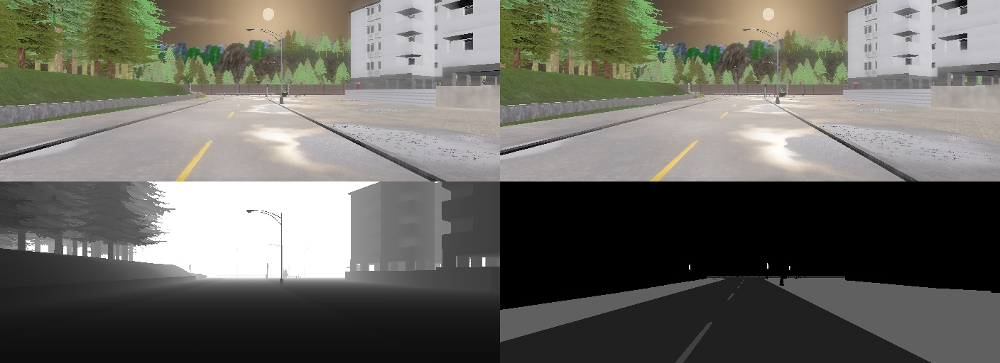

{
 "town": "Town01",
 "sanity": {
  "fps": 17.54,
  "rgb_std": 45.22,
  "depth_min": 3.11,
  "depth_max": 1000.0,
  "passed": true,
  "server": "0.9.16",
  "client": "0.9.16"
 },
 "controller": {
  "mean_cte": 0.03779514147963249,
  "p95_cte": 0.32008993584289536,
  "passed": true
 }
}


In [ ]:
import json
from IPython.display import Image, display

rc = colab.run(py, "gates", cfg)
display(Image(f"{cfg.p.gates}/rig_preview.jpg", width=900))
print(json.dumps(json.load(open(f"{cfg.p.gates}/sanity_controller.json")), indent=1))

In [ ]:
from indiadrive import report

jobs = colab.write_jobs(cfg, [dict(tag="expert_gate", agent="expert", chaos=[0.0, 0.5], seeds=[0],
                                   max_routes=2 if cfg.profile == "smoke" else 4)], "expert_gate")
rc = colab.run(py, "expert-gate", cfg, jobs=jobs)
gate = report.gate_expert(cfg)
colab.kill_carla()
S.done("3_gates", expert_gate=gate)

[expert-gate Town02] profile=smoke
starting CARLA Town02
CARLA up after 17s
booted on Town10HD; loading Town02 on the fresh server (1/3)
CARLA ready on Town02
[expert_gate] Town02: 4 routes to run
terminate called after throwing an instance of 'carla::client::TimeoutException'
  what():  time-out of 120000ms while waiting for the simulator, make sure the simulator is ready and connected to 127.0.0.1:2000
Fatal Python error: Aborted

Thread 0x00007ca6656c2740 (most recent call first):
  File "/content/code/indiadrive/evaluate.py", line 95 in run_route
  File "/content/code/indiadrive/runner.py", line 90 in eval_town
  File "/content/code/indiadrive/runner.py", line 123 in town_work
  File "/content/code/indiadrive/runner.py", line 160 in main
  File "/content/code/indiadrive/runner.py", line 181 in <module>
  File "<frozen runpy>", line 88 in _run_code
  File "<frozen runpy>", line 198 in _run_module_as_main

Extension modules: numpy._core._multiarray_umath, numpy.linalg._umath_linalg, 

## Step 4 · Expert data collection
**Runtime: T4 GPU + High-RAM (L4 also works) · 3–4 h for `colab`, 10 min for `smoke` · ≈4–5 units**

The privileged expert drives every training town (Town01, 03, 04 and 10HD) at every chaos level. Each episode is saved to Drive the moment it finishes, so a disconnect loses at most the episode in progress; re-running the cell resumes.

How each episode is recorded:
- **Traffic:** chaos level k sets the share of two-wheelers and their weaving offsets, the gaps, the jaywalking rate, and scripted events (autos stopping anywhere, buses blocking the lane, wrong-way riders, jaywalking groups, debris, parked cars).
- **Recovery data:** steering noise and physical camera-rig jitter give the student recovery views.
- **Labels:** the expert's executed path (including lane-free nudges), its target speed, and the reason for every brake.
- **Frame filter:** keeps frames where the plan changes, plus 14 % of the rest.

The held-out towns (Town02 and Town05) are never used for data.

In [ ]:
S.require("T4", "L4", ram_gb=40)
from indiadrive import colab

py = colab.setup_sim(cfg, need_torch=False)

RUNTIME OK: L4 (55.5 GB RAM)
Vulkan OK: NVIDIA L4 | NVIDIA
CARLA already installed
simulator Python ready in 0.0 min: ok
simulator setup finished in 1.0 min


In [ ]:
import collections
import glob

rc = colab.run(py, "collect", cfg)
colab.kill_carla()
shards = glob.glob(f"{cfg.p.dataset('expert')}/shards/*.tar")
levels = collections.Counter(os.path.basename(s).split("_")[1] for s in shards)
target = len(cfg.towns_train) * len(cfg.chaos_train) * cfg.episodes_per_level
print(f"{len(shards)} / {target} episodes on Drive | per chaos level: {dict(sorted(levels.items()))}")
S.done("4_collect", episodes=len(shards))

[collect Town01] profile=smoke
starting CARLA Town01
CARLA up after 16s
booted on Town10HD; loading Town01 on the fresh server (1/3)
CARLA ready on Town01
  Town01_k000_e00 k=0.00: 500 frames (302 kept) max_ticks progress 66% 1.5 min (5.5 fps) events {}
  Town01_k000_e01 k=0.00: 500 frames (198 kept) max_ticks progress 68% 1.0 min (8.1 fps) events {}
  Town01_k100_e00 k=1.00: 328 frames (194 kept) collision:static.fence progress 26% 1.5 min (3.7 fps) events {'debris': 2, 'wrong_way': 1, 'bus_stop': 1, 'parked': 1, 'jaywalk': 2}
  Town01_k100_e01 k=1.00: 500 frames (270 kept) max_ticks progress 35% 1.9 min (4.3 fps) events {'bus_stop': 2, 'debris': 1, 'jaywalk': 1, 'parked': 2, 'auto_stop': 1}
[collect Town01] exit code 0 after 6.4 min
[collect] exit code 0 (OK) after 6.4 min
4 / 4 episodes on Drive | per chaos level: {'k000': 2, 'k100': 2}
STEP 4_collect SAVED TO DRIVE | session 0.33 h = ~0.56 compute units on L4


## Step 5 · Build the dataset index
**Runtime: CPU · 5 min · ≈0.01 units**

This step reads only the small label files from Drive, not the images. It writes the train/val split (whole episodes go to validation), the 8 target-speed bins derived from the expert's own speed histogram, and dataset statistics.

**Style audit:** check that the `visible` share of hazard brakes is above about 0.9. A teacher that brakes for things the camera cannot see teaches the student to brake for no visible reason.

In [ ]:
S.require("CPU")
import json
from indiadrive.data import build_index

eps, stats = build_index(cfg)
print(json.dumps(stats, indent=1))

WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
{
 "episodes": 4,
 "frames": 1828,
 "kept": 964,
 "train_kept": 770,
 "val_kept": 194,
 "outcomes": {
  "max_ticks": 3,
  "collision": 1
 },
 "kept_per_chaos": {
  "0.00": 500,
  "1.00": 464
 },
 "style_audit": {
  "hazard_brakes": 5,
  "visible": 1.0,
  "recent": 0.0,
  "near": 0.0,
  "light_brakes": 8
 },
 "speed_bins": [
  0.0,
  0.78,
  1.71,
  2.65,
  4.52,
  5.9,
  7.29,
  8.33
 ]
}


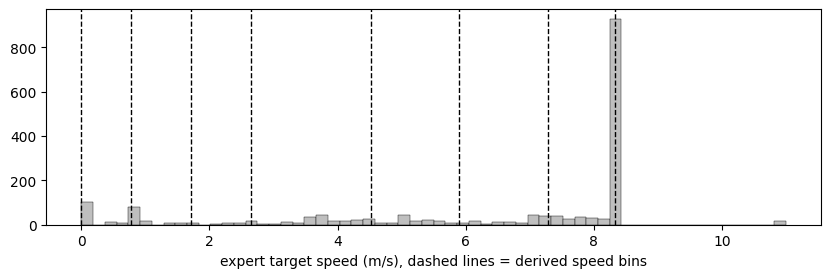

STEP 5_index SAVED TO DRIVE | session 0.33 h = ~0.56 compute units on L4


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

ts = np.load(f"{cfg.p.index}/target_speeds.npy")
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.hist(ts, 60, color="0.75", edgecolor="black", linewidth=0.3)
for b in stats["speed_bins"]:
    ax.axvline(b, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("expert target speed (m/s), dashed lines = derived speed bins")
plt.show()
S.done("5_index", episodes=stats["episodes"], kept=stats["kept"])

## Step 6 · Train the student
**Runtime: L4 GPU (A100 is faster but costs about 3× the units) · 2–3 h for `colab` · ≈4–5 units**

Training runs in the normal Colab Python and does not need CARLA. The first cell copies the episode shards from Drive to the local disk, which takes a few minutes.

- **Stage 1:** perception losses only (depth, semantics, objects, VRU future occupancy).
- **Stage 2:** adds the arc-length path and the 8-bin target speed.
- **Chaos curriculum:** during the first 60 % of stage 2, high-chaos samples are down-weighted. Mirror augmentation turns 30 % of the clips into left-hand traffic.
- **Checkpoints:** saved to Drive every 20 minutes and after every epoch. Re-running the cell resumes from the last checkpoint.

Set `MAX_HOURS` to split training across sessions. On `smoke`, an overfit test first proves the plumbing: it must memorise 100 frames.

In [ ]:
S.require("L4", "A100")
from indiadrive.colab import stage

stage(cfg, datasets=("expert",))

RUNTIME OK: L4 (55.5 GB RAM)
staged 4 episodes (0.2 GB) in 0.0 min | local disk free 170 GB


4

In [ ]:
from indiadrive.train import train, overfit_test

MAX_HOURS = None
if cfg.profile == "smoke":
    overfit_test(cfg)
run_dir = train(cfg, mode="main", max_hours=MAX_HOURS)

0 {'depth': 3.967, 'seg': 2.09, 'obj': 4.927, 'vru': 0.849, 'path': 3.13, 'speed': 2.121, 'total': 13.632}
50 {'depth': 1.828, 'seg': 0.126, 'obj': 0.969, 'vru': 0.0, 'path': 0.628, 'speed': 1.242, 'total': 3.816}
100 {'depth': 1.326, 'seg': 0.067, 'obj': 0.619, 'vru': 0.001, 'path': 0.757, 'speed': 0.733, 'total': 2.807}
150 {'depth': 0.772, 'seg': 0.046, 'obj': 0.342, 'vru': 0.001, 'path': 0.21, 'speed': 0.668, 'total': 1.629}
200 {'depth': 0.577, 'seg': 0.038, 'obj': 0.013, 'vru': 0.001, 'path': 0.244, 'speed': 0.514, 'total': 1.079}
250 {'depth': 0.638, 'seg': 0.038, 'obj': 0.374, 'vru': 0.0, 'path': 0.197, 'speed': 0.602, 'total': 1.511}
path 3.130 -> 0.330 | speed 2.121 -> 0.675 | OVERFIT TEST PASSED
train samples 766 | val samples 193 | steps/epoch 95 | run /content/drive/MyDrive/IndiaDrive/runs/smoke/main
ep 0 st 1 it 1/95 depth=3.920 seg=2.060 obj=5.776 vru=0.765 path=2.404 speed=2.118 total=9.149 | 0.1 min
== epoch 0 val depth=2.163 seg=0.235 obj=3.501 vru=0.303 path=1.078 sp

STEP 6_train SAVED TO DRIVE | session 0.40 h = ~0.68 compute units on L4


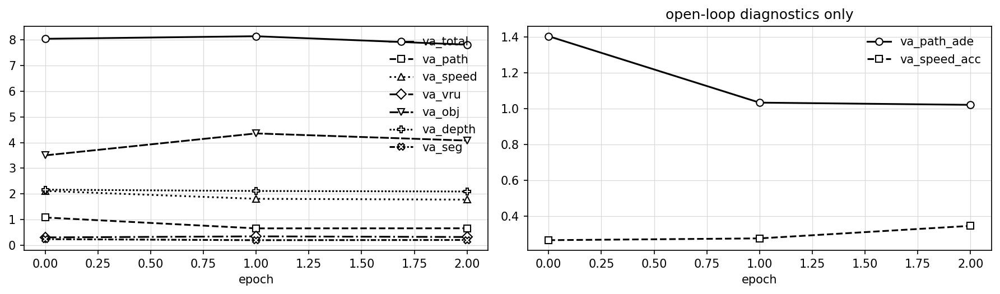

In [ ]:
from indiadrive.report import training_curves

training_curves(run_dir, path=f"{run_dir}/training_curves.png")
S.done("6_train", run=cfg.run)

## Step 7 · Calibrate the safety guard
**Runtime: CPU · 15 min · ≈0.03 units · once per profile**

The guard is not learned. It builds an occupancy grid from classical stereo (OpenCV SGBM) and caps speed so the car can stop before the first occupied cell in its corridor.

Calibration measures, on held-out validation frames, how far stereo depth overestimates the true depth for each class and distance band. It also measures how fast vehicles, two-wheelers and pedestrians move sideways. It stores the split-conformal (1 − α) quantiles with α = 0.05, so the margins carry a 95 % coverage guarantee on this data. The calibration depends only on the data, so every ablation run shares it.

In [ ]:
S.require("CPU")
import pandas as pd
from IPython.display import display
from indiadrive.colab import stage
from indiadrive.data import load_index
from indiadrive.guard import calibrate

stage(cfg, datasets=("expert",), splits=("val",))
dirs = [f"{cfg.p.local_data}/expert/{e['name']}" for e in load_index(cfg)["episodes"] if e["split"] == "val"]
cal = calibrate(cfg, dirs)
bands = [f"{a:g}-{b:g} m" for a, b in zip(cal["dist_edges"][:-1], cal["dist_edges"][1:])]
display(pd.DataFrame(cal["depth"], index=bands).rename_axis("depth margin (m)"))
print("lateral margins (m):", cal["lateral"])
print("missing-detection rate:", cal["missing_rate"])
S.done("7_calibrate")

WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
staged 0 episodes (0.0 GB) in 0.0 min | local disk free 170 GB


,other,vehicle,two_wheeler,pedestrian
depth margin (m),,,,
0-10 m,112.652,0.3,0.300,80.175
10-20 m,112.652,0.8,93.260,88.283
20-30 m,112.652,1.8,95.719,88.283
30-45 m,112.652,3.5,95.719,88.283
45-80 m,112.652,6.0,95.719,88.283


lateral margins (m): {'other': 0.0, 'vehicle': 0.939, 'two_wheeler': 0.748, 'pedestrian': 1.191}
missing-detection rate: {'other': 0.0, 'vehicle': 0.034482758620689655, 'two_wheeler': 0.025974025974025976, 'pedestrian': 0.07777777777777778}
STEP 7_calibrate SAVED TO DRIVE | session 0.40 h = ~0.68 compute units on L4


## Step 8 · Closed-loop evaluation (IndiaBench)
**Runtime: T4 GPU + High-RAM (L4 also works) · 7–9 h for the default plan · ≈8–11 units**

Every job runs on the held-out towns, on fixed routes, at every chaos level. Each route result is saved as soon as it finishes, so the cell can be re-run after a disconnect and continues where it stopped. Choose which jobs to run in `RUN_NOW`.

| Job | What it measures | Seeds |
|---|---|---|
| `student` | Headline chaos sweep for the trained policy | 3 |
| `expert` | Upper bound (privileged teacher) | 1 |
| `blind_zero_image` | Shortcut test: with the image blanked the policy must fail | 1 |
| `scenarios` | Child darting out, occluded pedestrian, jaywalking group, two-wheeler cut-in, wrong-way rider, auto stopping anywhere, bus blocking the lane | 1 |
| `scenarios_expert` | The same scenario suite driven by the expert | 1 |
| `guard_corridor` / `guard_off` / `guard_carla_depth` | Guard ablations | 1 |
| `dagger1`, `dagger2` … | The policy after each DAgger round (Step 9) | 3 |

Reported metrics: driving score, route completion, success rate, two-wheeler and pedestrian collisions per km, near misses per km, guard interventions per km, progress rate, and speed adherence.

In [ ]:
S.require("T4", "L4", ram_gb=40)
from indiadrive import colab

py = colab.setup_sim(cfg, need_torch=True)

RUNTIME OK: L4 (55.5 GB RAM)
Vulkan OK: NVIDIA L4 | NVIDIA
CARLA already installed
simulator Python ready in 0.0 min: torch 2.14.1+cu130 cuda True
simulator setup finished in 0.9 min


In [ ]:
from IPython.display import display
from indiadrive import report

PLAN = colab.eval_plan(cfg)
RUN_NOW = ["student", "expert", "blind_zero_image", "scenarios"]
jobs = colab.write_jobs(cfg, [PLAN[k] for k in RUN_NOW], f"eval_{cfg.run}")
rc = colab.run(py, "eval", cfg, jobs=jobs)
colab.kill_carla()
tags = [PLAN[k]["tag"] for k in RUN_NOW]
display(report.headline(cfg, tags))
report.blind_check(cfg, PLAN["student"]["tag"], PLAN["blind_zero_image"]["tag"])
S.done("8_eval", tags=tags)

[eval Town02] profile=smoke
starting CARLA Town02
CARLA up after 16s
booted on Town10HD; loading Town02 on the fresh server (1/3)
CARLA ready on Town02
[student] Town02: 4 routes to run
  Town02 23-39 s0 k=0.00: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 0 | guard/km 1000.0
  Town02 23-39 s0 k=1.00: DS 0.0 RC 0 agent_blocked | dyn 1 vru 0 near 0 | guard/km 1000.0
  Town02 9-72 s0 k=0.00: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 0 | guard/km 1000.0
  Town02 9-72 s0 k=1.00: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 1 | guard/km 1000.0
[expert] Town02: 4 routes to run
ERROR: failed to destroy actor 441 : time-out of 120000ms while waiting for the simulator, make sure the simulator is ready and connected to 127.0.0.1:2000 
ERROR: failed to destroy actor 442 : time-out of 120000ms while waiting for the simulator, make sure the simulator is ready and connected to 127.0.0.1:2000 
ERROR: failed to destroy actor 443 : time-out of 120000ms while waiting for the simulator, make sure the 

,driving_score,route_completion,success,vru_collisions_per_km,near_miss_per_km,dynamic_infractions,static_infractions,guard_per_km,progress_rate_mps,speed_adherence,routes
student,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,250.00 ± 0.00,0.25 ± 0.00,0.00 ± 0.00,1000.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,4


STEP 8_eval SAVED TO DRIVE | session 1.01 h = ~1.73 compute units on L4


## Step 9 · Failure-targeted DAgger
**Four short parts on four runtimes. Set `ROUND` (1, 2, …) in each cell.**

In each round the student drives new routes in the training towns, with the expert taking over a fraction β of the segments. The privileged expert labels every visited state.

When the student fails, the same route, seed and traffic are replayed with the expert driving:
- **Expert succeeds:** the failure was learnable. The last 10 seconds before the failure are kept with weight 3.
- **Expert also fails:** the episode is dropped, because it cannot be learned from.

The policy is then fine-tuned on expert data plus every DAgger round so far, and evaluated again.

| Part | Runtime | Time | Units |
|---|---|---|---|
| 9a Collect on-policy data | T4 GPU + High-RAM | 1.5–2.5 h | 2–3 |
| 9b Rebuild the index | CPU | 5 min | 0.01 |
| 9c Fine-tune | L4 GPU | 45–60 min | 1.5–2 |
| 9d Evaluate | T4 GPU + High-RAM | 4–5 h | 5–6 |

### 9a · Collect on-policy data · T4 GPU + High-RAM

In [ ]:
ROUND, BETA = 1, 0.3
S.require("T4", "L4", ram_gb=40)
from indiadrive import colab

py = colab.setup_sim(cfg, need_torch=True)
rc = colab.run(py, "dagger", cfg, round=ROUND, beta=BETA)
colab.kill_carla()
S.done(f"9a_dagger_collect_r{ROUND}")

RUNTIME OK: L4 (55.5 GB RAM)
Vulkan OK: NVIDIA L4 | NVIDIA
CARLA already installed
simulator Python ready in 0.0 min: torch 2.14.1+cu130 cuda True
simulator setup finished in 0.9 min
[dagger Town01] profile=smoke
starting CARLA Town01
CARLA up after 16s
booted on Town10HD; loading Town01 on the fresh server (1/3)
CARLA ready on Town01
  Town01_r1_p00 k=0.00: 500 frames (81 kept) max_ticks progress 13% 1.1 min (7.6 fps) events {'parked': 2}
  DAgger Town01_r1_p00: max_ticks -> success
  Town01_r1_p01 k=1.00: 70 frames (19 kept) collision:vehicle.seat.leon progress 0% 0.3 min (3.6 fps) events {'jaywalk': 3, 'debris': 1, 'wrong_way': 1, 'auto_stop': 1}
  DAgger Town01_r1_p01: collision:vehicle.seat.leon -> targeted (70 frames x3.0)
[dagger Town01] exit code 0 after 3.3 min
[dagger] exit code 0 (OK) after 3.3 min
STEP 9a_dagger_collect_r1 SAVED TO DRIVE | session 1.08 h = ~1.85 compute units on L4


### 9b · Rebuild the index · CPU

In [ ]:
ROUND = 1
S.require("CPU")
from indiadrive.data import build_index

eps, stats = build_index(cfg)
print({k: stats[k] for k in ("episodes", "kept", "train_kept", "val_kept", "outcomes")})
S.done(f"9b_dagger_index_r{ROUND}")

WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
{'episodes': 6, 'kept': 1064, 'train_kept': 870, 'val_kept': 194, 'outcomes': {'max_ticks': 4, 'collision': 2}}
STEP 9b_dagger_index_r1 SAVED TO DRIVE | session 1.08 h = ~1.85 compute units on L4


### 9c · Fine-tune · L4 GPU

In [ ]:
ROUND = 1
S.require("L4", "A100")
from indiadrive.colab import stage
from indiadrive.train import train

stage(cfg, datasets=("expert",) + tuple(f"dagger_r{j}" for j in range(1, ROUND + 1)))
run_dir = train(cfg, mode="dagger", round_=ROUND)
S.done(f"9c_dagger_train_r{ROUND}")

RUNTIME OK: L4 (55.5 GB RAM)
staged 2 episodes (0.0 GB) in 0.0 min | local disk free 169 GB
train samples 864 | val samples 193 | steps/epoch 108 | run /content/drive/MyDrive/IndiaDrive/runs/smoke/main_dagger1
initialised from /content/drive/MyDrive/IndiaDrive/runs/smoke/main/best.pt
ep 0 st 2 it 1/108 depth=1.699 seg=0.131 obj=3.211 vru=0.029 path=1.800 speed=3.286 total=9.226 | 0.0 min
ep 0 st 2 it 101/108 depth=1.604 seg=0.091 obj=1.908 vru=0.025 path=0.879 speed=1.296 total=4.942 | 0.6 min
== epoch 0 val depth=2.055 seg=0.179 obj=4.211 vru=0.353 path=0.700 speed=1.649 total=7.853 path_ade=1.085 speed_acc=0.325
STEP 9c_dagger_train_r1 SAVED TO DRIVE | session 1.09 h = ~1.87 compute units on L4


### 9d · Evaluate the fine-tuned policy · T4 GPU + High-RAM

In [ ]:
ROUND = 1
S.require("T4", "L4", ram_gb=40)
from IPython.display import display
from indiadrive import colab, report

py = colab.setup_sim(cfg, need_torch=True)
PLAN = colab.eval_plan(cfg)
jobs = colab.write_jobs(cfg, [PLAN[f"dagger{ROUND}"]], f"eval_dagger{ROUND}_{cfg.run}")
rc = colab.run(py, "eval", cfg, jobs=jobs)
colab.kill_carla()
display(report.headline(cfg, [PLAN["student"]["tag"], PLAN[f"dagger{ROUND}"]["tag"]]))
S.done(f"9d_dagger_eval_r{ROUND}")

RUNTIME OK: L4 (55.5 GB RAM)
Vulkan OK: NVIDIA L4 | NVIDIA
CARLA already installed
simulator Python ready in 0.0 min: torch 2.14.1+cu130 cuda True
simulator setup finished in 0.9 min
[eval Town02] profile=smoke
starting CARLA Town02
CARLA up after 16s
booted on Town10HD; loading Town02 on the fresh server (1/3)
CARLA ready on Town02
[student_dagger1] Town02: 4 routes to run
  Town02 23-39 s0 k=0.00: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 0 | guard/km 1000.0
  Town02 23-39 s0 k=1.00: DS 0.0 RC 0 agent_blocked | dyn 1 vru 0 near 0 | guard/km 1000.0
  Town02 9-72 s0 k=0.00: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 0 | guard/km 1000.0
  Town02 9-72 s0 k=1.00: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 1 | guard/km 1000.0
[eval Town02] exit code 0 after 9.2 min
[eval] exit code 0 (OK) after 9.2 min


,driving_score,route_completion,success,vru_collisions_per_km,near_miss_per_km,dynamic_infractions,static_infractions,guard_per_km,progress_rate_mps,speed_adherence,routes
student,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,250.00 ± 0.00,0.25 ± 0.00,0.00 ± 0.00,1000.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,4
student_dagger1,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,250.00 ± 0.00,0.25 ± 0.00,0.00 ± 0.00,1000.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,4


STEP 9d_dagger_eval_r1 SAVED TO DRIVE | session 1.26 h = ~2.16 compute units on L4


## Step 10 · Report
**Runtime: CPU · 5 min · ≈0.01 units**

This step collects every evaluation tag into `MyDrive/IndiaDrive/reports/<profile>/`:
- `headline.csv` and `headline.tex`: mean ± std over seeds.
- One chaos-sweep table per tag.
- The scenario table.
- Black-and-white figures in PNG and PDF, ready for the paper: driving score vs chaos, and VRU collisions vs chaos.

WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
report written to /content/drive/MyDrive/IndiaDrive/reports/smoke


# Closed-loop results

profile `smoke` | towns Town02 | seeds [0]

## Headline (mean ± std over seeds)

|                 | driving_score   | route_completion   | success     | vru_collisions_per_km   | near_miss_per_km   | dynamic_infractions   | static_infractions   | guard_per_km   | progress_rate_mps   | speed_adherence   |   routes |
|:----------------|:----------------|:-------------------|:------------|:------------------------|:-------------------|:----------------------|:---------------------|:---------------|:--------------------|:------------------|---------:|
| student         | 0.00 ± 0.00     | 0.00 ± 0.00        | 0.00 ± 0.00 | 0.00 ± 0.00             | 250.00 ± 0.00      | 0.25 ± 0.00           | 0.00 ± 0.00          | 1000.00 ± 0.00 | 0.00 ± 0.00         | 0.00 ± 0.00       |        4 |
| student_dagger1 | 0.00 ± 0.00     | 0.00 ± 0.00        | 0.00 ± 0.00 | 0.00 ± 0.00             | 250.00 ± 0.00      | 0.25 ± 0.00           | 0.00 ± 0.00          | 1000.00 ± 0.00 | 0.00 ± 0.00         | 0.00 ± 0.00       |        4 |

## student: by chaos level

|   chaos |   driving_score (mean) |   driving_score (std) |   route_completion (mean) |   route_completion (std) |   success (mean) |   success (std) |   vru_collisions_per_km (mean) |   vru_collisions_per_km (std) |   near_miss_per_km (mean) |   near_miss_per_km (std) |   dynamic_infractions (mean) |   dynamic_infractions (std) |   static_infractions (mean) |   static_infractions (std) |   guard_per_km (mean) |   guard_per_km (std) |   progress_rate_mps (mean) |   progress_rate_mps (std) |   speed_adherence (mean) |   speed_adherence (std) |
|--------:|-----------------------:|----------------------:|--------------------------:|-------------------------:|-----------------:|----------------:|-------------------------------:|------------------------------:|--------------------------:|-------------------------:|-----------------------------:|----------------------------:|----------------------------:|---------------------------:|----------------------:|---------------------:|---------------------------:|--------------------------:|-------------------------:|------------------------:|
|       0 |                      0 |                     0 |                         0 |                        0 |                0 |               0 |                              0 |                             0 |                         0 |                        0 |                          0   |                           0 |                           0 |                          0 |                  1000 |                    0 |                          0 |                         0 |                    0     |                       0 |
|       1 |                      0 |                     0 |                         0 |                        0 |                0 |               0 |                              0 |                             0 |                       500 |                        0 |                          0.5 |                           0 |                           0 |                          0 |                  1000 |                    0 |                          0 |                         0 |                    0.009 |                       0 |

## student_dagger1: by chaos level

|   chaos |   driving_score (mean) |   driving_score (std) |   route_completion (mean) |   route_completion (std) |   success (mean) |   success (std) |   vru_collisions_per_km (mean) |   vru_collisions_per_km (std) |   near_miss_per_km (mean) |   near_miss_per_km (std) |   dynamic_infractions (mean) |   dynamic_infractions (std) |   static_infractions (mean) |   static_infractions (std) |   guard_per_km (mean) |   guard_per_km (std) |   progress_rate_mps (mean) |   progress_rate_mps (std) |   speed_adherence (mean) |   speed_adherence (std) |
|--------:|-----------------------:|----------------------:|--------------------------:|-------------------------:|-----------------:|----------------:|-------------------------------:|------------------------------:|--------------------------:|-------------------------:|-----------------------------:|----------------------------:|----------------------------:|---------------------------:|----------------------:|---------------------:|---------------------------:|--------------------------:|-------------------------:|------------------------:|
|       0 |                      0 |                     0 |                         0 |                        0 |                0 |               0 |                              0 |                             0 |                         0 |                        0 |                          0   |                           0 |                           0 |                          0 |                  1000 |                    0 |                          0 |                         0 |                    0     |                       0 |
|       1 |                      0 |                     0 |                         0 |                        0 |                0 |               0 |                              0 |                             0 |                       500 |                        0 |                          0.5 |                           0 |                           0 |                          0 |                  1000 |                    0 |                          0 |                         0 |                    0.009 |                       0 |


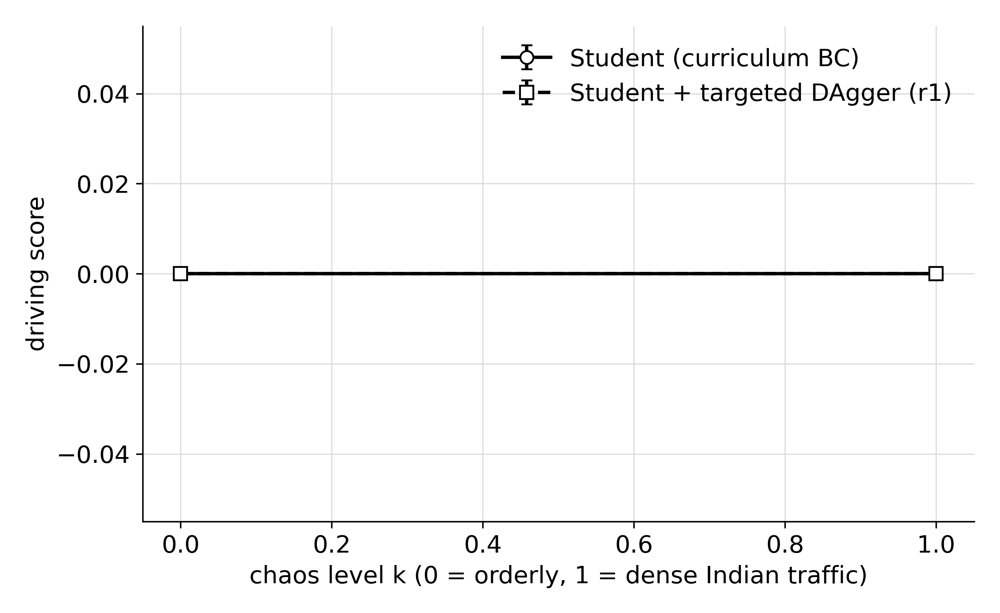

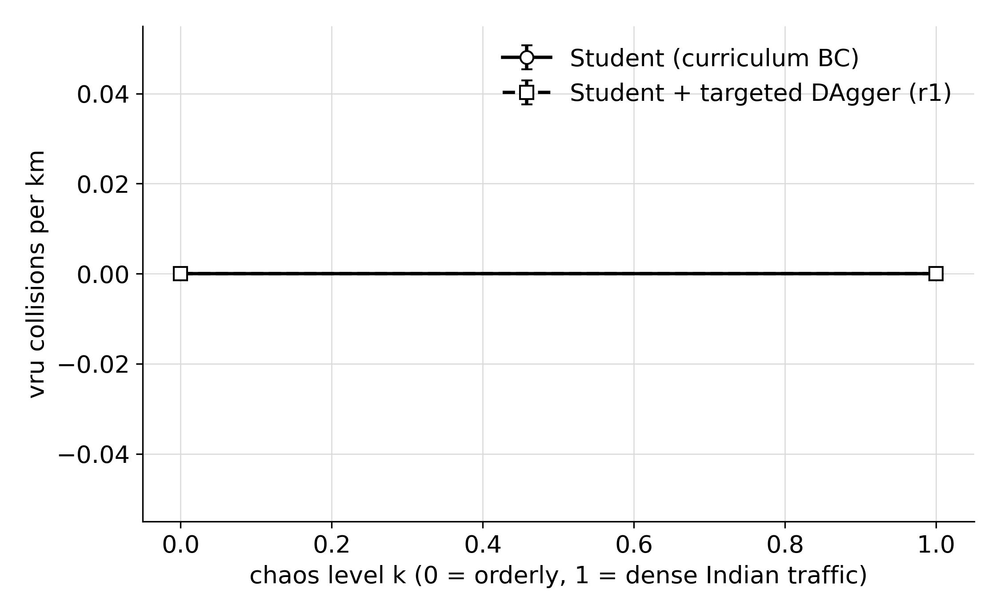

STEP 10_report SAVED TO DRIVE | session 1.26 h = ~2.16 compute units on L4


In [ ]:
S.require("CPU")
from IPython.display import Image, Markdown, display
from indiadrive import report

tags = [t for t in report.list_tags(cfg) if t != "expert_gate" and not t.startswith("demo_")]
labels = {"expert": "Expert (privileged)", "student": "Student (curriculum BC)",
          "student_dagger1": "Student + targeted DAgger (r1)", "student_dagger2": "Student + targeted DAgger (r2)",
          "guard_corridor": "Corridor guard", "guard_off": "No guard", "guard_carla_depth": "Guard on true depth"}
md_path = report.write_report(cfg, tags, labels)
display(Markdown(open(md_path).read()))
display(Image(f"{cfg.p.reports}/fig_chaos_ds.png", width=820))
display(Image(f"{cfg.p.reports}/fig_chaos_vru.png", width=820))
S.done("10_report")

0_project              -
1_code                 done 2026-10-16 21:12 on L4
2_carla_cache          done 2026-10-16 21:12 on L4
3_gates                done 2026-10-16 21:24 on L4
4_collect              done 2026-10-16 21:31 on L4
5_index                done 2026-10-16 21:31 on L4
6_train                done 2026-10-16 21:36 on L4
7_calibrate            done 2026-10-16 21:36 on L4
8_eval                 done 2026-10-16 22:12 on L4
9_dagger               -
10_report              done 2026-10-16 22:27 on L4
9a_dagger_collect_r1   done 2026-10-16 22:16 on L4
9b_dagger_index_r1     done 2026-10-16 22:16 on L4
9c_dagger_train_r1     done 2026-10-16 22:17 on L4
9d_dagger_eval_r1      done 2026-10-16 22:27 on L4

compute units used so far (smoke): 14.5


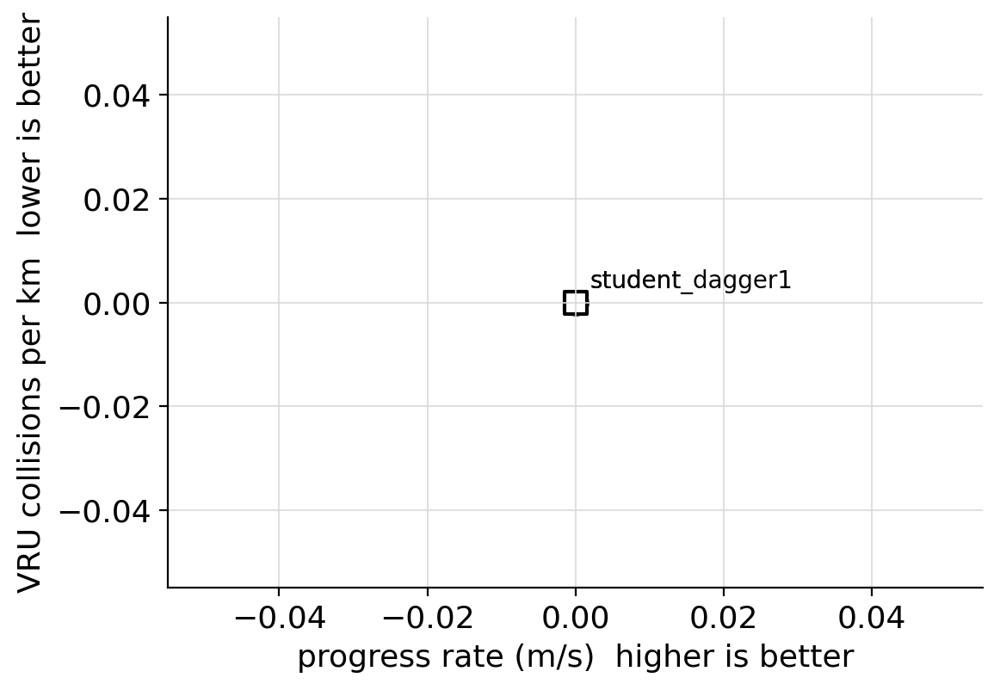

In [ ]:
report.guard_tradeoff(cfg, [t for t in tags if t.startswith(("student", "guard"))],
                      path=f"{cfg.p.reports}/fig_guard_tradeoff.png")
S.status()

## Step 11 · Visualisations: dataset, driving videos, before vs after training
Two parts:

| Part | Runtime | Time | Units | Produces |
|---|---|---|---|---|
| 11a Dataset gallery | CPU | 5–10 min | ≈0.01 | One image grid of recorded frames per chaos level, plus a 30-second clip per level |
| 11b Driving videos | T4 GPU + High-RAM | 30–60 min | ≈1 | One video per agent and a side-by-side comparison video |

**11a:** every frame shows what the expert recorded: the front camera with the expert's planned path (green), its speed, target speed, brake reason and lane-free nudge, and a bird's-eye panel with vehicles (blue), two-wheelers (orange), pedestrians (red) and obstacles (grey).

**11b:** the same held-out route, with the same seed and traffic, is driven at chaos 0.5 and 1.0 by every agent that exists on Drive:
1. Before training: the untrained network.
2. Trained on orderly traffic only: the `chaos0_only` ablation, if you trained it.
3. The trained student.
4. After targeted DAgger, if Step 9 was run.
5. The privileged expert.

Each video has a third-person chase camera, a heads-up display (speed, plan speed, collisions, near misses, guard activity), the front camera with the predicted path (green) against the expert path (white), and a bird's-eye panel that turns red when the safety guard intervenes. The individual videos are then combined into one comparison video per route and chaos level. Agents without a checkpoint are skipped automatically.

All files are saved in `MyDrive/IndiaDrive/reports/<profile>/videos/` as H.264 MP4, so they play directly in slides and browsers.

### 11a · Dataset gallery and clips · CPU

WRONG RUNTIME: this step wants CPU, you are on L4 (55.5 GB).
Runtime > Change runtime type, then run Section 0 again.
staged 0 episodes (0.0 GB) in 0.0 min | local disk free 169 GB


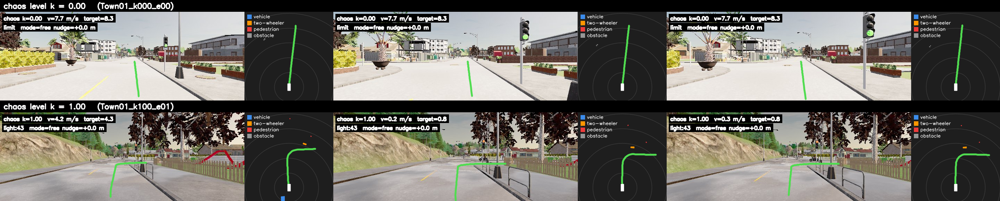

STEP 11a_gallery SAVED TO DRIVE | session 1.26 h = ~2.16 compute units on L4


In [ ]:
S.require("CPU")
from IPython.display import Image, display
from indiadrive import viz
from indiadrive.colab import stage
from indiadrive.data import load_index

episodes = [e for e in load_index(cfg)["episodes"] if e["dataset"] == "expert"]
pick = {}
for e in sorted(episodes, key=lambda e: -e["kept"]):
    pick.setdefault(round(e["chaos"], 2), e["name"])
stage(cfg, datasets=("expert",), names=set(pick.values()))
dirs = [f"{cfg.p.local_data}/expert/{n}" for n in pick.values()]
png, clips = viz.dataset_gallery(cfg, dirs, f"{cfg.p.reports}/dataset_gallery.png",
                                 clip_dir=f"{cfg.p.reports}/videos/dataset")
display(Image(png, width=1100))
if clips:
    viz.show_video(clips[-1], width=900)
S.done("11a_gallery")

### 11b · Driving videos: before vs after training · T4 GPU + High-RAM

In [ ]:
S.require("T4", "L4", ram_gb=40)
from indiadrive import colab, viz

py = colab.setup_sim(cfg, need_torch=True)
DEMO = colab.demo_plan(cfg, chaos=(0.5, 1.0), dagger_round=1)
jobs = colab.write_jobs(cfg, DEMO, "demo")
rc = colab.run(py, "eval", cfg, jobs=jobs)
colab.kill_carla()
videos = colab.compile_demos(cfg, DEMO)
if videos:
    viz.show_video(videos[-1], width=1000)

RUNTIME OK: L4 (55.5 GB RAM)
Vulkan OK: NVIDIA L4 | NVIDIA
CARLA already installed
simulator Python ready in 0.0 min: torch 2.14.1+cu130 cuda True
simulator setup finished in 0.9 min
[eval Town02] profile=smoke
starting CARLA Town02
CARLA up after 16s
booted on Town10HD; loading Town02 on the fresh server (1/3)
CARLA ready on Town02
[demo_untrained] Town02: 2 routes to run
  Town02 23-39 s0 k=0.50: DS 0.2 RC 0 agent_blocked | dyn 0 vru 0 near 0 | guard/km 129957.6
  Town02 23-39 s0 k=1.00: DS 0.1 RC 0 agent_blocked | dyn 1 vru 0 near 0 | guard/km 28748.4
[demo_chaos0_only] Town02: 2 routes to run
[demo_chaos0_only] skipped: no checkpoint in /content/drive/MyDrive/IndiaDrive/runs/smoke/chaos0_only: run the training step first
[demo_student] Town02: 2 routes to run
  Town02 23-39 s0 k=0.50: DS 0.0 RC 0 agent_blocked | dyn 0 vru 0 near 0 | guard/km 1000.0
  Town02 23-39 s0 k=1.00: DS 0.0 RC 0 agent_blocked | dyn 1 vru 0 near 0 | guard/km 1000.0
[demo_dagger1] Town02: 2 routes to run
  Tow

STEP 11b_videos SAVED TO DRIVE | session 1.64 h = ~2.80 compute units on L4


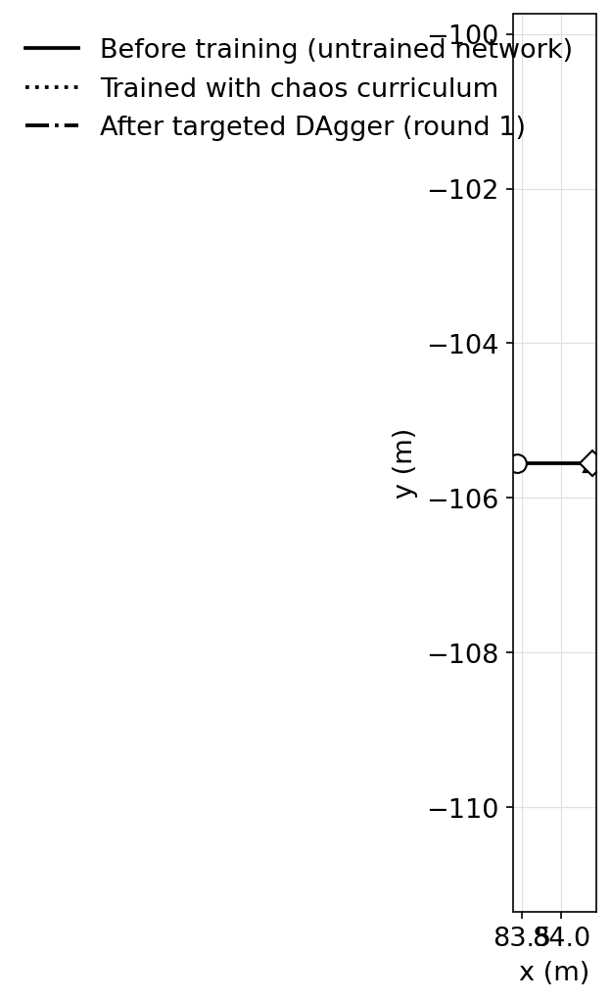

In [ ]:
viz.trajectory_plot(cfg, [j["tag"] for j in DEMO], chaos=1.0, path=f"{cfg.p.reports}/fig_demo_trajectories.png",
                    labels={j["tag"]: j["label"] for j in DEMO})
S.done("11b_videos", videos=len(videos))

## Appendix A · Ablations

Training ablations re-run only Step 6 (L4) and Step 8 (T4). They reuse the same data, index and guard calibration. To run one:
1. Set `RUN` in Section 0 to one of the names below and run Section 0.
2. Run Step 6.
3. Run Step 8 with `RUN_NOW = ["student"]`. You can lower the cost by editing `PLAN["student"]["seeds"] = [0]`. Results are saved under the tag `student_<RUN>`.
4. Set `RUN = "main"` again and run Step 10, which picks up every tag.

| `RUN` | What changes | Question it answers |
|---|---|---|
| `no_vru_head` | VRU future-occupancy head removed | Does anticipating two-wheelers and pedestrians help? |
| `no_curriculum` | Uniform sampling over chaos levels | Does the easy-to-hard curriculum help? |
| `no_mirror` | No mirror augmentation | Effect on left-hand-traffic robustness |
| `no_memory` | No streaming memory | Does temporal context help? |
| `no_ego_dropout` | Ego speed is never dropped | Ego-status shortcut |
| `queries_128` | 128 instead of 256 bus queries | Size of the scene representation |
| `chaos0_only` | Trained only on orderly traffic (k = 0) | **The key baseline:** how much does Indian-traffic training buy? |

Evaluation-only ablations need no training. Add `guard_corridor`, `guard_off` or `guard_carla_depth` to `RUN_NOW` in Step 8.

## Appendix B · Troubleshooting

| Symptom | Cause | Fix |
|---|---|---|
| `WRONG RUNTIME` banner | The step was started on the wrong runtime | Runtime → Change runtime type, then Section 0 |
| `Vulkan does not see the NVIDIA GPU` | Colab image change | Send the printed diagnostics; the setup cell extracts the user-space driver that matches `nvidia-smi` |
| Exit code 137 | Out of RAM | Turn on High-RAM |
| Exit code 134 / 139, or `CARLA server DOWN` | The simulator crashed | Re-run the cell: finished episodes and routes are skipped |
| `no staged episodes` | The staging cell was skipped | Run the first cell of the step |
| Disconnect during a long step | Colab session limits | Section 0, then the same step: it resumes from Drive |
| Drive full | Data or CARLA cache too large | Delete `cache/CARLA_0.9.16.tar.gz` (GPU steps then download CARLA instead) or use the `smoke` profile |
| `EXPERT GATE FAILED` | The teacher is too weak | Inspect `eval/<profile>/expert_gate/*.json` (each holds infractions and a trace) before collecting |

## Appendix C · Simulator facts this notebook relies on
- **Engine and Python:** CARLA 0.9.16, Unreal Engine 4.26. The `carla` wheel exists only for Python 3.10–3.12, so when Colab's Python is newer the simulator runs in a separate Python 3.12 environment.
- **Rendering:** headless through Vulkan with `-RenderOffScreen` and `-quality-level=Low`, which removes shadows and post-processing and limits the draw distance to 50 m.
- **Timing:** synchronous mode at 20 Hz physics (`fixed_delta_seconds = 0.05`) with sub-stepping, logged at 10 Hz.
- **Maps:** the server boots directly on the needed `_Opt` map, because switching maps inside a running server crashes it on Colab. Each town runs in its own process.
- **Left-hand traffic:** set per road (`rule="LHT"` in OpenDRIVE). Here it comes from mirror augmentation, plus the optional `lht_twin` road-only map.
- **Not used:** CARLA 0.10 (Unreal Engine 5) needs at least 16 GB of VRAM, and its Cosmos-Transfer integration needs datacenter GPUs, so neither runs here.